In [15]:
import os
import pickle
from itertools import product

import numpy as np
import matplotlib.pyplot as plt

import astropy.table as at
import astropy.units as u
import astropy.coordinates as coord
from astropy.table import Table
from astropy.coordinates import SkyCoord, Distance

import jax
import jax.numpy as jnp
import jax.random as jr

import numpyro
import numpyro.distributions as dist
import numpyro.infer as infer

from scipy.stats import binned_statistic
from scipy.optimize import brentq
from tqdm import tqdm

import emcee

jax.config.update("jax_enable_x64", True)
%matplotlib inline

In [3]:
t = Table.read("../data/astraAllStarASPCAP-0.8.fits.gz", format="fits", hdu=2)
t["sdss4_apogee_id"] = t["sdss4_apogee_id"].filled(-1)

dr17 = Table.read("../data/allStarLite-dr17-synspec_rev1.fits", hdu=1)
t = at.join(
    t,
    dr17["APOGEE_ID", "SNR", "VHELIO_AVG"],
    keys_left="sdss4_apogee_id",
    keys_right="APOGEE_ID",
    join_type="left",
)
print("loaded t:", len(t))

from src.selection import build_prechem_selection

master_mask, sel_diag, sel_arrays = build_prechem_selection(t)
t_sel = t[master_mask]
print("pre-chem selected:", sel_diag["prechem_selected"])

loaded t: 2576187
pre-chem selected: 630079


In [260]:
print("after joining DR17 (parent sample):", len(t))
print("  with a DR17 match (non-masked SNR):", int((~np.ma.getmaskarray(t["SNR"])).sum()))
print("  without a DR17 match:", int(np.ma.getmaskarray(t["SNR"]).sum()))

after joining DR17 (parent sample): 2576187
  with a DR17 match (non-masked SNR): 607655
  without a DR17 match: 1968532


In [261]:
def origin_split(table, label):
    in_dr17 = ~np.ma.getmaskarray(table["APOGEE_ID"])          # matched in the DR17 join
    has_sdss4_id = np.asarray(table["sdss4_apogee_id"]) != -1   # has an SDSS-IV id in Astra
    n = len(table)
    print(f"{label}: {n:,}")
    print(f"  DR17 match      : {in_dr17.sum():>10,}  ({100*in_dr17.mean():.1f}%)")
    print(f"  MWM only        : {(~in_dr17).sum():>10,}  ({100*(~in_dr17).mean():.1f}%)")
    print(f"  has sdss4 id but no DR17 match: {(has_sdss4_id & ~in_dr17).sum():,}")

origin_split(t, "parent sample")
origin_split(t_sel, "after pre-chemistry cuts")   # use the table you have after build_prechem_selection
origin_split(t_final, "final sample")

# where do S/N and radial velocity actually come from for the final sample?
astra_snr_ok = np.isfinite(np.ma.filled(t_final["snr"].astype(float), np.nan))
astra_rv_ok  = np.isfinite(np.ma.filled(t_final["v_rad"].astype(float), np.nan))
print(f"\nfinal sample: S/N from Astra snr: {astra_snr_ok.sum():,}, fallback to DR17 SNR: {(~astra_snr_ok).sum():,}")
print(f"final sample: v_rad from Astra: {astra_rv_ok.sum():,}, fallback to DR17 VHELIO_AVG: {(~astra_rv_ok).sum():,}")

parent sample: 2,576,187
  DR17 match      :    607,655  (23.6%)
  MWM only        :  1,968,532  (76.4%)
  has sdss4 id but no DR17 match: 1,968,532
after pre-chemistry cuts: 459,435
  DR17 match      :    130,157  (28.3%)
  MWM only        :    329,278  (71.7%)
  has sdss4 id but no DR17 match: 329,278
final sample: 391,384
  DR17 match      :    112,173  (28.7%)
  MWM only        :    279,211  (71.3%)
  has sdss4 id but no DR17 match: 279,211

final sample: S/N from Astra snr: 241,190, fallback to DR17 SNR: 150,194
final sample: v_rad from Astra: 241,190, fallback to DR17 VHELIO_AVG: 150,194


In [262]:
vr   = np.ma.filled(t_final["v_rad"].astype(float), np.nan)
vhel = np.ma.filled(t_final["VHELIO_AVG"].astype(float), np.nan)
pmra = np.ma.filled(t_final["pmra"].astype(float), np.nan)
pmde = np.ma.filled(t_final["pmde"].astype(float), np.nan)

print("t_final size                          :", len(t_final))
print("neither v_rad nor VHELIO_AVG (expect 0):", int((~np.isfinite(vr) & ~np.isfinite(vhel)).sum()))
print("missing a proper motion (expect 0)     :", int((~np.isfinite(pmra) | ~np.isfinite(pmde)).sum()))
print("v_rad missing but VHELIO_AVG present   :", int((~np.isfinite(vr) & np.isfinite(vhel)).sum()))
print("star_pack size                         :", len(star_pack['R_star']))

t_final size                          : 391384
neither v_rad nor VHELIO_AVG (expect 0): 38022
missing a proper motion (expect 0)     : 0
v_rad missing but VHELIO_AVG present   : 112172
star_pack size                         : 389480


In [263]:
from src.utils import col_to_float_array
v = col_to_float_array(t_final, "v_rad")
masked = np.ma.getmaskarray(t_final["v_rad"])
print("finite after col_to_float_array:", int(np.isfinite(v).sum()), "of", len(v))
print("values where v_rad is masked   :", v[masked][:10])

finite after col_to_float_array: 241190 of 391384
values where v_rad is masked   : [nan nan nan nan nan nan nan nan nan nan]


In [264]:
import astropy.units as u, astropy.coordinates as coord
from astropy.coordinates import SkyCoord, Distance
from src.utils import col_to_float_array

s = t_final[:1000]
ra, dec = col_to_float_array(s, "ra"), col_to_float_array(s, "dec")
dist = Distance((1000.0 / col_to_float_array(s, "zgr_plx")) * u.pc)
frame = coord.Galactocentric(galcen_distance=8.275*u.kpc,
                             galcen_v_sun=[8, 254, 8]*u.km/u.s, z_sun=0*u.pc)

c_pos = SkyCoord(ra=ra*u.deg, dec=dec*u.deg, distance=dist).transform_to(frame)
c_pm_nan = SkyCoord(ra=ra*u.deg, dec=dec*u.deg, distance=dist,
                    pm_ra_cosdec=np.full(len(s), np.nan)*u.mas/u.yr,
                    pm_dec=np.full(len(s), np.nan)*u.mas/u.yr,
                    radial_velocity=np.full(len(s), np.nan)*u.km/u.s).transform_to(frame)

print("same x,y,z with all-NaN velocities:",
      np.allclose(c_pos.x.value, c_pm_nan.x.value, equal_nan=False),
      np.allclose(c_pos.y.value, c_pm_nan.y.value, equal_nan=False),
      np.allclose(c_pos.z.value, c_pm_nan.z.value, equal_nan=False))

same x,y,z with all-NaN velocities: True True True


In [265]:
from src.selection import build_prechem_selection

t2 = t.copy()
for col in ["pmra", "pmde", "v_rad"]:
    t2[col] = np.zeros(len(t2))          # finite everywhere, so kin_mask only tests ra and dec
t2["VHELIO_AVG"] = np.zeros(len(t2))

mask_all, diag_all, _ = build_prechem_selection(t)
mask_nopm, diag_nopm, _ = build_prechem_selection(t2)

print("pre-chemistry selected, as now          :", int(mask_all.sum()))
print("pre-chemistry selected, no pm/rv needed :", int(mask_nopm.sum()))
print("stars lost to the pm/rv requirement     :", int(mask_nopm.sum() - mask_all.sum()))

pre-chemistry selected, as now          : 630079
pre-chemistry selected, no pm/rv needed : 630101
stars lost to the pm/rv requirement     : 22


In [266]:
import numpy as np

plx  = col_to_float_array(t_final, "zgr_plx")     # mas
eplx = col_to_float_array(t_final, "zgr_e_plx")   # mas

ok = np.isfinite(plx) & np.isfinite(eplx) & (plx > 0)
d      = 1.0 / plx[ok]                 # kpc, if plx is in mas
sig_d  = eplx[ok] / plx[ok]**2         # kpc, first-order propagation
frac   = eplx[ok] / plx[ok]            # fractional distance uncertainty

print(f"N stars: {ok.sum()}")
print(f"median distance:        {np.median(d):.2f} kpc")
print(f"sigma_d  median / 95th: {np.median(sig_d):.3f} / {np.percentile(sig_d, 95):.3f} kpc")
print(f"fractional median / 95th: {100*np.median(frac):.1f}% / {100*np.percentile(frac, 95):.1f}%")

N stars: 391384
median distance:        2.02 kpc
sigma_d  median / 95th: 0.056 / 0.526 kpc
fractional median / 95th: 2.8% / 9.5%


In [267]:
import numpy as np

fe   = col_to_float_array(t_final, "fe_h")
mg   = col_to_float_array(t_final, "mg_h")
efe  = col_to_float_array(t_final, "e_fe_h")
emg  = col_to_float_array(t_final, "e_mg_h")

mgfe     = mg - fe
mgfe_err = np.sqrt(emg**2 + efe**2)
ok = np.isfinite(mgfe) & np.isfinite(mgfe_err) & (mgfe_err > 0)

print(f"N stars with valid error: {ok.sum()} of {len(t_final)}")
print(f"per-star [Mg/Fe] error  median / 68th / 95th: "
      f"{np.median(mgfe_err[ok]):.3f} / {np.percentile(mgfe_err[ok],68):.3f} / "
      f"{np.percentile(mgfe_err[ok],95):.3f} dex")
print(f"  e_fe_h  median: {np.nanmedian(efe[ok]):.3f}   e_mg_h median: {np.nanmedian(emg[ok]):.3f}")

# what the fits actually see: error on the mean in a typical z bin
# (use your bin_one output, or approximate with N stars per bin)
n_typ = 15   # your minimum stars per cell; replace with a typical bin count
print(f"error on a bin mean for N={n_typ}: ~{np.median(mgfe_err[ok])/np.sqrt(n_typ):.3f} dex")

N stars with valid error: 380278 of 391384
per-star [Mg/Fe] error  median / 68th / 95th: 0.004 / 0.006 / 0.010 dex
  e_fe_h  median: 0.002   e_mg_h median: 0.004
error on a bin mean for N=15: ~0.001 dex


In [5]:
feh_min_extra = -.9

extra_mask = np.asarray(fe) > feh_min_extra
t_sel = t_sel[extra_mask]
fe   = np.asarray(fe)[extra_mask]
mgfe = np.asarray(mgfe)[extra_mask]

print(f"after additional [Fe/H] > {feh_min_extra} cut:", len(t_sel))

after additional [Fe/H] > -0.9 cut: 459435


In [6]:
from src.chemistry import apply_alfe_mgmn_polygon_cut

t_final, final_diag, final_arrays = apply_alfe_mgmn_polygon_cut(t_sel)
print("t_final size:", final_diag["output_size"])

t_final size: 391384


In [7]:
from src.coords import build_star_pack_zsun0
star_pack, star_diag = build_star_pack_zsun0(t_final, rmax_keep=16, plx_min=None)

R_star    = star_pack["R_star"]
Z_star    = star_pack["Z_star"]
phi_star  = star_pack["phi_star"]
mgfe_star = star_pack["mgfe_star"]
t_star    = star_pack["t_star"]

In [8]:
from src.coords import build_segment_setup
from src.utils import col_to_float_array

segm, crowd_bounds, window_edges, seg_diag = build_segment_setup(
    phi_star, phi0=np.pi, crowd_halfwidth_deg=45, n_crowd=11
)
SEG_PLOT_heat = list(range(1, seg_diag["n_crowd"] + 1))

e_mg_h_star = col_to_float_array(t_star, "e_mg_h")
e_fe_h_star = col_to_float_array(t_star, "e_fe_h")
mgfe_err_star = np.sqrt(np.asarray(e_mg_h_star, float)**2 + np.asarray(e_fe_h_star, float)**2)

print("star_pack final size:", star_diag["final_size"])

star_pack final size: 389480


In [9]:
z_edges    = np.linspace(-3.0, 3.0, 181)
mgfe_edges = np.linspace(-0.2, 0.6, 161)
R_edges    = np.arange(0.5, 15.5 + 0.5, 0.5)

minN_seg_total   = 15
min_bin_count    = 5
min_bins_for_fit = 8
z_fit_min, z_fit_max = -1.5, 1.5
zlim = 0.6

R_centers = 0.5 * (R_edges[:-1] + R_edges[1:])

In [10]:
def mixture_of_sech2(z, A1, A2, h1, h2, z0):
    dz = z - z0
    return A1 * (1 / jnp.cosh(dz / h1)) ** 2 + A2 * (1 / jnp.cosh(dz / h2)) ** 2

def model(data):
    _A1 = numpyro.sample("_A1", dist.HalfNormal(.2))
    _A2 = numpyro.sample("_A2", dist.HalfNormal(0.2))
    A1 = numpyro.deterministic("A1", -_A1)
    A2 = numpyro.deterministic("A2", -_A2)

    h1   = numpyro.sample("h1",   dist.Uniform(0.04, 1.0))
    d_h2 = numpyro.sample("d_h2", dist.Uniform(0.04, .75))
    h2 = numpyro.deterministic("h2", h1 + d_h2)

    z0 = numpyro.sample("z0", dist.Normal(0.0, 0.2))
    offset = numpyro.sample("offset", dist.Normal(0.0, 0.2))

    model_y = mixture_of_sech2(data["z"], A1, A2, h1, h2, z0) + offset

    Q = numpyro.deterministic("Q", 0.0)
    mix = dist.Categorical(probs=jnp.array([Q, 1.0 - Q]))
    components = [
        dist.Normal(0.0, jnp.sqrt(1.0**2 + data["mg_fe_err"]**2)),
        dist.Normal(model_y, data["mg_fe_err"]),
    ]
    numpyro.sample("obs", dist.Mixture(mix, components), obs=data["mg_fe"])

In [11]:
Z_BINS_FIT = np.arange(-5, 5 + 1e-3, 0.1)

def bin_one(z, mgfe, mgfe_err, z_bins=Z_BINS_FIT):
    stat1 = binned_statistic(z, mgfe / mgfe_err**2, bins=z_bins, statistic="sum")
    stat2 = binned_statistic(z, 1 / mgfe_err**2, bins=z_bins, statistic="sum")
    stat_std = binned_statistic(z, mgfe, bins=z_bins, statistic="std")
    stat_count = binned_statistic(z, mgfe, bins=z_bins, statistic="count")

    intrinsic_scatter = stat_std.statistic / np.sqrt(stat_count.statistic)
    mean_mg_fe = stat1.statistic / stat2.statistic
    mean_mg_fe_err = np.sqrt(1 / stat2.statistic + intrinsic_scatter**2)
    z_binc = 0.5 * (z_bins[1:] + z_bins[:-1])
    counts = stat_count.statistic
    return z_binc, mean_mg_fe, mean_mg_fe_err, counts

def fit_sech2(z_binc, mean_mg_fe, mean_mg_fe_err, key,
              num_warmup=1000, num_samples=1000, num_chains=2, progress_bar=False):
    sampler = infer.MCMC(
        infer.NUTS(model, dense_mass=True, target_accept_prob=0.95,
                   init_strategy=infer.init_to_median(num_samples=20)),
        num_warmup=num_warmup, num_samples=num_samples,
        num_chains=num_chains, progress_bar=progress_bar,
    )
    data = {
        "z": jnp.asarray(z_binc),
        "mg_fe": jnp.asarray(mean_mg_fe),
        "mg_fe_err": jnp.asarray(mean_mg_fe_err),
    }
    sampler.run(key, data=data)
    return sampler

def select_annulus_segment(R_use, Z_use, mgfe_use, mgfe_err_use, seg_mask, Rmin, Rmax,
                            min_bin_count=min_bin_count, min_bins_for_fit=min_bins_for_fit,
                            z_fit_min=z_fit_min, z_fit_max=z_fit_max):
    m = (seg_mask & (R_use >= Rmin) & (R_use < Rmax)
         & np.isfinite(Z_use) & np.isfinite(mgfe_use)
         & np.isfinite(mgfe_err_use) & (mgfe_err_use > 0))
    n_stars = int(m.sum())
    if n_stars < minN_seg_total:
        return None, None, None, n_stars, False

    z_binc, mean_mg_fe, mean_mg_fe_err, counts = bin_one(Z_use[m], mgfe_use[m], mgfe_err_use[m])
    good = (np.isfinite(mean_mg_fe) & np.isfinite(mean_mg_fe_err)
            & (counts >= min_bin_count) & (z_binc >= z_fit_min) & (z_binc <= z_fit_max))
    if good.sum() < min_bins_for_fit:
        return None, None, None, n_stars, False

    return (np.asarray(z_binc[good], float), np.asarray(mean_mg_fe[good], float),
            np.asarray(mean_mg_fe_err[good], float), n_stars, True)

In [204]:
RESULTS_PATH = "sech2_mcmc_results_zsun0.pkl"
FORCE_RERUN  = False

if os.path.exists(RESULTS_PATH) and not FORCE_RERUN:
    with open(RESULTS_PATH, "rb") as f:
        saved = pickle.load(f)
    z0_med, z0_std = saved["z0_med"], saved["z0_std"]
    n_stars, n_bins, ok_grid, per_cell = saved["n_stars"], saved["n_bins"], saved["ok_grid"], saved["per_cell"]
    print(f"loaded results from {RESULTS_PATH}  ({int(ok_grid.sum())}/{ok_grid.size} cells)")
else:
    n_R, n_seg = len(R_edges) - 1, len(SEG_PLOT_heat)
    z0_med  = np.full((n_R, n_seg), np.nan)
    z0_std  = np.full((n_R, n_seg), np.nan)
    n_stars = np.zeros((n_R, n_seg), dtype=int)
    n_bins  = np.zeros((n_R, n_seg), dtype=int)
    ok_grid = np.zeros((n_R, n_seg), dtype=bool)
    per_cell = {}

    key = jr.PRNGKey(0)
    pairs = list(product(range(n_R), range(n_seg)))

    for k, (i_R, j_seg) in enumerate(pairs, 1):
        Rmin, Rmax = float(R_edges[i_R]), float(R_edges[i_R + 1])
        seg_id = SEG_PLOT_heat[j_seg]
        z_binc_k, mean_k, err_k, ns_k, ok_k = select_annulus_segment(
            R_star, Z_star, mgfe_star, mgfe_err_star, seg_mask=segm[seg_id], Rmin=Rmin, Rmax=Rmax)
        n_stars[i_R, j_seg] = ns_k
        if not ok_k:
            continue
        n_bins[i_R, j_seg] = len(z_binc_k)
        try:
            key, sub = jr.split(key)
            sampler_k = fit_sech2(z_binc_k, mean_k, err_k, sub, progress_bar=False)
            samples_k = sampler_k.get_samples()
            z0_med[i_R, j_seg] = float(np.median(samples_k["z0"]))
            z0_std[i_R, j_seg] = float(np.std(samples_k["z0"]))
            ok_grid[i_R, j_seg] = True
            per_cell[(i_R, j_seg)] = {
                "z_binc": np.asarray(z_binc_k), "mean": np.asarray(mean_k), "err": np.asarray(err_k),
                "samples": {kk: np.asarray(vv[:1000]) for kk, vv in samples_k.items()},
            }
        except Exception as e:
            print(f"  fit failed: seg={seg_id} R=[{Rmin:.1f},{Rmax:.1f}] -> {e}")
        if k % 10 == 0 or k == len(pairs):
            print(f"  done {k}/{len(pairs)}", flush=True)

    print("fits complete:", int(ok_grid.sum()), "/", ok_grid.size)
    with open(RESULTS_PATH, "wb") as f:
        pickle.dump({"z0_med": z0_med, "z0_std": z0_std, "n_stars": n_stars, "n_bins": n_bins,
                     "ok_grid": ok_grid, "per_cell": per_cell, "R_edges": R_edges,
                     "SEG_PLOT_heat": SEG_PLOT_heat, "crowd_bounds": np.asarray(crowd_bounds)}, f)
    print(f"saved to {RESULTS_PATH}")

n_R, n_seg = len(R_edges) - 1, len(SEG_PLOT_heat)

loaded results from sech2_mcmc_results_zsun0.pkl  (207/330 cells)


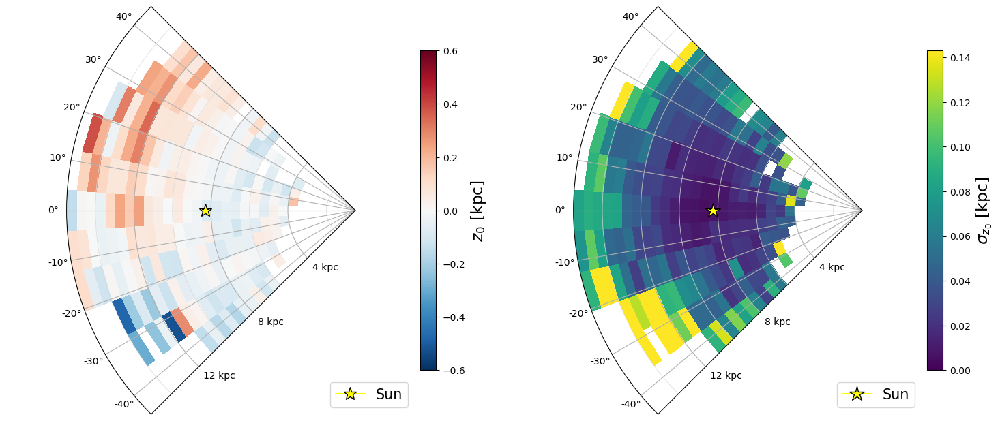

In [232]:
theta_edges = np.unwrap(np.array(crowd_bounds, float))
for i in range(1, len(theta_edges)):
    while theta_edges[i] <= theta_edges[i - 1]:
        theta_edges[i] += 2 * np.pi

theta_edges_deg = np.degrees(theta_edges)
theta_edges_eloisa_deg = np.mod(360.0 - theta_edges_deg, 360) - 180
theta_edges = np.radians(theta_edges_eloisa_deg)

order = np.argsort(theta_edges)
theta_edges = theta_edges[order]

# work on COPIES so this cell is safe to rerun any number of times
z0_med_plot = z0_med.copy()
z0_std_plot = z0_std.copy()
if not np.all(order == np.arange(len(order))):
    z0_med_plot = z0_med_plot[:, ::-1]
    z0_std_plot = z0_std_plot[:, ::-1]
# ---------------------------------------------------------------------------------------
R_TICKS = [4, 8, 12, 16]
EXTRA_R_TICKS = [2, 6, 10, 14]

T_mesh, R_mesh = np.meshgrid(theta_edges, R_edges)
Zmap_med = np.ma.masked_invalid(z0_med_plot)
Zmap_std = np.ma.masked_invalid(z0_std_plot)
std_max = float(np.nanpercentile(z0_std_plot[np.isfinite(z0_std_plot)], 95)) if np.isfinite(z0_std_plot).any() else 1.0
theta_min, theta_max = theta_edges[0], theta_edges[-1]
theta_sun, R_sun = np.radians(0), 8.275

fig = plt.figure(figsize=(15, 7))
ax1 = plt.subplot(1, 2, 1, projection="polar")
pcm1 = ax1.pcolormesh(T_mesh, R_mesh, Zmap_med, cmap="RdBu_r", vmin=-zlim, vmax=zlim, shading="flat")
fig.colorbar(pcm1, ax=ax1, pad=0.01, shrink=0.7).set_label(r"$z_0$ [kpc]", fontsize=17)
ax1.set_theta_zero_location("W"); ax1.set_theta_direction(-1); ax1.set_rmax(R_edges[-1])
ax1.set_thetamin(np.degrees(theta_min)); ax1.set_thetamax(np.degrees(theta_max))
ax1.set_rgrids(R_TICKS, labels=[f"{r} kpc" for r in R_TICKS], fontsize=11)
ax1.plot(theta_sun, R_sun, marker="*", color="yellow", markersize=14, markeredgecolor="k", zorder=5, label="Sun")
ax1.legend(loc="lower right", fontsize=15)

ax2 = plt.subplot(1, 2, 2, projection="polar")
pcm2 = ax2.pcolormesh(T_mesh, R_mesh, Zmap_std, cmap="viridis", vmin=0.0, vmax=std_max, shading="flat")
fig.colorbar(pcm2, ax=ax2, pad=0.01, shrink=0.7).set_label(r"$\sigma_{z_0}$ [kpc]", fontsize=17)
ax2.set_theta_zero_location("W"); ax2.set_theta_direction(-1); ax2.set_rmax(R_edges[-1])
ax2.set_thetamin(np.degrees(theta_min)); ax2.set_thetamax(np.degrees(theta_max))
ax2.set_rgrids(R_TICKS, labels=[f"{r} kpc" for r in R_TICKS], fontsize=11)
ax2.plot(theta_sun, R_sun, marker="*", color="yellow", markersize=16, markeredgecolor="k", zorder=5, label="Sun")
ax2.legend(loc="lower right", fontsize=15)

for ax in (ax1, ax2):
    ax.set_yticks(EXTRA_R_TICKS, minor=True)
    ax.yaxis.grid(True, which="minor", color="0.85", linestyle="-", linewidth=0.5)

plt.tight_layout()
fig.savefig("z0heatmap.pdf", bbox_inches="tight")
plt.show()

fitting radial bins:   0%|                               | 0/23 [00:00<?, ?it/s]/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_64467/2600209016.py:10: RuntimeWarning: invalid value encountered in divide
  mean_mg_fe = stat1.statistic / stat2.statistic
/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_64467/2600209016.py:11: RuntimeWarning: divide by zero encountered in divide
  mean_mg_fe_err = np.sqrt(1 / stat2.statistic + intrinsic_scatter**2)
/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_64467/2600209016.py:18: UserWarning: There are not enough devices to run parallel chains: expected 2 but got 1. Chains will be drawn sequentially. If you are running MCMC in CPU, consider using `numpyro.set_host_device_count(2)` at the beginning of your program. You can double-check how many devices are available in your system using `jax.local_device_count()`.
  sampler = infer.MCMC(
fitting radial bins: 100%|██████████████████████| 23/23 [02:00<00:00,  5.24s/it]


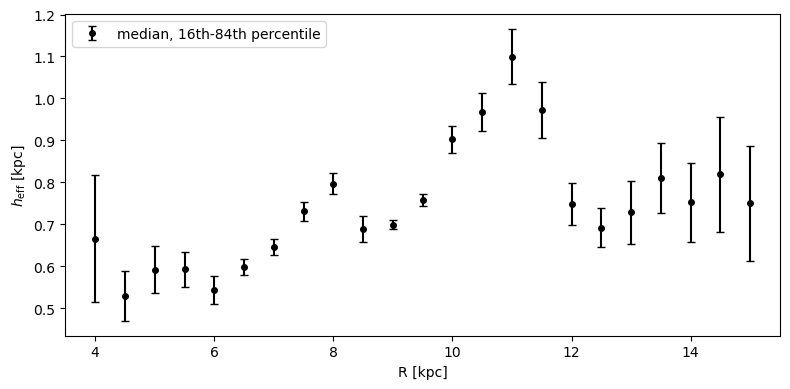

In [14]:
R_centers_flare = np.arange(4, 15 + 1e-3, 0.5)
R_width = 1.0
n_R_flare = len(R_centers_flare)

R_arr, Z_arr, mgfe_arr, err_arr = map(np.asarray, (R_star, Z_star, mgfe_star, mgfe_err_star))
m_base = (np.isfinite(R_arr) & np.isfinite(Z_arr) & np.isfinite(mgfe_arr)
          & np.isfinite(err_arr) & (err_arr > 0))

per_R_flare = {}
key = jr.PRNGKey(0)

for i_R in tqdm(range(n_R_flare), desc="fitting radial bins"):
    Rlo, Rhi = R_centers_flare[i_R] - R_width/2, R_centers_flare[i_R] + R_width/2
    m = m_base & (R_arr >= Rlo) & (R_arr < Rhi)
    n_stars = int(m.sum())
    if n_stars < minN_seg_total:
        continue

    z_binc, mean_mg_fe, mean_mg_fe_err, counts = bin_one(Z_arr[m], mgfe_arr[m], err_arr[m])
    good = (np.isfinite(mean_mg_fe) & np.isfinite(mean_mg_fe_err)
            & (counts >= min_bin_count) & (z_binc >= z_fit_min) & (z_binc <= z_fit_max))
    if good.sum() < min_bins_for_fit:
        continue

    try:
        key, sub = jr.split(key)
        sampler = fit_sech2(np.asarray(z_binc[good], float), np.asarray(mean_mg_fe[good], float),
                             np.asarray(mean_mg_fe_err[good], float), sub, progress_bar=False)
        samples = sampler.get_samples()
        per_R_flare[i_R] = {"Rlo": Rlo, "Rhi": Rhi, "n_stars": n_stars,
                             "z_binc": np.asarray(z_binc[good]), "mean": np.asarray(mean_mg_fe[good]),
                             "err": np.asarray(mean_mg_fe_err[good]),
                             "samples": {k: np.asarray(v) for k, v in samples.items()}}
    except Exception as e:
        print(f"R=[{Rlo:.1f},{Rhi:.1f}]: fit failed -> {e}")

with open("per_R_flare_zsun0.pkl", "wb") as f:
    pickle.dump(per_R_flare, f)

def root_func(z, pars):
    Ystar = mixture_of_sech2(z, pars["A1"], pars["A2"], pars["h1"], pars["h2"], pars["z0"])
    return Ystar - 0.5 * (pars["A1"] + pars["A2"])

h_eff_med_flare = np.full(n_R_flare, np.nan)
h_eff_std_flare = np.full(n_R_flare, np.nan)

for i_R, cell in per_R_flare.items():
    s = cell["samples"]
    h_effs = []
    for i in range(256):
        cs = {k: v[i] for k, v in s.items()}
        cs["h2"] = cs["h1"] + cs["d_h2"]
        hi = 8 * max(cs["h1"], cs["h2"])
        try:
            zstar = brentq(root_func, cs["z0"] + 1e-9, hi, args=(cs,))
            h_effs.append(zstar - cs["z0"])
        except ValueError:
            continue
    if h_effs:
        h_effs = np.array(h_effs)
        h_eff_med_flare[i_R] = np.median(h_effs)
        pcl = np.percentile(h_effs, [16, 84])
        h_eff_std_flare[i_R] = 0.5 * (pcl[1] - pcl[0])

fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(R_centers_flare, h_eff_med_flare, yerr=h_eff_std_flare,
            fmt="o", color="k", ms=4, capsize=3, label="median, 16th-84th percentile")
ax.legend(loc="upper left")
ax.set_xlabel("R [kpc]")
ax.set_ylabel(r"$h_\mathrm{eff}$ [kpc]")
ax.set_xlim(R_centers_flare[0] - R_width/2, R_centers_flare[-1] + R_width/2)
plt.tight_layout()
plt.show()

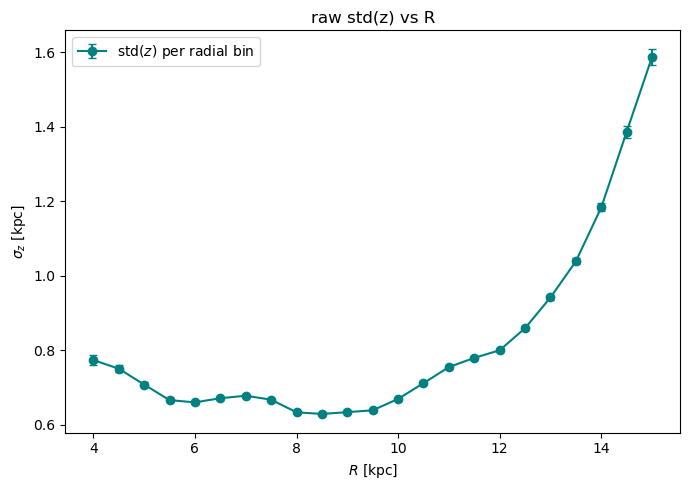

In [191]:
# quick-look h_eff proxy: raw standard deviation of z within each radial bin,
# instead of the full MCMC sech^2 fit + HWHM extraction

h_std = np.full(len(R_centers_flare), np.nan)
h_std_err = np.full(len(R_centers_flare), np.nan)
n_star_bin = np.zeros(len(R_centers_flare), dtype=int)

for i, Rc in enumerate(R_centers_flare):
    in_bin = m_base & (R_arr >= Rc - R_width/2) & (R_arr < Rc + R_width/2)
    z_bin = Z_arr[in_bin]
    n = z_bin.size
    n_star_bin[i] = n
    if n > 1:
        h_std[i] = np.std(z_bin, ddof=1)
        # simple analytic uncertainty on a std estimate: sigma / sqrt(2(n-1))
        h_std_err[i] = h_std[i] / np.sqrt(2 * (n - 1))

fig, ax = plt.subplots(figsize=(7, 5))
ax.errorbar(R_centers_flare, h_std, yerr=h_std_err, fmt='o-', color='teal',
            capsize=3, label=r'std($z$) per radial bin')
ax.set_xlabel(r"$R$ [kpc]")
ax.set_ylabel(r"$\sigma_z$ [kpc]")
ax.set_title("raw std(z) vs R")
ax.legend()
plt.tight_layout()
plt.show()

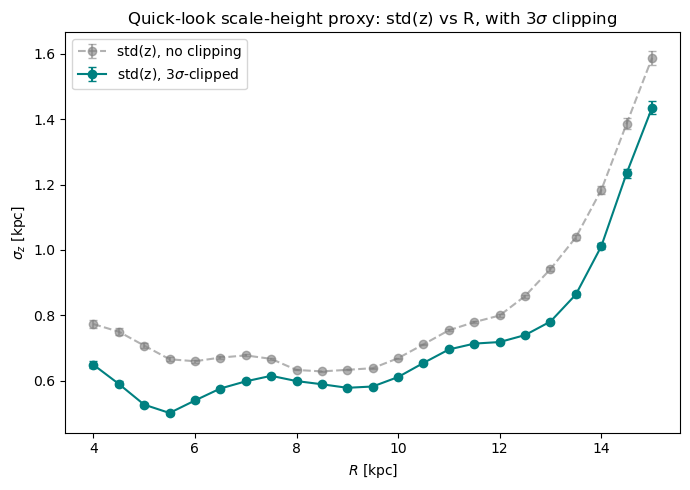

In [192]:
from astropy.stats import sigma_clip

h_std_clipped = np.full(len(R_centers_flare), np.nan)
h_std_clipped_err = np.full(len(R_centers_flare), np.nan)
n_star_bin_clipped = np.zeros(len(R_centers_flare), dtype=int)

for i, Rc in enumerate(R_centers_flare):
    in_bin = m_base & (R_arr >= Rc - R_width/2) & (R_arr < Rc + R_width/2)
    z_bin = Z_arr[in_bin]

    z_clipped = sigma_clip(z_bin, sigma=3, maxiters=5, masked=True)
    z_good = z_clipped.compressed()   # keep only the non-clipped values
    n = z_good.size
    n_star_bin_clipped[i] = n
    if n > 1:
        h_std_clipped[i] = np.std(z_good, ddof=1)
        h_std_clipped_err[i] = h_std_clipped[i] / np.sqrt(2 * (n - 1))

fig, ax = plt.subplots(figsize=(7, 5))
ax.errorbar(R_centers_flare, h_std, yerr=h_std_err, fmt='o--', color='gray',
            capsize=3, alpha=0.6, label='std(z), no clipping')
ax.errorbar(R_centers_flare, h_std_clipped, yerr=h_std_clipped_err, fmt='o-', color='teal',
            capsize=3, label='std(z), 3$\\sigma$-clipped')
ax.set_xlabel(r"$R$ [kpc]")
ax.set_ylabel(r"$\sigma_z$ [kpc]")
ax.set_title("Quick-look scale-height proxy: std(z) vs R, with 3$\\sigma$ clipping")
ax.legend()
plt.tight_layout()
plt.show()

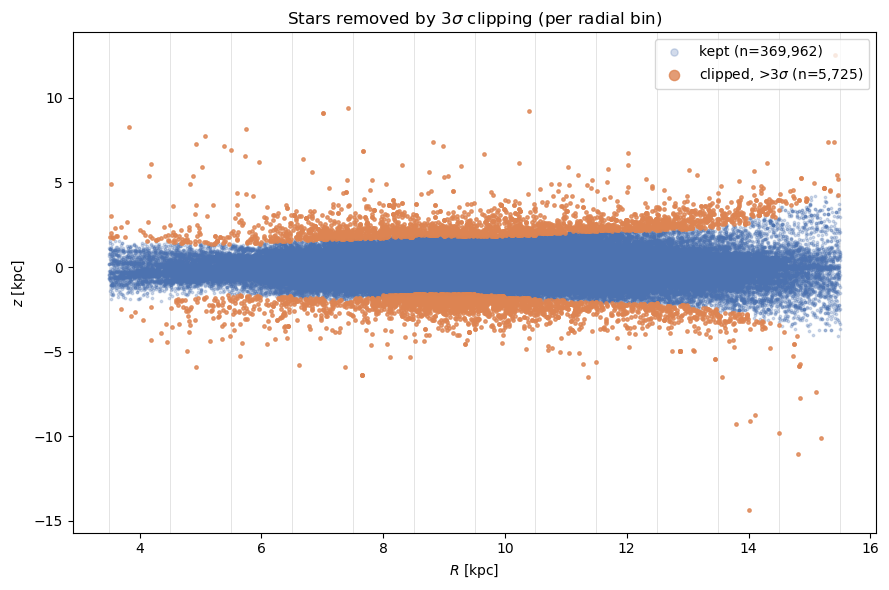

In [201]:
from astropy.stats import sigma_clip

# build global kept/clipped masks across all bins, reusing the exact same
# per-bin logic as your sigma-clip cell
is_clipped = np.zeros(len(R_arr), dtype=bool)
is_in_any_bin = np.zeros(len(R_arr), dtype=bool)

for Rc in R_centers_flare:
    in_bin_idx = np.where(m_base & (R_arr >= Rc - R_width/2) & (R_arr < Rc + R_width/2))[0]
    is_in_any_bin[in_bin_idx] = True
    z_bin = Z_arr[in_bin_idx]

    z_clipped = sigma_clip(z_bin, sigma=3, maxiters=5, masked=True)
    clipped_local = np.asarray(z_clipped.mask)   # True = removed by the clip
    is_clipped[in_bin_idx[clipped_local]] = True

kept_idx = np.where(is_in_any_bin & ~is_clipped)[0]
clipped_idx = np.where(is_in_any_bin & is_clipped)[0]

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(R_arr[kept_idx], Z_arr[kept_idx], s=3, color="#4C72B0", alpha=0.25,
           label=f"kept (n={len(kept_idx):,})", rasterized=True)
ax.scatter(R_arr[clipped_idx], Z_arr[clipped_idx], s=6, color="#DD8452", alpha=0.8,
           label=f"clipped, >3$\\sigma$ (n={len(clipped_idx):,})", zorder=5)

for edge in np.arange(R_centers_flare[0] - R_width/2, R_centers_flare[-1] + R_width/2 + 1e-6, R_width):
    ax.axvline(edge, color="0.85", lw=0.5, zorder=0)

ax.set_xlabel(r"$R$ [kpc]")
ax.set_ylabel(r"$z$ [kpc]")
ax.set_title("Stars removed by 3$\\sigma$ clipping (per radial bin)")
ax.legend(loc="upper right", markerscale=3)
plt.tight_layout()
plt.show()

In [14]:
import jax
import jax.numpy as jnp
import numpyro
import numpyro.distributions as dist
from numpyro.infer import MCMC, NUTS

POGGIO_YOUNG_GIANT = {
    "R_w": 5.5, "h_w0": 0.012, "alpha_w": 1.9,
    "phi_LON0": 0.1, "R_t": 12.1, "beta_w": 9.9,
}

def warp_model(R, phi_deg, z0_obs=None, z0_err=None):
    """Full 6-parameter model."""
    R_w = numpyro.sample("R_w", dist.Uniform(2.0, 9.0))
    h_w0 = numpyro.sample("h_w0", dist.HalfNormal(0.05))
    alpha_w = numpyro.sample("alpha_w", dist.Uniform(0.5, 3.0))
    phi_LON0 = numpyro.sample("phi_LON0", dist.Normal(0.0, 10.0))
    R_t = numpyro.sample("R_t", dist.Uniform(9.0, 15.0))
    beta_w = numpyro.sample("beta_w", dist.Normal(0.0, 15.0))

    dR = jnp.clip(R - R_w, a_min=0.0)
    h_w = jnp.where(R > R_w, h_w0 * jnp.power(dR, alpha_w), 0.0)
    phi_LON = jnp.where(R <= R_t, phi_LON0, phi_LON0 + beta_w * (R - R_t))
    z_pred = h_w * jnp.sin(jnp.deg2rad(phi_deg) - jnp.deg2rad(phi_LON))

    numpyro.deterministic("z_pred", z_pred)
    numpyro.sample("obs", dist.Normal(z_pred, z0_err), obs=z0_obs)


def warp_model_straight_LON(R, phi_deg, z0_obs=None, z0_err=None):
    """No twist term -- cross-check model."""
    R_w = POGGIO_YOUNG_GIANT["R_w"]
    h_w0 = numpyro.sample("h_w0", dist.HalfNormal(0.05))
    alpha_w = numpyro.sample("alpha_w", dist.Uniform(0.5, 4.0))
    phi_LON0 = numpyro.sample("phi_LON0", dist.Normal(0.0, 10.0))

    dR = jnp.clip(R - R_w, a_min=0.0)
    h_w = jnp.where(R > R_w, h_w0 * jnp.power(dR, alpha_w), 0.0)
    z_pred = h_w * jnp.sin(jnp.deg2rad(phi_deg) - jnp.deg2rad(phi_LON0))

    numpyro.deterministic("z_pred", z_pred)
    numpyro.sample("obs", dist.Normal(z_pred, z0_err), obs=z0_obs)

In [15]:
def run_warp_fit(model_fn, R, phi_deg, z0, z0_err, seed=0,
                  num_warmup=1500, num_samples=2000, num_chains=4):
    rng_key = jax.random.PRNGKey(seed)
    kernel = NUTS(model_fn, target_accept_prob=0.95, max_tree_depth=12)
    mcmc = MCMC(kernel, num_warmup=num_warmup, num_samples=num_samples, num_chains=num_chains)
    mcmc.run(rng_key, R=jnp.asarray(R), phi_deg=jnp.asarray(phi_deg),
              z0_obs=jnp.asarray(z0), z0_err=jnp.asarray(z0_err))
    mcmc.print_summary()
    return mcmc

def divergence_report(label, mcmc_obj, n_points):
    n_div = int(mcmc_obj.get_extra_fields()["diverging"].sum())
    n_total = len(mcmc_obj.get_extra_fields()["diverging"])
    pct = 100 * n_div / n_total
    print(f"{label}: {n_points} data points, {n_div}/{n_total} divergences ({pct:.1f}%)")

In [16]:
R_centers = 0.5 * (R_edges[:-1] + R_edges[1:])

theta_edges = np.unwrap(np.array(crowd_bounds, float))
for i in range(1, len(theta_edges)):
    while theta_edges[i] <= theta_edges[i - 1]:
        theta_edges[i] += 2 * np.pi

phi_centers_deg_emma = np.degrees(0.5 * (theta_edges[:-1] + theta_edges[1:]))

# convert to Poggio's convention (phi=0 toward anti-centre, increasing with rotation)
phi_centers_deg = 180.0 - phi_centers_deg_emma
phi_centers_deg = (phi_centers_deg + 180) % 360 - 180

R_grid, Phi_grid = np.meshgrid(R_centers, phi_centers_deg, indexing="ij")

def extract_fit_arrays(z0_med_bin, z0_std_bin, ok_grid_bin=None, R_min=8.277, R_max=14.5):
    mask = (np.isfinite(z0_med_bin) & np.isfinite(z0_std_bin) & (z0_std_bin > 0)
            & (R_grid >= R_min) & (R_grid <= R_max))
    if ok_grid_bin is not None:
        mask &= ok_grid_bin
    return R_grid[mask], Phi_grid[mask], z0_med_bin[mask], z0_std_bin[mask]

# using your Step 8 z_sun=0 grid directly -- no "_u" suffix needed since there's no age split
R_u, phi_u, z0_u, z0err_u = extract_fit_arrays(z0_med, z0_std, ok_grid)
print(f"unified (z_sun=0): {len(z0_u)} cells going into the fit")

unified (z_sun=0): 117 cells going into the fit


In [17]:
from src.coords import build_galactocentric_phase_space

phase, _ = build_galactocentric_phase_space(t_star)
print("median vphi:", np.median(phase["vphi"]), "(expect ~ +200-250 km/s, prograde)")

median vphi: 229.0857684091868 (expect ~ +200-250 km/s, prograde)


In [27]:
mcmc_unified = run_warp_fit(warp_model, R_u, phi_u, z0_u, z0err_u)
samples_unified = mcmc_unified.get_samples()
divergence_report("unified (z_sun=0)", mcmc_unified, len(z0_u))

/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_20195/1170746708.py:5: UserWarning: There are not enough devices to run parallel chains: expected 4 but got 1. Chains will be drawn sequentially. If you are running MCMC in CPU, consider using `numpyro.set_host_device_count(4)` at the beginning of your program. You can double-check how many devices are available in your system using `jax.local_device_count()`.
  mcmc = MCMC(kernel, num_warmup=num_warmup, num_samples=num_samples, num_chains=num_chains)
sample: 100%|█| 3500/3500 [00:06<00:00, 502.39it/s, 127 steps of size 3.11e-02. 
sample: 100%|█| 3500/3500 [00:04<00:00, 743.03it/s, 127 steps of size 4.68e-02. 
sample: 100%|█| 3500/3500 [00:04<00:00, 811.85it/s, 63 steps of size 5.11e-02. a
sample: 100%|█| 3500/3500 [00:04<00:00, 703.49it/s, 63 steps of size 4.37e-02. a



                mean       std    median      5.0%     95.0%     n_eff     r_hat
       R_t     12.36      0.20     12.35     12.07     12.71   3915.86      1.00
       R_w      8.24      0.44      8.31      7.57      8.90   2818.26      1.00
   alpha_w      2.01      0.34      1.98      1.45      2.56   2796.13      1.00
    beta_w     12.80      2.51     12.76      8.80     16.96   3763.79      1.00
      h_w0      0.02      0.01      0.02      0.00      0.03   2951.62      1.00
  phi_LON0    -20.48      2.89    -20.33    -24.96    -15.62   3268.71      1.00

Number of divergences: 1
unified (z_sun=0): 117 data points, 1/8000 divergences (0.0%)


In [28]:
mcmc_straight = run_warp_fit(warp_model_straight_LON, R_u, phi_u, z0_u, z0err_u)
samples_straight = mcmc_straight.get_samples()
divergence_report("unified, straight LON (z_sun=0)", mcmc_straight, len(z0_u))
print("phi_LON0 (straight LON):", samples_straight["phi_LON0"].mean(),
      "+/-", samples_straight["phi_LON0"].std())

/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_20195/1170746708.py:5: UserWarning: There are not enough devices to run parallel chains: expected 4 but got 1. Chains will be drawn sequentially. If you are running MCMC in CPU, consider using `numpyro.set_host_device_count(4)` at the beginning of your program. You can double-check how many devices are available in your system using `jax.local_device_count()`.
  mcmc = MCMC(kernel, num_warmup=num_warmup, num_samples=num_samples, num_chains=num_chains)
sample: 100%|█| 3500/3500 [00:02<00:00, 1551.90it/s, 15 steps of size 6.45e-02. 
sample: 100%|█| 3500/3500 [00:01<00:00, 2287.88it/s, 63 steps of size 7.55e-02. 
sample: 100%|█| 3500/3500 [00:01<00:00, 2345.32it/s, 31 steps of size 7.81e-02. 
sample: 100%|█| 3500/3500 [00:01<00:00, 2293.70it/s, 51 steps of size 8.32e-02. 



                mean       std    median      5.0%     95.0%     n_eff     r_hat
   alpha_w      2.83      0.23      2.83      2.47      3.22   2056.41      1.00
      h_w0      0.00      0.00      0.00      0.00      0.00   2100.44      1.00
  phi_LON0    -11.27      1.71    -11.22    -14.10     -8.55   3090.38      1.00

Number of divergences: 0
unified, straight LON (z_sun=0): 117 data points, 0/8000 divergences (0.0%)
phi_LON0 (straight LON): -11.268584564621387 +/- 1.7069570291792144


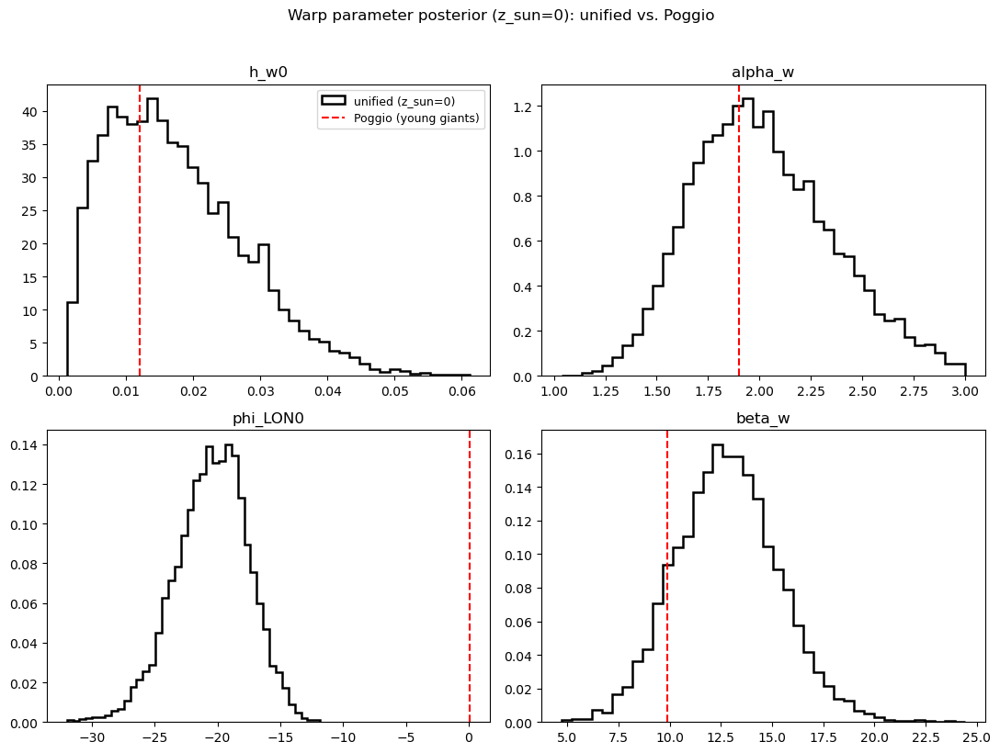

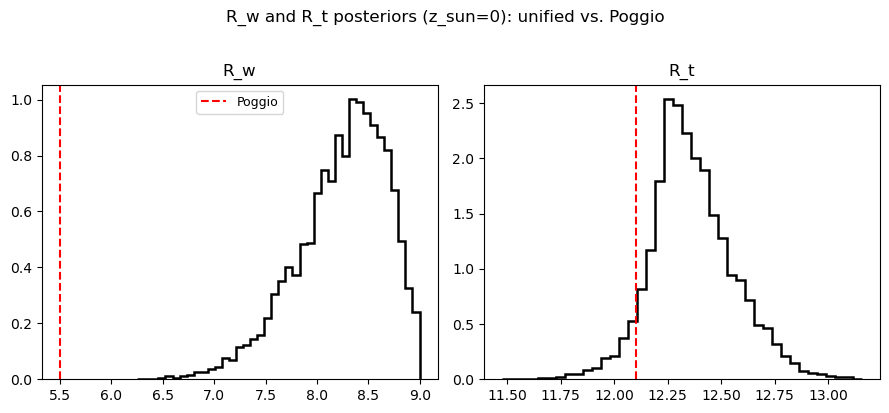

In [29]:
param_names = ["h_w0", "alpha_w", "phi_LON0", "beta_w"]

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, pname in zip(axes.flat, param_names):
    ax.hist(samples_unified[pname], bins=40, density=True, histtype="step",
            color="k", label="unified (z_sun=0)", linewidth=1.8)
    ax.axvline(POGGIO_YOUNG_GIANT[pname], color="red", linestyle="--",
               linewidth=1.5, label="Poggio (young giants)" if pname == "h_w0" else None)
    ax.set_title(pname)

axes[0, 0].legend(fontsize=9)
plt.suptitle("Warp parameter posterior (z_sun=0): unified vs. Poggio", y=1.02)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].hist(samples_unified["R_w"], bins=40, density=True, histtype="step", color="k", linewidth=1.8)
axes[0].axvline(POGGIO_YOUNG_GIANT["R_w"], color="red", linestyle="--", linewidth=1.5, label="Poggio")
axes[0].set_title("R_w")
axes[0].legend(fontsize=9)

axes[1].hist(samples_unified["R_t"], bins=40, density=True, histtype="step", color="k", linewidth=1.8)
axes[1].axvline(POGGIO_YOUNG_GIANT["R_t"], color="red", linestyle="--", linewidth=1.5)
axes[1].set_title("R_t")

plt.suptitle("R_w and R_t posteriors (z_sun=0): unified vs. Poggio", y=1.02)
plt.tight_layout()
plt.show()

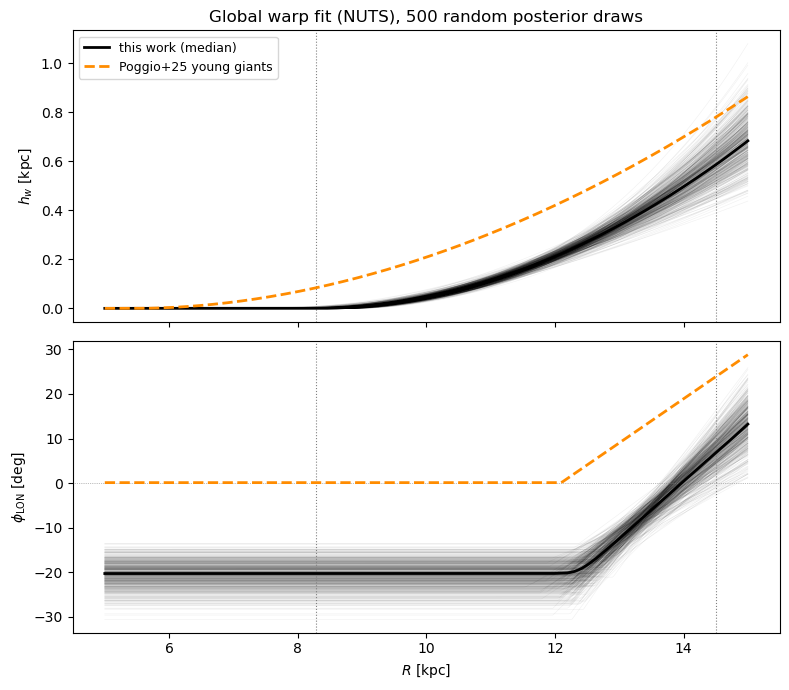

In [240]:
import numpy as np
import matplotlib.pyplot as plt

N_DRAWS = 500          # random posterior draws to show
N_MEDIAN = 2000        # draws used to compute the median curve
rng = np.random.default_rng(0)

R_grid_plot = np.linspace(5.0, 15.0, 400)

def h_w_curve(R, h_w0, R_w, alpha_w):
    return np.where(R > R_w, h_w0 * np.clip(R - R_w, 0, None) ** alpha_w, 0.0)

def phiLON_curve(R, phi_LON0, R_t, beta_w):
    return np.where(R <= R_t, phi_LON0, phi_LON0 + beta_w * (R - R_t))

s = {k: np.asarray(v) for k, v in samples_unified.items()}
n_total = len(s["h_w0"])
idx_show = rng.choice(n_total, size=min(N_DRAWS, n_total), replace=False)
idx_med  = rng.choice(n_total, size=min(N_MEDIAN, n_total), replace=False)

def curves(idx):
    hw = np.array([h_w_curve(R_grid_plot, s["h_w0"][i], s["R_w"][i], s["alpha_w"][i]) for i in idx])
    ph = np.array([phiLON_curve(R_grid_plot, s["phi_LON0"][i], s["R_t"][i], s["beta_w"][i]) for i in idx])
    return hw, ph

hw_show, ph_show = curves(idx_show)
hw_med_draws, ph_med_draws = curves(idx_med)
hw_med = np.median(hw_med_draws, axis=0)
ph_med = np.median(ph_med_draws, axis=0)

pg = POGGIO_YOUNG_GIANT
hw_pg = h_w_curve(R_grid_plot, pg["h_w0"], pg["R_w"], pg["alpha_w"])
ph_pg = phiLON_curve(R_grid_plot, pg["phi_LON0"], pg["R_t"], pg["beta_w"])

fig, axes = plt.subplots(2, 1, figsize=(8, 7), sharex=True)

for j in range(len(idx_show)):
    axes[0].plot(R_grid_plot, hw_show[j], color="k", lw=0.5, alpha=0.05, zorder=1)
    axes[1].plot(R_grid_plot, ph_show[j], color="k", lw=0.5, alpha=0.05, zorder=1)

axes[0].plot(R_grid_plot, hw_med, color="k", lw=2, zorder=3, label="this work (median)")
axes[0].plot(R_grid_plot, hw_pg, color="darkorange", lw=2, ls="--", zorder=3, label="Poggio+25 young giants")
axes[0].set_ylabel(r"$h_w$ [kpc]")
axes[0].legend(fontsize=9)

axes[1].plot(R_grid_plot, ph_med, color="k", lw=2, zorder=3)
axes[1].plot(R_grid_plot, ph_pg, color="darkorange", lw=2, ls="--", zorder=3)
axes[1].axhline(0, color="gray", lw=0.5, ls=":")
axes[1].set_ylabel(r"$\phi_{\rm LON}$ [deg]")
axes[1].set_xlabel(r"$R$ [kpc]")

for ax in axes:
    ax.axvline(8.277, color="gray", lw=0.8, ls=":")   # edges of the radii that went into the fit
    ax.axvline(14.5,  color="gray", lw=0.8, ls=":")

axes[0].set_title(f"Global warp fit (NUTS), {len(idx_show)} random posterior draws")
plt.tight_layout()
plt.show()

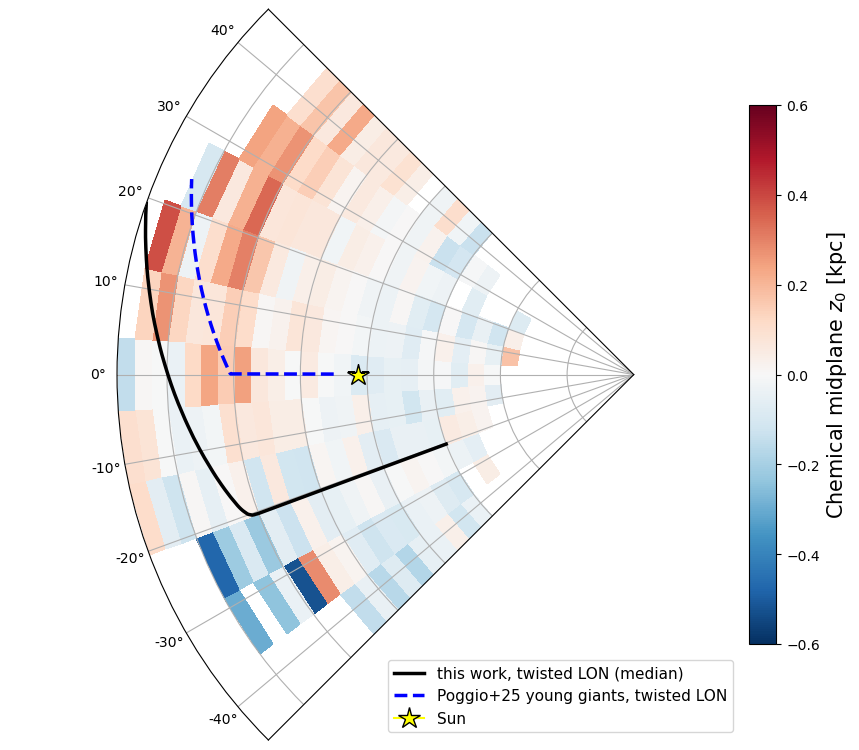

In [243]:
import numpy as np
import matplotlib.pyplot as plt

# ---------- rebuild the theta mesh fresh (so rerunning is safe) ----------
def to_eloisa_frame(phi_deg_emma):
    return np.mod(360.0 - phi_deg_emma, 360) - 180

th = np.unwrap(np.array(crowd_bounds, float))
for i in range(1, len(th)):
    while th[i] <= th[i - 1]:
        th[i] += 2 * np.pi
th_eloisa = np.radians(to_eloisa_frame(np.degrees(th)))
order = np.argsort(th_eloisa)
th_eloisa = th_eloisa[order]

z0_plot = z0_med.copy()
if not np.all(order == np.arange(len(order))):
    z0_plot = z0_plot[:, ::-1]
Zmap = np.ma.masked_invalid(z0_plot)

T_mesh, R_mesh = np.meshgrid(th_eloisa, R_edges)
R_sun_kpc = 8.275

# ---------- your NUTS twisted line of nodes ----------
N_DRAWS = 100
rng = np.random.default_rng(0)
s = {k: np.asarray(v) for k, v in samples_unified.items()}
idx = rng.choice(len(s["phi_LON0"]), size=N_DRAWS, replace=False)
idx_med = rng.choice(len(s["phi_LON0"]), size=min(2000, len(s["phi_LON0"])), replace=False)

R_lon = np.linspace(6.0, R_edges[-1], 300)

def lon(R, phi0, R_t, beta):
    return np.where(R <= R_t, phi0, phi0 + beta * (R - R_t))

draws = np.array([lon(R_lon, s["phi_LON0"][i], s["R_t"][i], s["beta_w"][i]) for i in idx])
med_draws = np.array([lon(R_lon, s["phi_LON0"][i], s["R_t"][i], s["beta_w"][i]) for i in idx_med])
lon_med = np.median(med_draws, axis=0)

# ---------- Eloisa's (Poggio+25 young giants) twisted line of nodes ----------
R_yg = np.linspace(9.0, 14.5, 300)
lon_yg = phiLON_paper(R_yg, yg["phiLON0"], yg["R_t"], yg["beta_w"])

# ---------- plot ----------
fig = plt.figure(figsize=(9, 8))
ax = plt.subplot(1, 1, 1, projection="polar")
pcm = ax.pcolormesh(T_mesh, R_mesh, Zmap, cmap="RdBu_r", vmin=-zlim, vmax=zlim, shading="flat")
fig.colorbar(pcm, ax=ax, pad=0.01, shrink=0.7).set_label(r"Chemical midplane $z_0$ [kpc]", fontsize=15)

ax.set_theta_zero_location("W"); ax.set_theta_direction(-1)
ax.set_rmax(R_edges[-1])
ax.set_thetamin(np.degrees(th_eloisa[0])); ax.set_thetamax(np.degrees(th_eloisa[-1]))
ax.set_yticklabels([])

ax.plot(np.radians(lon_med), R_lon, color="k", lw=2.5, zorder=4, label="this work, twisted LON (median)")
ax.plot(np.radians(lon_yg), R_yg, color="blue", lw=2.5, ls="--", zorder=4,
        label="Poggio+25 young giants, twisted LON")
ax.plot(0.0, R_sun_kpc, marker="*", color="yellow", markersize=16, markeredgecolor="k", zorder=5, label="Sun")

ax.legend(loc="lower right", fontsize=11)
plt.tight_layout()
plt.show()

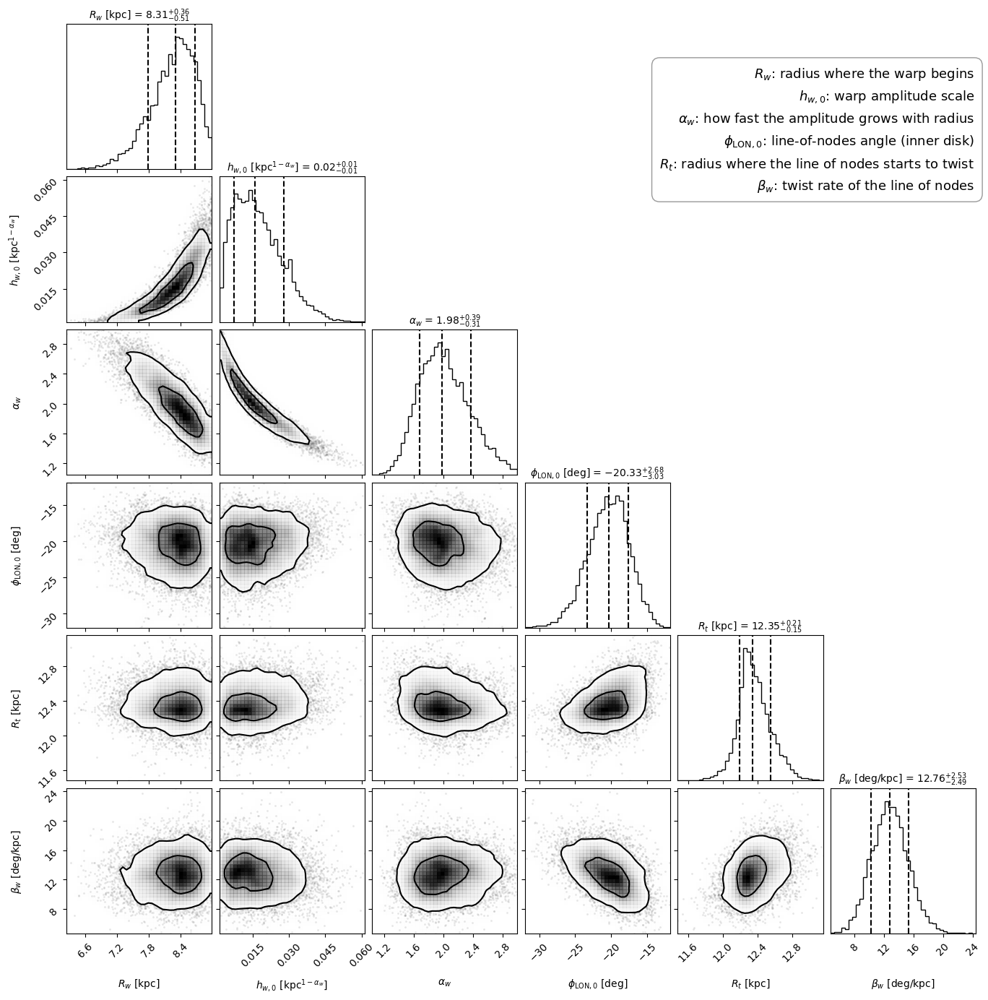

In [253]:
import numpy as np
import corner
import matplotlib.pyplot as plt

params = ["R_w", "h_w0", "alpha_w", "phi_LON0", "R_t", "beta_w"]
labels = [
    r"$R_w$ [kpc]",
    r"$h_{w,0}$ [kpc$^{1-\alpha_w}$]",
    r"$\alpha_w$",
    r"$\phi_{\rm LON,0}$ [deg]",
    r"$R_t$ [kpc]",
    r"$\beta_w$ [deg/kpc]",
]

chain = np.column_stack([np.asarray(samples_unified[p]) for p in params])

fig = corner.corner(
    chain,
    labels=labels,
    quantiles=[0.16, 0.5, 0.84],
    show_titles=True,
    title_kwargs={"fontsize": 10},
    levels=(1 - np.exp(-0.5), 1 - np.exp(-2.0)),   # 1 and 2 sigma contours
    smooth=1.0,
    bins=40,
)
legend_lines = [
    r"$R_w$: radius where the warp begins",
    r"$h_{w,0}$: warp amplitude scale",
    r"$\alpha_w$: how fast the amplitude grows with radius",
    r"$\phi_{\rm LON,0}$: line-of-nodes angle (inner disk)",
    r"$R_t$: radius where the line of nodes starts to twist",
    r"$\beta_w$: twist rate of the line of nodes",
]
fig.text(0.97, 0.93, "\n".join(legend_lines), ha="right", va="top", fontsize=13,
         linespacing=1.6,
         bbox=dict(boxstyle="round,pad=0.6", fc="white", ec="0.6"))
fig.set_size_inches(14, 14)
plt.show()

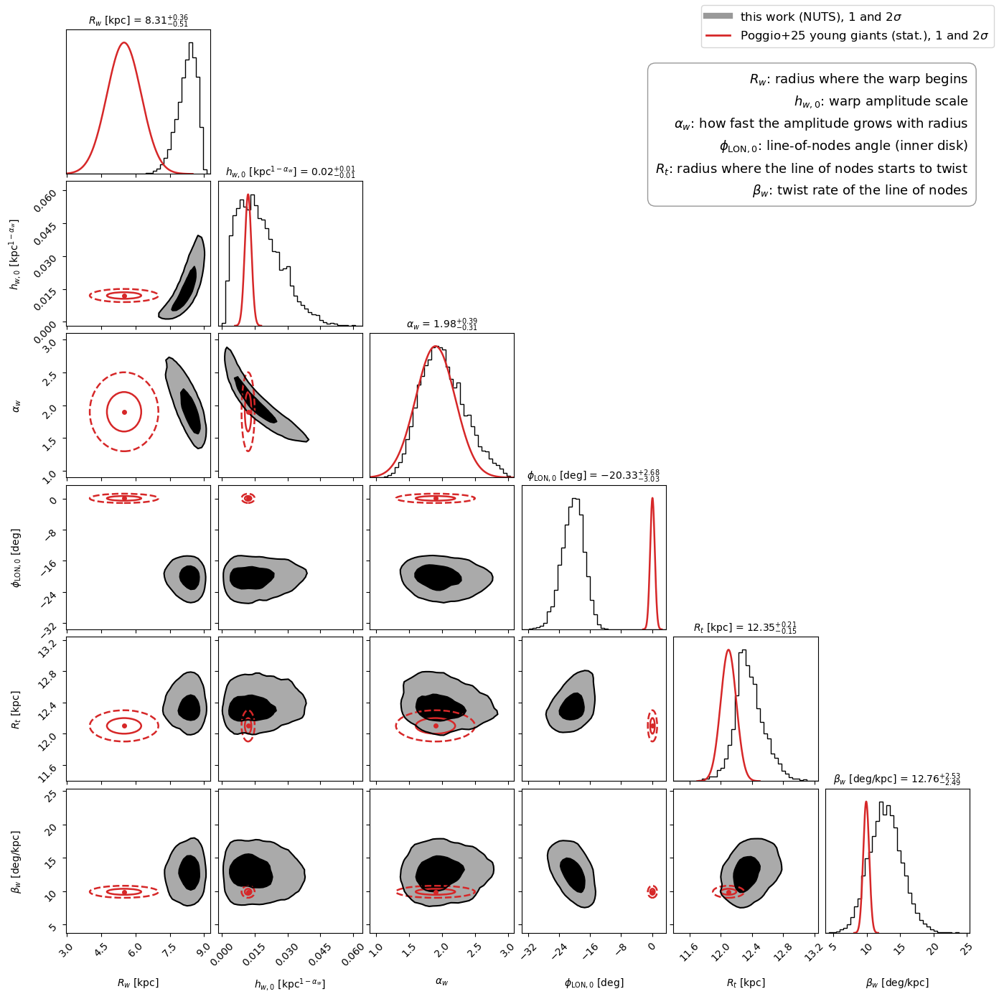

In [255]:
import numpy as np
import corner
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
from matplotlib.lines import Line2D

# ------------------------------------------------------------------
# Settings
# ------------------------------------------------------------------
UNCERTAINTY = "stat"    # "stat" = Poggio statistical only, "total" = stat and sys in quadrature

params = ["R_w", "h_w0", "alpha_w", "phi_LON0", "R_t", "beta_w"]
labels = {
    "R_w":      r"$R_w$ [kpc]",
    "h_w0":     r"$h_{w,0}$ [kpc$^{1-\alpha_w}$]",
    "alpha_w":  r"$\alpha_w$",
    "phi_LON0": r"$\phi_{\rm LON,0}$ [deg]",
    "R_t":      r"$R_t$ [kpc]",
    "beta_w":   r"$\beta_w$ [deg/kpc]",
}

# ------------------------------------------------------------------
# Poggio+25 Table 1 (young giants): best, stat(+, -), sys(+, -)
# ------------------------------------------------------------------
POGGIO_TABLE = {
    "R_w":      (5.5,   (0.8, 0.7),     (1.3, 0.8)),
    "h_w0":     (0.012, (0.002, 0.001), (0.006, 0.001)),
    "alpha_w":  (1.9,   (0.3, 0.3),     (0.5, 0.6)),
    "phi_LON0": (0.1,   (0.6, 0.6),     (1.1, 1.2)),
    "R_t":      (12.1,  (0.1, 0.1),     (0.1, 0.1)),
    "beta_w":   (9.9,   (0.5, 0.4),     (0.4, 0.2)),
}

def poggio_sigma(name):
    _, stat, sys_ = POGGIO_TABLE[name]
    s_stat = 0.5 * (stat[0] + stat[1])       # symmetric approximation
    s_sys  = 0.5 * (sys_[0] + sys_[1])
    return s_stat if UNCERTAINTY == "stat" else np.hypot(s_stat, s_sys)

mu  = np.array([POGGIO_TABLE[p][0] for p in params])
sig = np.array([poggio_sigma(p) for p in params])

# ------------------------------------------------------------------
# Your NUTS posterior
# ------------------------------------------------------------------
chain = np.column_stack([np.asarray(samples_unified[p]) for p in params])

# axis ranges wide enough to hold both posteriors, with a little padding
rng = []
for k in range(len(params)):
    lo = min(chain[:, k].min(), mu[k] - 3 * sig[k])
    hi = max(chain[:, k].max(), mu[k] + 3 * sig[k])
    pad = 0.05 * (hi - lo)
    rng.append((lo - pad, hi + pad))

# 2D contour levels corresponding to 1 and 2 sigma of a Gaussian
levels = (1 - np.exp(-0.5), 1 - np.exp(-2.0))

fig = corner.corner(
    chain, labels=[labels[p] for p in params], range=rng, levels=levels,
    color="k", fill_contours=True, plot_datapoints=False,
    smooth=1.0, bins=40, hist_kwargs={"density": True},
    show_titles=True, title_kwargs={"fontsize": 10},
)
fig.set_size_inches(14, 14)

# ------------------------------------------------------------------
# Overlay Eloisa's published values as 1 and 2 sigma Gaussian ellipses
# ------------------------------------------------------------------
n = len(params)
axes = np.array(fig.axes).reshape(n, n)

for i in range(n):
    for j in range(i):
        ax = axes[i, j]
        for k, ls in [(1, "-"), (2, "--")]:
            ax.add_patch(Ellipse((mu[j], mu[i]), 2 * k * sig[j], 2 * k * sig[i],
                                 fill=False, ec="C3", lw=1.8, ls=ls))
        ax.plot(mu[j], mu[i], "o", color="C3", ms=4)

    # diagonal: Gaussian scaled to the same peak height as your histogram
    ax = axes[i, i]
    peak = np.histogram(chain[:, i], bins=40, range=rng[i], density=True)[0].max()
    x = np.linspace(mu[i] - 4 * sig[i], mu[i] + 4 * sig[i], 300)
    ax.plot(x, peak * np.exp(-0.5 * ((x - mu[i]) / sig[i]) ** 2), color="C3", lw=1.8)

unc_label = "stat." if UNCERTAINTY == "stat" else "stat. + sys."
fig.legend(
    handles=[
        Line2D([], [], color="k", lw=6, alpha=0.4, label=r"this work (NUTS), 1 and 2$\sigma$"),
        Line2D([], [], color="C3", lw=2, label=f"Poggio+25 young giants ({unc_label}), 1 and 2$\\sigma$"),
    ],
    loc="upper right", fontsize=12,
)
legend_lines = [
    r"$R_w$: radius where the warp begins",
    r"$h_{w,0}$: warp amplitude scale",
    r"$\alpha_w$: how fast the amplitude grows with radius",
    r"$\phi_{\rm LON,0}$: line-of-nodes angle (inner disk)",
    r"$R_t$: radius where the line of nodes starts to twist",
    r"$\beta_w$: twist rate of the line of nodes",
]
fig.text(0.97, 0.93, "\n".join(legend_lines), ha="right", va="top", fontsize=13,
         linespacing=1.6,
         bbox=dict(boxstyle="round,pad=0.6", fc="white", ec="0.6"))

plt.show()

In [258]:
import numpy as np
import jax
import jax.numpy as jnp
from numpyro import handlers

def describe(d):
    args = {k: float(np.asarray(getattr(d, k))) for k in d.arg_constraints}
    return f"{type(d).__name__}(" + ", ".join(f"{k}={v:g}" for k, v in args.items()) + ")"

def print_numpyro_priors(model_fn, title):
    tr = handlers.trace(handlers.seed(model_fn, jax.random.PRNGKey(0))).get_trace(
        R=jnp.array([10.0]), phi_deg=jnp.array([0.0]),
        z0_obs=jnp.array([0.0]), z0_err=jnp.array([0.1]))
    print(title)
    for name, site in tr.items():
        if site["type"] == "sample" and not site.get("is_observed", False):
            print(f"  {name:10s} {describe(site['fn'])}")
    print()

print("=== NUTS (NumPyro) priors ===")
print_numpyro_priors(warp_model, "Twisted LON model (warp_model):")
print("Initialization: no init_strategy set, so NumPyro's default (init_to_uniform) is used;")
print("each of the 4 chains starts at a different random point.\n")

# ------------------------------------------------------------------
# emcee: flat priors inside these bounds (mirrors lnprior_twisted / lnprior_straight)
# ------------------------------------------------------------------
print("=== emcee priors (flat inside bounds) ===")
emcee_bounds = {
    "h_w0":     (0.0001, 2.0),
    "R_w":      (3.0, R_sun),
    "alpha_w":  (0.1, 5.0),
    "phi_LON0": (-180.0, 180.0),
    "R_t":      ("R_w", 16.0),
    "beta_w":   (-30.0, 30.0),
}
for name, (lo, hi) in emcee_bounds.items():
    print(f"  {name:10s} {lo} < x < {hi}")

print("\n=== emcee initialization ===")
names = ["h_w0", "R_w", "alpha_w", "phi_LON0", "R_t", "beta_w"]
print("  twisted p0 :", {k: float(v) for k, v in zip(names, p0_twisted)})

=== NUTS (NumPyro) priors ===
Twisted LON model (warp_model):
  R_w        Uniform(low=2, high=9)
  h_w0       HalfNormal(scale=0.05)
  alpha_w    Uniform(low=0.5, high=3)
  phi_LON0   Normal(loc=0, scale=10)
  R_t        Uniform(low=9, high=15)
  beta_w     Normal(loc=0, scale=15)

Initialization: no init_strategy set, so NumPyro's default (init_to_uniform) is used;
each of the 4 chains starts at a different random point.

=== emcee priors (flat inside bounds) ===
  h_w0       0.0001 < x < 2.0
  R_w        3.0 < x < 8.275
  alpha_w    0.1 < x < 5.0
  phi_LON0   -180.0 < x < 180.0
  R_t        R_w < x < 16.0
  beta_w     -30.0 < x < 30.0

=== emcee initialization ===
  twisted p0 : {'h_w0': 0.3, 'R_w': 5.5, 'alpha_w': 1.5, 'phi_LON0': -20.0, 'R_t': 9.0, 'beta_w': 0.0}


## Warp model parameters — `Z_w(R,φ) = h_w(R) · sin(φ − φ_LON(R))`

- `R_w` — radius where the warp turns on (flat/zero amplitude inside it). Poggio: 5.5 kpc
- `h_w0`, `alpha_w` — amplitude normalization and growth rate: `h_w(R) = h_w0·(R−R_w)^alpha_w`. Poggio: 0.012, 1.9
- `phi_LON0` — inner-disk line-of-nodes angle (which way the warp's "high side" points). Poggio: ~0.1°
- `R_t` — radius where the line-of-nodes starts twisting. Poggio: 12.1 kpc
- `beta_w` — twist rate of the line-of-nodes beyond R_t (deg/kpc). Poggio: 9.9 deg/kpc

Age bins fix `R_w`/`R_t` to Poggio's values (too few points to constrain all 6 params); only amplitude/phase float.

## z'=z-zmed

In [14]:
from scipy.spatial import cKDTree

X_star = R_star * np.cos(phi_star)
Y_star = R_star * np.sin(phi_star)

XY = np.column_stack([X_star, Y_star])
tree = cKDTree(XY)

N = len(Z_star)
Z_median_local = np.full(N, np.nan)
n_neighbors = np.zeros(N, dtype=int)

batch_size = 5000
for start in tqdm(range(0, N, batch_size)):
    end = min(start + batch_size, N)
    batch_idx = tree.query_ball_point(XY[start:end], r=1.0, workers=-1)
    for i, idxs in enumerate(batch_idx):
        gi = start + i
        n_neighbors[gi] = len(idxs)
        if len(idxs) > 0:
            Z_median_local[gi] = np.median(Z_star[idxs])
    del batch_idx  # free this batch's neighbor lists before starting the next one

Z_prime_star = Z_star - Z_median_local

100%|███████████████████████████████████████████| 78/78 [15:26<00:00, 11.88s/it]


In [1]:
MIN_NEIGHBORS = 10
good_local = n_neighbors >= MIN_NEIGHBORS

NameError: name 'n_neighbors' is not defined

In [16]:
R_centers_flare = np.arange(4, 15 + 1e-3, 0.5)
R_width = 1.0
n_R_flare = len(R_centers_flare)

R_arr, Z_arr, mgfe_arr, err_arr = map(np.asarray, (R_star, Z_prime_star, mgfe_star, mgfe_err_star))
m_base = (np.isfinite(R_arr) & np.isfinite(Z_arr) & np.isfinite(mgfe_arr)
          & np.isfinite(err_arr) & (err_arr > 0) & good_local)

per_R_flare = {}
key = jr.PRNGKey(0)

for i_R in tqdm(range(n_R_flare), desc="fitting radial bins"):
    Rlo, Rhi = R_centers_flare[i_R] - R_width/2, R_centers_flare[i_R] + R_width/2
    m = m_base & (R_arr >= Rlo) & (R_arr < Rhi)
    n_stars = int(m.sum())
    if n_stars < minN_seg_total:
        continue

    z_binc, mean_mg_fe, mean_mg_fe_err, counts = bin_one(Z_arr[m], mgfe_arr[m], err_arr[m])
    good = (np.isfinite(mean_mg_fe) & np.isfinite(mean_mg_fe_err)
            & (counts >= min_bin_count) & (z_binc >= z_fit_min) & (z_binc <= z_fit_max))
    if good.sum() < min_bins_for_fit:
        continue

    try:
        key, sub = jr.split(key)
        sampler = fit_sech2(np.asarray(z_binc[good], float), np.asarray(mean_mg_fe[good], float),
                             np.asarray(mean_mg_fe_err[good], float), sub, progress_bar=False)
        samples = sampler.get_samples()
        per_R_flare[i_R] = {"Rlo": Rlo, "Rhi": Rhi, "n_stars": n_stars,
                             "z_binc": np.asarray(z_binc[good]), "mean": np.asarray(mean_mg_fe[good]),
                             "err": np.asarray(mean_mg_fe_err[good]),
                             "samples": {k: np.asarray(v) for k, v in samples.items()}}
    except Exception as e:
        print(f"R=[{Rlo:.1f},{Rhi:.1f}]: fit failed -> {e}")

with open("per_R_flare_zsun0_warpcorr.pkl", "wb") as f:
    pickle.dump(per_R_flare, f)

fitting radial bins:   0%|                               | 0/23 [00:00<?, ?it/s]/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_98933/2600209016.py:10: RuntimeWarning: invalid value encountered in divide
  mean_mg_fe = stat1.statistic / stat2.statistic
/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_98933/2600209016.py:11: RuntimeWarning: divide by zero encountered in divide
  mean_mg_fe_err = np.sqrt(1 / stat2.statistic + intrinsic_scatter**2)
/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_98933/2600209016.py:18: UserWarning: There are not enough devices to run parallel chains: expected 2 but got 1. Chains will be drawn sequentially. If you are running MCMC in CPU, consider using `numpyro.set_host_device_count(2)` at the beginning of your program. You can double-check how many devices are available in your system using `jax.local_device_count()`.
  sampler = infer.MCMC(
fitting radial bins: 100%|██████████████████████| 23/23 [01:14<00:00,  3.24s/it]


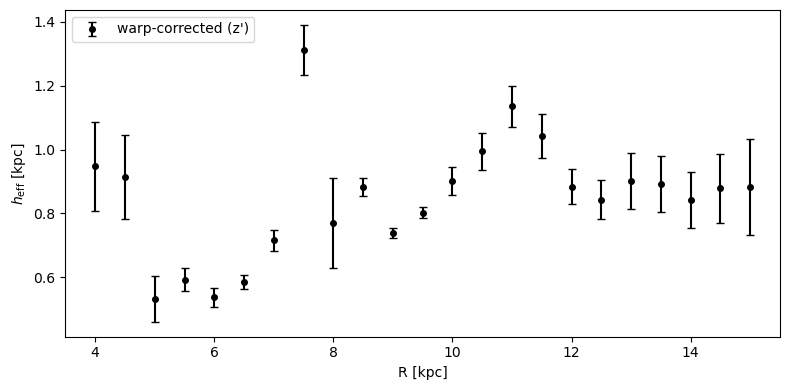

In [17]:
def root_func(z, pars):
    Ystar = mixture_of_sech2(z, pars["A1"], pars["A2"], pars["h1"], pars["h2"], pars["z0"])
    return Ystar - 0.5 * (pars["A1"] + pars["A2"])

n_R_flare = len(R_centers_flare)
h_eff_med_flare_warpcorr = np.full(n_R_flare, np.nan)
h_eff_std_flare_warpcorr = np.full(n_R_flare, np.nan)

for i_R, cell in per_R_flare.items():
    s = cell["samples"]
    h_effs = []
    for i in range(256):
        cs = {k: v[i] for k, v in s.items()}
        cs["h2"] = cs["h1"] + cs["d_h2"]
        hi = 8 * max(cs["h1"], cs["h2"])
        try:
            zstar = brentq(root_func, cs["z0"] + 1e-9, hi, args=(cs,))
            h_effs.append(zstar - cs["z0"])
        except ValueError:
            continue
    if h_effs:
        h_effs = np.array(h_effs)
        h_eff_med_flare_warpcorr[i_R] = np.median(h_effs)
        pcl = np.percentile(h_effs, [16, 84])
        h_eff_std_flare_warpcorr[i_R] = 0.5 * (pcl[1] - pcl[0])

fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(R_centers_flare, h_eff_med_flare_warpcorr, yerr=h_eff_std_flare_warpcorr,
            fmt="o", color="k", ms=4, capsize=3, label="warp-corrected (z')")
ax.legend(loc="upper left")
ax.set_xlabel("R [kpc]")
ax.set_ylabel(r"$h_\mathrm{eff}$ [kpc]")
ax.set_xlim(R_centers_flare[0] - R_width/2, R_centers_flare[-1] + R_width/2)
plt.tight_layout()
plt.show()

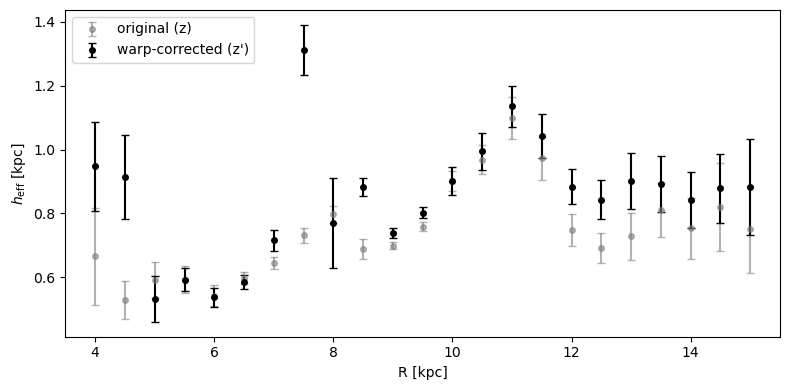

In [18]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(R_centers_flare, h_eff_med_flare, yerr=h_eff_std_flare,
            fmt="o", color="gray", ms=4, capsize=3, alpha=0.6, label="original (z)")
ax.errorbar(R_centers_flare, h_eff_med_flare_warpcorr, yerr=h_eff_std_flare_warpcorr,
            fmt="o", color="k", ms=4, capsize=3, label="warp-corrected (z')")
ax.legend(loc="upper left")
ax.set_xlabel("R [kpc]")
ax.set_ylabel(r"$h_\mathrm{eff}$ [kpc]")
ax.set_xlim(R_centers_flare[0] - R_width/2, R_centers_flare[-1] + R_width/2)
plt.tight_layout()
plt.show()

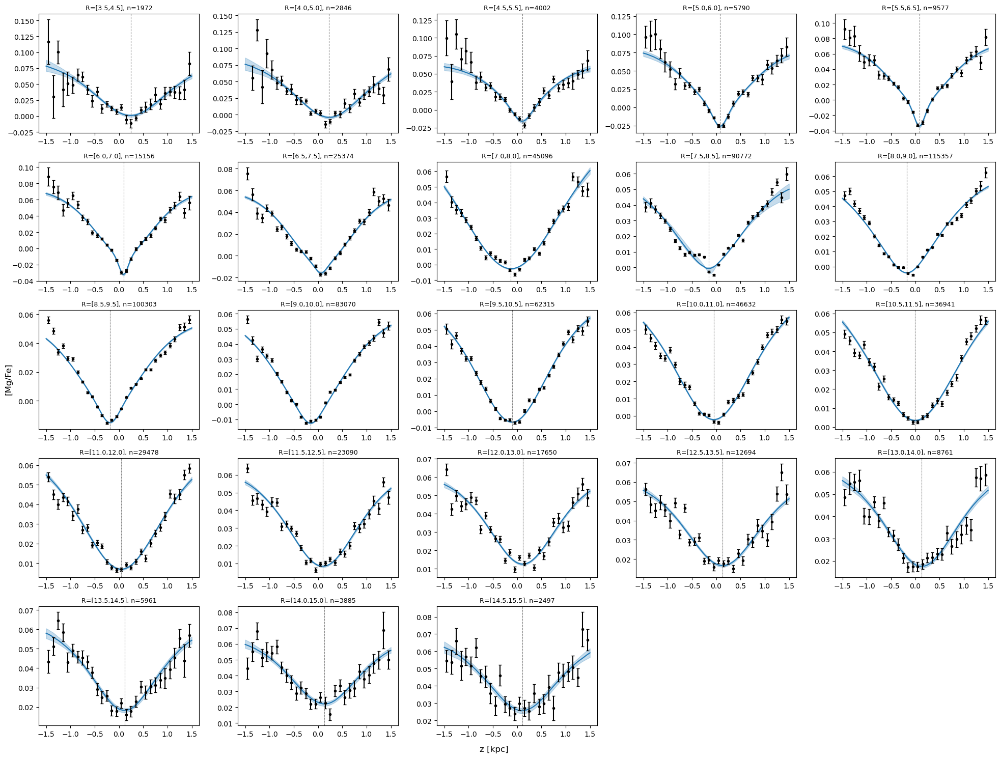

In [20]:
n_bins = len(per_R_flare)
n_cols = 5
n_rows = int(np.ceil(n_bins / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(4*n_cols, 3*n_rows), sharex=False, sharey=False)
axes = axes.flatten()

z_plot = np.linspace(z_fit_min, z_fit_max, 200)

for ax, (i_R, cell) in zip(axes, sorted(per_R_flare.items())):
    s = cell["samples"]

    n_draws = min(200, len(s["z0"]))
    idx = np.random.choice(len(s["z0"]), n_draws, replace=False)
    curves = np.zeros((n_draws, len(z_plot)))
    for j, i in enumerate(idx):
        h2 = s["h1"][i] + s["d_h2"][i]
        curves[j] = s["offset"][i] + mixture_of_sech2(z_plot, s["A1"][i], s["A2"][i], s["h1"][i], h2, s["z0"][i])

    
    med_curve = np.median(curves, axis=0)
    lo, hi = np.percentile(curves, [16, 84], axis=0)

    ax.fill_between(z_plot, lo, hi, color="C0", alpha=0.25)
    ax.plot(z_plot, med_curve, color="C0", lw=1.5)
    ax.errorbar(cell["z_binc"], cell["mean"], yerr=cell["err"], fmt="o", color="k", ms=3, capsize=2)

    ax.set_title(f"R=[{cell['Rlo']:.1f},{cell['Rhi']:.1f}], n={cell['n_stars']}", fontsize=9)
    ax.axvline(np.median(s["z0"]), color="gray", ls="--", lw=0.8)

for ax in axes[n_bins:]:
    ax.axis("off")

fig.supxlabel("z [kpc]")
fig.supylabel("[Mg/Fe]")
plt.tight_layout()
plt.show()

In [21]:
with open("per_R_flare_zsun0.pkl", "rb") as f:
    per_R_flare_orig = pickle.load(f)

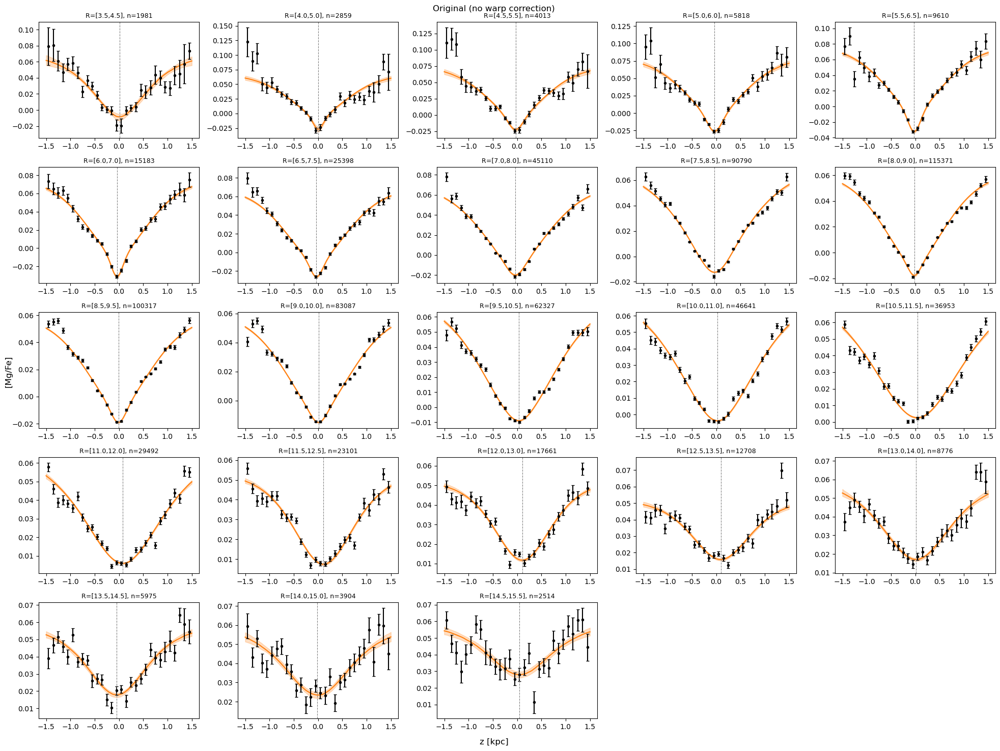

In [23]:
n_bins = len(per_R_flare_orig)
n_cols = 5
n_rows = int(np.ceil(n_bins / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(4*n_cols, 3*n_rows), sharex=False, sharey=False)
axes = axes.flatten()

z_plot = np.linspace(z_fit_min, z_fit_max, 200)

for ax, (i_R, cell) in zip(axes, sorted(per_R_flare_orig.items())):
    s = cell["samples"]

    n_draws = min(200, len(s["z0"]))
    idx = np.random.choice(len(s["z0"]), n_draws, replace=False)
    curves = np.zeros((n_draws, len(z_plot)))
    for j, i in enumerate(idx):
        h2 = s["h1"][i] + s["d_h2"][i]
        curves[j] = s["offset"][i] + mixture_of_sech2(z_plot, s["A1"][i], s["A2"][i], s["h1"][i], h2, s["z0"][i])

    med_curve = np.median(curves, axis=0)
    lo, hi = np.percentile(curves, [16, 84], axis=0)

    ax.fill_between(z_plot, lo, hi, color="C1", alpha=0.25)
    ax.plot(z_plot, med_curve, color="C1", lw=1.5)
    ax.errorbar(cell["z_binc"], cell["mean"], yerr=cell["err"], fmt="o", color="k", ms=3, capsize=2)

    ax.set_title(f"R=[{cell['Rlo']:.1f},{cell['Rhi']:.1f}], n={cell['n_stars']}", fontsize=9)
    ax.axvline(np.median(s["z0"]), color="gray", ls="--", lw=0.8)

for ax in axes[n_bins:]:
    ax.axis("off")

fig.supxlabel("z [kpc]")
fig.supylabel("[Mg/Fe]")
fig.suptitle("Original (no warp correction)")
plt.tight_layout()
plt.show()

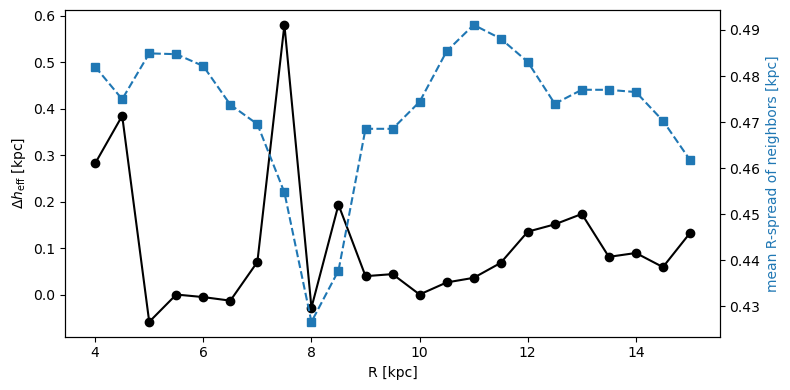

In [24]:
R_arr_full = R_star  # full array, same indexing as Z_median_local / n_neighbors
delta_h_eff = h_eff_med_flare_warpcorr - h_eff_med_flare  # original vs corrected, same R_centers_flare indexing

mean_R_spread_per_bin = np.full(n_R_flare, np.nan)
mean_nn_per_bin = np.full(n_R_flare, np.nan)

for i_R in range(n_R_flare):
    Rlo, Rhi = R_centers_flare[i_R] - R_width/2, R_centers_flare[i_R] + R_width/2
    m = (R_arr_full >= Rlo) & (R_arr_full < Rhi) & good_local
    mean_nn_per_bin[i_R] = np.mean(n_neighbors[m])
    # spread of R among each star's own neighbors, averaged over the bin
    spreads = []
    for idx in np.where(m)[0][:2000]:  # subsample for speed if this is slow
        idxs = tree.query_ball_point(XY[idx], r=1.0)
        if len(idxs) > 1:
            spreads.append(np.std(R_arr_full[idxs]))
    mean_R_spread_per_bin[i_R] = np.mean(spreads) if spreads else np.nan

fig, ax = plt.subplots(figsize=(8,4))
ax2 = ax.twinx()
ax.plot(R_centers_flare, delta_h_eff, "ko-", label=r"$\Delta h_\mathrm{eff}$")
ax2.plot(R_centers_flare, mean_R_spread_per_bin, "C0s--", label="mean R-spread of neighbors")
ax.set_xlabel("R [kpc]")
ax.set_ylabel(r"$\Delta h_\mathrm{eff}$ [kpc]")
ax2.set_ylabel("mean R-spread of neighbors [kpc]", color="C0")
plt.tight_layout()
plt.show()

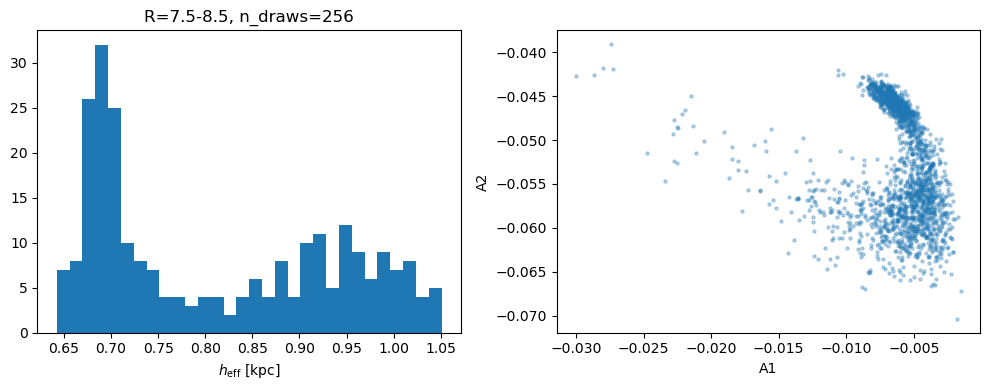

In [28]:
i_R_check = np.argmin(np.abs(R_centers_flare - 8.0))
cell = per_R_flare[i_R_check]  # warp-corrected dict
s = cell["samples"]

h_effs = []
for i in range(256):
    cs = {k: v[i] for k, v in s.items()}
    cs["h2"] = cs["h1"] + cs["d_h2"]
    hi = 8 * max(cs["h1"], cs["h2"])
    try:
        zstar = brentq(root_func, cs["z0"] + 1e-9, hi, args=(cs,))
        h_effs.append(zstar - cs["z0"])
    except ValueError:
        continue

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(h_effs, bins=30)
axes[0].set_xlabel(r"$h_\mathrm{eff}$ [kpc]")
axes[0].set_title(f"R={cell['Rlo']:.1f}-{cell['Rhi']:.1f}, n_draws={len(h_effs)}")

axes[1].scatter(s["A1"], s["A2"], s=5, alpha=0.3)
axes[1].set_xlabel("A1")
axes[1].set_ylabel("A2")
plt.tight_layout()
plt.show()

In [29]:
n_R, n_seg = len(R_edges) - 1, len(SEG_PLOT_heat)

Z_prime_star = np.full(len(Z_star), np.nan)

for i_R in range(n_R):
    Rmin, Rmax = float(R_edges[i_R]), float(R_edges[i_R + 1])
    R_mask = (R_star >= Rmin) & (R_star < Rmax)
    for j_seg in range(n_seg):
        if not ok_grid[i_R, j_seg]:
            continue
        seg_id = SEG_PLOT_heat[j_seg]
        m = R_mask & segm[seg_id]
        Z_prime_star[m] = Z_star[m] - z0_med[i_R, j_seg]

In [30]:
R_centers_flare = np.arange(4, 15 + 1e-3, 0.5)
R_width = 1.0
n_R_flare = len(R_centers_flare)

R_arr, Z_arr, mgfe_arr, err_arr = map(np.asarray, (R_star, Z_prime_star, mgfe_star, mgfe_err_star))
m_base = (np.isfinite(R_arr) & np.isfinite(Z_arr) & np.isfinite(mgfe_arr)
          & np.isfinite(err_arr) & (err_arr > 0))

per_R_flare = {}
key = jr.PRNGKey(0)

for i_R in tqdm(range(n_R_flare), desc="fitting radial bins"):
    Rlo, Rhi = R_centers_flare[i_R] - R_width/2, R_centers_flare[i_R] + R_width/2
    m = m_base & (R_arr >= Rlo) & (R_arr < Rhi)
    n_stars = int(m.sum())
    if n_stars < minN_seg_total:
        continue

    z_binc, mean_mg_fe, mean_mg_fe_err, counts = bin_one(Z_arr[m], mgfe_arr[m], err_arr[m])
    good = (np.isfinite(mean_mg_fe) & np.isfinite(mean_mg_fe_err)
            & (counts >= min_bin_count) & (z_binc >= z_fit_min) & (z_binc <= z_fit_max))
    if good.sum() < min_bins_for_fit:
        continue

    try:
        key, sub = jr.split(key)
        sampler = fit_sech2(np.asarray(z_binc[good], float), np.asarray(mean_mg_fe[good], float),
                             np.asarray(mean_mg_fe_err[good], float), sub, progress_bar=False)
        samples = sampler.get_samples()
        per_R_flare[i_R] = {"Rlo": Rlo, "Rhi": Rhi, "n_stars": n_stars,
                             "z_binc": np.asarray(z_binc[good]), "mean": np.asarray(mean_mg_fe[good]),
                             "err": np.asarray(mean_mg_fe_err[good]),
                             "samples": {k: np.asarray(v) for k, v in samples.items()}}
    except Exception as e:
        print(f"R=[{Rlo:.1f},{Rhi:.1f}]: fit failed -> {e}")

with open("per_R_flare_zsun0_z0corr.pkl", "wb") as f:
    pickle.dump(per_R_flare, f)

fitting radial bins:   0%|                               | 0/23 [00:00<?, ?it/s]/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_98933/2600209016.py:10: RuntimeWarning: invalid value encountered in divide
  mean_mg_fe = stat1.statistic / stat2.statistic
/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_98933/2600209016.py:11: RuntimeWarning: divide by zero encountered in divide
  mean_mg_fe_err = np.sqrt(1 / stat2.statistic + intrinsic_scatter**2)
/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_98933/2600209016.py:18: UserWarning: There are not enough devices to run parallel chains: expected 2 but got 1. Chains will be drawn sequentially. If you are running MCMC in CPU, consider using `numpyro.set_host_device_count(2)` at the beginning of your program. You can double-check how many devices are available in your system using `jax.local_device_count()`.
  sampler = infer.MCMC(
fitting radial bins: 100%|██████████████████████| 23/23 [01:08<00:00,  3.00s/it]


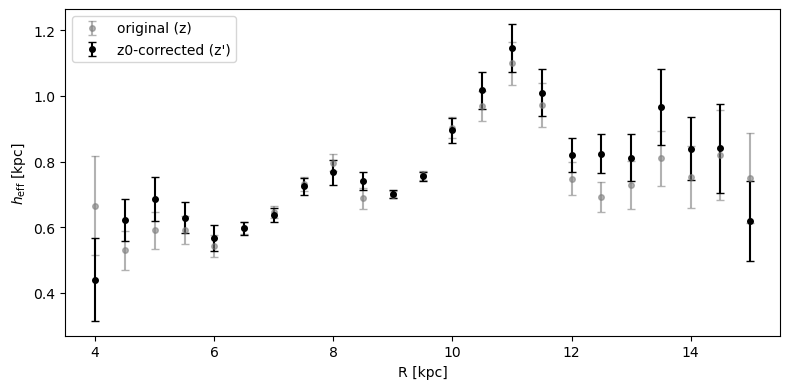

In [31]:
def root_func(z, pars):
    Ystar = mixture_of_sech2(z, pars["A1"], pars["A2"], pars["h1"], pars["h2"], pars["z0"])
    return Ystar - 0.5 * (pars["A1"] + pars["A2"])

h_eff_med_flare_z0corr = np.full(n_R_flare, np.nan)
h_eff_std_flare_z0corr = np.full(n_R_flare, np.nan)

for i_R, cell in per_R_flare.items():
    s = cell["samples"]
    h_effs = []
    for i in range(256):
        cs = {k: v[i] for k, v in s.items()}
        cs["h2"] = cs["h1"] + cs["d_h2"]
        hi = 8 * max(cs["h1"], cs["h2"])
        try:
            zstar = brentq(root_func, cs["z0"] + 1e-9, hi, args=(cs,))
            h_effs.append(zstar - cs["z0"])
        except ValueError:
            continue
    if h_effs:
        h_effs = np.array(h_effs)
        h_eff_med_flare_z0corr[i_R] = np.median(h_effs)
        pcl = np.percentile(h_effs, [16, 84])
        h_eff_std_flare_z0corr[i_R] = 0.5 * (pcl[1] - pcl[0])

fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(R_centers_flare, h_eff_med_flare, yerr=h_eff_std_flare,
            fmt="o", color="gray", ms=4, capsize=3, alpha=0.6, label="original (z)")
ax.errorbar(R_centers_flare, h_eff_med_flare_z0corr, yerr=h_eff_std_flare_z0corr,
            fmt="o", color="k", ms=4, capsize=3, label="z0-corrected (z')")
ax.legend(loc="upper left")
ax.set_xlabel("R [kpc]")
ax.set_ylabel(r"$h_\mathrm{eff}$ [kpc]")
ax.set_xlim(R_centers_flare[0] - R_width/2, R_centers_flare[-1] + R_width/2)
plt.tight_layout()
plt.show()

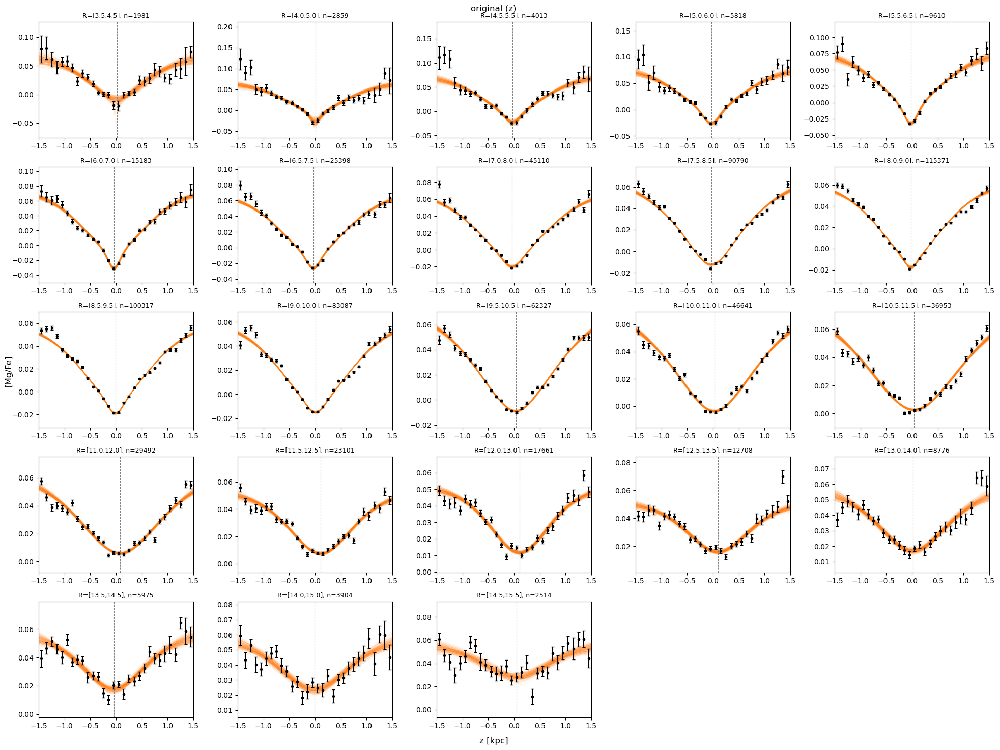

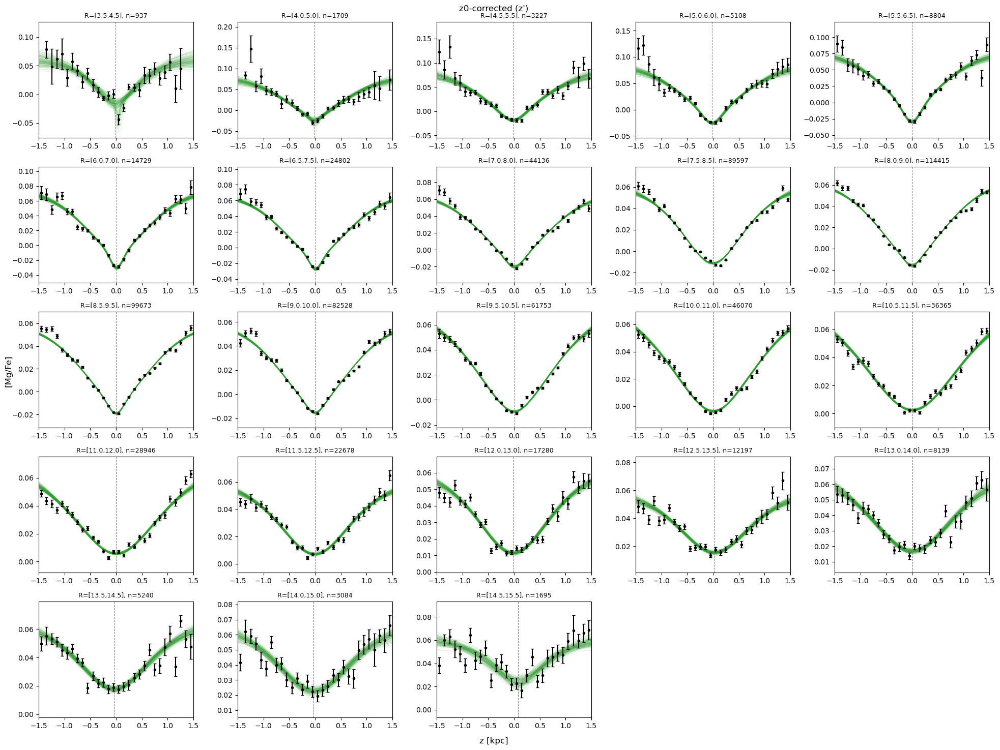

In [34]:
with open("per_R_flare_zsun0.pkl", "rb") as f:
    per_R_flare_orig = pickle.load(f)

n_bins = len(per_R_flare)  # z0-corrected dict, assumed same bins as original
n_cols = 5
n_rows = int(np.ceil(n_bins / n_cols))

z_plot = np.linspace(z_fit_min, z_fit_max, 200)

def draw_panel(ax, cell, color):
    s = cell["samples"]
    n_draws = min(256, len(s["z0"]))
    idx = np.random.choice(len(s["z0"]), n_draws, replace=False)
    for i in idx:
        h2 = s["h1"][i] + s["d_h2"][i]
        curve = s["offset"][i] + mixture_of_sech2(z_plot, s["A1"][i], s["A2"][i], s["h1"][i], h2, s["z0"][i])
        ax.plot(z_plot, curve, color=color, lw=0.5, alpha=0.08)
    ax.errorbar(cell["z_binc"], cell["mean"], yerr=cell["err"], fmt="o", color="k", ms=3, capsize=2, zorder=5)
    ax.axvline(np.median(s["z0"]), color="gray", ls="--", lw=0.8)

# shared y-limits per R bin, computed from both versions' data points together
ylims = {}
for i_R in sorted(per_R_flare.keys()):
    vals = []
    if i_R in per_R_flare:
        c = per_R_flare[i_R]
        vals += list(c["mean"] - c["err"]) + list(c["mean"] + c["err"])
    if i_R in per_R_flare_orig:
        c = per_R_flare_orig[i_R]
        vals += list(c["mean"] - c["err"]) + list(c["mean"] + c["err"])
    if vals:
        pad = 0.15 * (max(vals) - min(vals))
        ylims[i_R] = (min(vals) - pad, max(vals) + pad)

for label, pr, color, tag in [("original (z)", per_R_flare_orig, "C1", "orig"),
                               ("z0-corrected (z')", per_R_flare, "C2", "z0corr")]:
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(4*n_cols, 3*n_rows), sharex=False, sharey=False)
    axes = axes.flatten()

    for ax, (i_R, cell) in zip(axes, sorted(pr.items())):
        draw_panel(ax, cell, color)
        ax.set_title(f"R=[{cell['Rlo']:.1f},{cell['Rhi']:.1f}], n={cell['n_stars']}", fontsize=9)
        ax.set_xlim(z_fit_min, z_fit_max)
        if i_R in ylims:
            ax.set_ylim(*ylims[i_R])

    for ax in axes[len(pr):]:
        ax.axis("off")

    fig.supxlabel("z [kpc]")
    fig.supylabel("[Mg/Fe]")
    fig.suptitle(label)
    plt.tight_layout()
    plt.show()

## LON

In [42]:
import numpyro.distributions as dist
from numpyro import infer

phi_centers_seg = 0.5 * (theta_edges[:-1] + theta_edges[1:])  # same order as SEG_PLOT_heat
MIN_SEG_FOR_RING = 3  
def warp_ring_model_informed(phi, z0, z0_err, phi_ref=np.pi):
    A = numpyro.sample("A", dist.HalfNormal(0.3))
    delta_phi = numpyro.sample("delta_phi", dist.Normal(0.0, np.radians(45)))  # weakly informative
    phi_LON = numpyro.deterministic("phi_LON", phi_ref + delta_phi)
    mu = A * jnp.sin(phi - phi_LON)
    numpyro.sample("obs", dist.Normal(mu, z0_err), obs=z0)

def fit_warp_ring_informed(phi, z0, z0_err, key, phi_ref=np.pi,
                             num_warmup=1000, num_samples=1000, num_chains=2, progress_bar=False):
    sampler = infer.MCMC(
        infer.NUTS(warp_ring_model_informed, dense_mass=True, target_accept_prob=0.9),
        num_warmup=num_warmup, num_samples=num_samples,
        num_chains=num_chains, progress_bar=progress_bar,
    )
    sampler.run(key, phi=jnp.asarray(phi), z0=jnp.asarray(z0), z0_err=jnp.asarray(z0_err), phi_ref=phi_ref)
    return sampler

n_R = len(R_edges) - 1
ring_warp = {}
key = jr.PRNGKey(0)

for i_R in range(n_R):
    mask = ok_grid[i_R, :]
    n_valid = int(mask.sum())
    if n_valid < MIN_SEG_FOR_RING:
        continue

    phi_ring = phi_centers_seg[mask]
    z0_ring  = z0_med[i_R, mask]
    err_ring = z0_std[i_R, mask]
    err_ring = np.where(np.isfinite(err_ring) & (err_ring > 0), err_ring, np.nanmedian(err_ring))

    try:
        key, sub = jr.split(key)
        sampler = fit_warp_ring_informed(phi_ring, z0_ring, err_ring, sub, progress_bar=False)
        samples = sampler.get_samples()
        ring_warp[i_R] = {
            "Rlo": R_edges[i_R], "Rhi": R_edges[i_R+1], "n_seg": n_valid,
            "phi": phi_ring, "z0": z0_ring, "z0_err": err_ring,
            "samples": {k: np.asarray(v) for k, v in samples.items()},
        }
    except Exception as e:
        print(f"ring R=[{R_edges[i_R]:.1f},{R_edges[i_R+1]:.1f}]: fit failed -> {e}")

print(f"fit {len(ring_warp)}/{n_R} rings")

/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_51406/3492136219.py:33: UserWarning: There are not enough devices to run parallel chains: expected 2 but got 1. Chains will be drawn sequentially. If you are running MCMC in CPU, consider using `numpyro.set_host_device_count(2)` at the beginning of your program. You can double-check how many devices are available in your system using `jax.local_device_count()`.
  sampler = infer.MCMC(


fit 24/30 rings


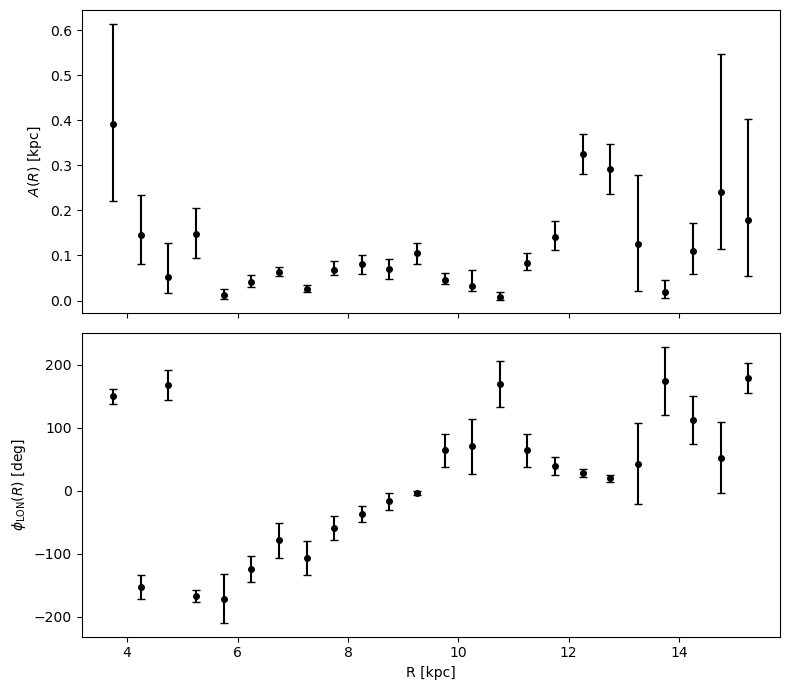

In [70]:
from scipy.stats import circmean, circstd

valid = sorted(ring_warp.keys())
Rc = R_centers[valid]

A_med, A_lo, A_hi = [], [], []
phiLON_med, phiLON_lo, phiLON_hi = [], [], []

for i_R in valid:
    A_draws = ring_warp[i_R]["samples"]["A"]
    A_med.append(np.median(A_draws))
    lo, hi = np.percentile(A_draws, [16, 84])
    A_lo.append(lo); A_hi.append(hi)

    phi_draws = ring_warp[i_R]["samples"]["phi_LON"]  # radians
    cmean = circmean(phi_draws, high=np.pi, low=-np.pi)
    cstd  = circstd(phi_draws, high=np.pi, low=-np.pi)
    phiLON_med.append(np.degrees(cmean))
    phiLON_lo.append(np.degrees(cmean - cstd))
    phiLON_hi.append(np.degrees(cmean + cstd))

A_med, A_lo, A_hi = map(np.array, (A_med, A_lo, A_hi))
phiLON_med, phiLON_lo, phiLON_hi = map(np.array, (phiLON_med, phiLON_lo, phiLON_hi))

fig, axes = plt.subplots(2, 1, figsize=(8, 7), sharex=True)

axes[0].errorbar(Rc, A_med, yerr=[A_med - A_lo, A_hi - A_med],
                  fmt="o", color="k", ms=4, capsize=3)
axes[0].set_ylabel(r"$A(R)$ [kpc]")

axes[1].errorbar(Rc, phiLON_med, yerr=[phiLON_med - phiLON_lo, phiLON_hi - phiLON_med],
                  fmt="o", color="k", ms=4, capsize=3)
axes[1].set_ylabel(r"$\phi_\mathrm{LON}(R)$ [deg]")
axes[1].set_xlabel("R [kpc]")

plt.tight_layout()
plt.show()

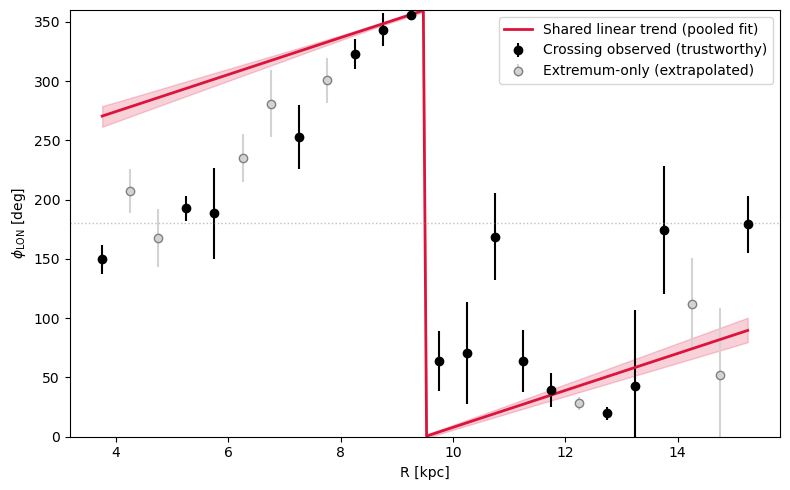

In [72]:
def to_0_360(deg):
    return np.mod(deg, 360)

# compute error sizes BEFORE wrapping anything
delta_lo = phiLON_med_deg - phiLON_lo_deg
delta_hi = phiLON_hi_deg - phiLON_med_deg

# only wrap the central values for plotting position
phiLON_med_360 = to_0_360(phiLON_med_deg)
line_med_360 = to_0_360(line_med)

# for the pooled-fit band, do the same: keep widths, wrap the center
line_delta_lo = line_med - line_lo
line_delta_hi = line_hi - line_med

fig, ax = plt.subplots(figsize=(8, 5))

ax.errorbar(R_vals_plot[crossing_mask], phiLON_med_360[crossing_mask],
            yerr=[delta_lo[crossing_mask], delta_hi[crossing_mask]],
            fmt='o', color='black', label='Crossing observed (trustworthy)')

ax.errorbar(R_vals_plot[~crossing_mask], phiLON_med_360[~crossing_mask],
            yerr=[delta_lo[~crossing_mask], delta_hi[~crossing_mask]],
            fmt='o', color='lightgray', mec='gray', label='Extremum-only (extrapolated)')

ax.plot(R_line, line_med_360, color='crimson', lw=2, label='Shared linear trend (pooled fit)')
ax.fill_between(R_line, line_med_360 - line_delta_lo, line_med_360 + line_delta_hi,
                color='crimson', alpha=0.2)

ax.axhline(180, color='gray', ls=':', lw=1, alpha=0.5)
ax.set_ylim(0, 360)
ax.set_xlabel("R [kpc]")
ax.set_ylabel(r"$\phi_{\rm LON}$ [deg]")
ax.legend()
plt.tight_layout()
plt.show()

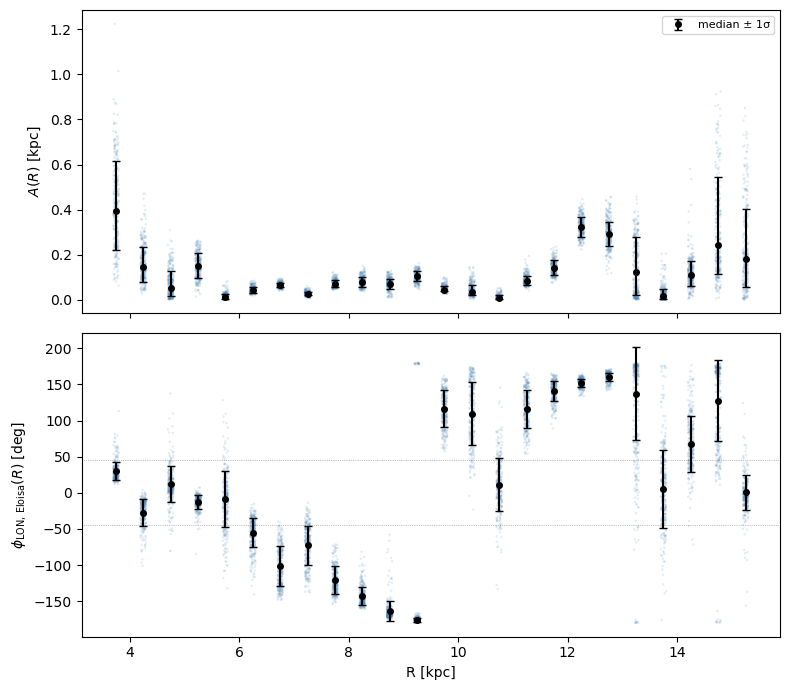

In [87]:
def to_eloisa_frame(phi_deg_emma):
    return np.mod(360.0 - phi_deg_emma, 360) - 180

from scipy.stats import circmean, circstd

n_draws_plot = 300
rng = np.random.default_rng(0)

fig, axes = plt.subplots(2, 1, figsize=(8, 7), sharex=True)

Rc_list, A_med_list, A_lo_list, A_hi_list = [], [], [], []
phiLON_med_eloisa, phiLON_lo_eloisa, phiLON_hi_eloisa = [], [], []

for i_R in valid:
    cell = ring_warp[i_R]
    R_c = 0.5 * (cell["Rlo"] + cell["Rhi"])

    A_draws = cell["samples"]["A"]
    phiLON_draws_deg_emma = np.degrees(cell["samples"]["phi_LON"])
    phiLON_draws_deg_eloisa = to_eloisa_frame(phiLON_draws_deg_emma)

    n_total = len(A_draws)
    idx = rng.choice(n_total, size=min(n_draws_plot, n_total), replace=False)
    jitter = rng.uniform(-0.05, 0.05, size=len(idx))

    axes[0].scatter(R_c + jitter, A_draws[idx], s=3, color='steelblue', alpha=0.15, edgecolors='none')
    axes[1].scatter(R_c + jitter, phiLON_draws_deg_eloisa[idx], s=3, color='steelblue', alpha=0.15, edgecolors='none')

    # recompute circular summary stats fresh, IN Eloisa's frame (don't reuse Emma-frame stats)
    cmean = circmean(np.radians(phiLON_draws_deg_eloisa), high=np.pi, low=-np.pi)
    cstd = circstd(np.radians(phiLON_draws_deg_eloisa), high=np.pi, low=-np.pi)

    Rc_list.append(R_c)
    A_med_list.append(np.median(A_draws))
    lo, hi = np.percentile(A_draws, [16, 84])
    A_lo_list.append(lo); A_hi_list.append(hi)

    phiLON_med_eloisa.append(np.degrees(cmean))
    phiLON_lo_eloisa.append(np.degrees(cmean - cstd))
    phiLON_hi_eloisa.append(np.degrees(cmean + cstd))

Rc_arr = np.array(Rc_list)
A_med_arr, A_lo_arr, A_hi_arr = map(np.array, (A_med_list, A_lo_list, A_hi_list))
phiLON_med_arr = np.array(phiLON_med_eloisa)
phiLON_lo_arr = np.array(phiLON_lo_eloisa)
phiLON_hi_arr = np.array(phiLON_hi_eloisa)

axes[0].errorbar(Rc_arr, A_med_arr, yerr=[A_med_arr - A_lo_arr, A_hi_arr - A_med_arr],
                  fmt="o", color="k", ms=4, capsize=3, zorder=5, label='median ± 1σ')
axes[1].errorbar(Rc_arr, phiLON_med_arr,
                  yerr=[phiLON_med_arr - phiLON_lo_arr, phiLON_hi_arr - phiLON_med_arr],
                  fmt="o", color="k", ms=4, capsize=3, zorder=5)

axes[0].set_ylabel(r"$A(R)$ [kpc]")
axes[0].legend(fontsize=8)
axes[1].set_ylabel(r"$\phi_\mathrm{LON,\,Eloisa}(R)$ [deg]")
axes[1].set_xlabel("R [kpc]")
axes[1].axhline(45, color='gray', lw=0.5, ls=':')
axes[1].axhline(-45, color='gray', lw=0.5, ls=':')

plt.tight_layout()
plt.show()

n_rings: 24 nrows: 6 ncols: 4


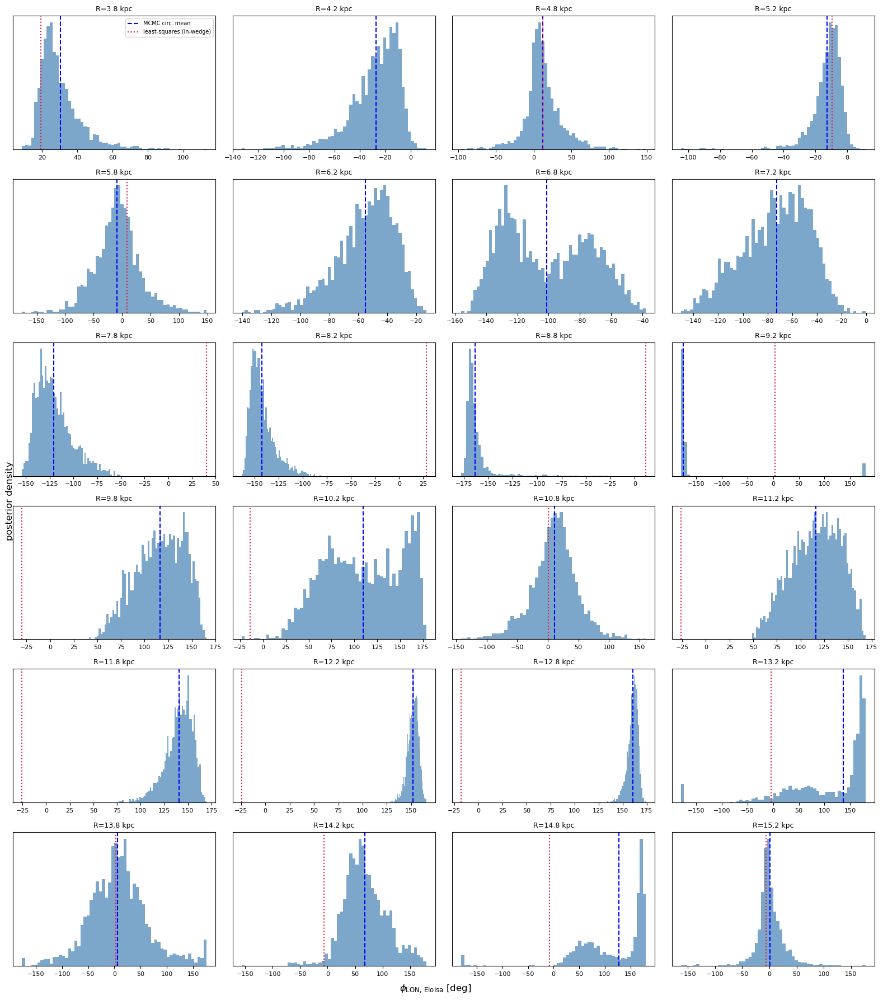

In [94]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.stats import circmean

def to_eloisa_frame(phi_deg_emma):
    return np.mod(360.0 - phi_deg_emma, 360) - 180

def sinusoid(phi, A, phi_LON):
    return A * np.sin(phi - phi_LON)

valid_rings = sorted(ring_warp.keys())
n_rings = len(valid_rings)
ncols = 4
nrows = int(np.ceil(n_rings / ncols))
print("n_rings:", n_rings, "nrows:", nrows, "ncols:", ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(4*ncols, 3*nrows), sharex=False, sharey=False)

for k, i_R in enumerate(valid_rings):
    ax = axes.flat[k]
    cell = ring_warp[i_R]

    phiLON_draws_deg_emma = np.degrees(cell["samples"]["phi_LON"])
    phiLON_draws_deg_eloisa = to_eloisa_frame(phiLON_draws_deg_emma)

    ax.hist(phiLON_draws_deg_eloisa, bins=60, color='steelblue', alpha=0.7, density=True)

    cmean = np.degrees(circmean(np.radians(phiLON_draws_deg_eloisa), high=np.pi, low=-np.pi))
    ax.axvline(cmean, color='blue', ls='--', lw=1.5, label='MCMC circ. mean' if k == 0 else None)

    try:
        phi = cell["phi"]
        z0 = cell["z0"]
        z0_err = cell["z0_err"]
        p0 = [np.ptp(z0) / 2, np.mean(phi)]
        popt, _ = curve_fit(sinusoid, phi, z0, sigma=z0_err, p0=p0,
                             absolute_sigma=True, maxfev=10000)
        A_fit, phiLON_fit = popt

        phi_fine = np.linspace(phi.min(), phi.max(), 500)
        mu_fine = sinusoid(phi_fine, A_fit, phiLON_fit)
        sign_changes = np.where(np.diff(np.sign(mu_fine)) != 0)[0]

        for idx in sign_changes:
            phi_a, phi_b = phi_fine[idx], phi_fine[idx + 1]
            mu_a, mu_b = mu_fine[idx], mu_fine[idx + 1]
            phi_cross = phi_a + (0 - mu_a) * (phi_b - phi_a) / (mu_b - mu_a)
            phi_cross_eloisa = to_eloisa_frame(np.degrees(phi_cross))
            ax.axvline(phi_cross_eloisa, color='crimson', ls=':', lw=1.5,
                       label='least-squares (in-wedge)' if k == 0 else None)

    except RuntimeError:
        pass

    R_c = 0.5 * (cell["Rlo"] + cell["Rhi"])
    ax.set_title(f"R={R_c:.1f} kpc", fontsize=9)
    ax.tick_params(labelsize=8)
    ax.set_yticks([])

for ax in axes.flat[n_rings:]:
    ax.axis('off')

axes.flat[0].legend(fontsize=7, loc='upper right')
fig.supxlabel(r"$\phi_{\rm LON,\,Eloisa}$ [deg]")
fig.supylabel("posterior density")
plt.tight_layout()
plt.show()

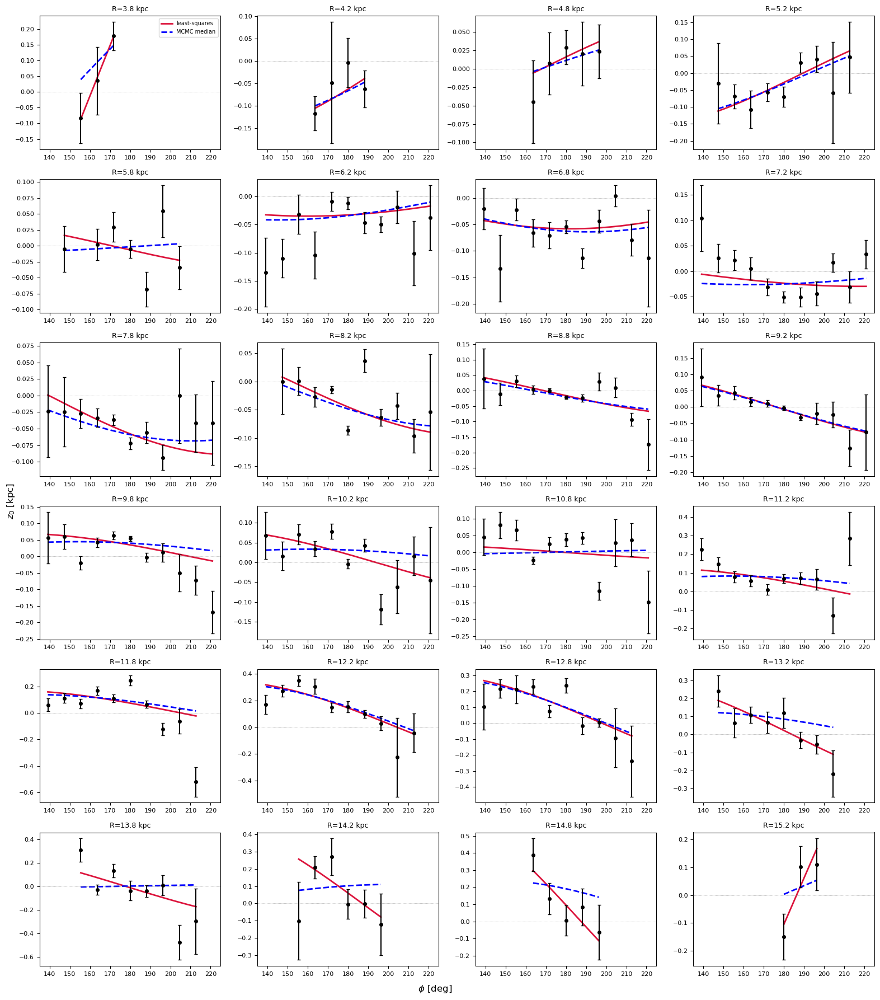

In [97]:
fig, axes = plt.subplots(nrows, ncols, figsize=(4*ncols, 3*nrows), sharex=False, sharey=False)

for k, i_R in enumerate(valid_rings):
    ax = axes.flat[k]
    cell = ring_warp[i_R]

    phi = cell["phi"]
    phi_deg = np.degrees(phi)
    z0 = cell["z0"]
    z0_err = cell["z0_err"]

    ax.errorbar(phi_deg, z0, yerr=z0_err, fmt='o', color='black', ms=4, capsize=2, zorder=5)

    phi_fine = np.linspace(phi.min(), phi.max(), 300)

    # least-squares curve
    try:
        p0 = [np.ptp(z0) / 2, np.mean(phi)]
        popt, _ = curve_fit(sinusoid, phi, z0, sigma=z0_err, p0=p0,
                             absolute_sigma=True, maxfev=10000)
        A_fit, phiLON_fit = popt
        
        mu_ls = sinusoid(phi_fine, A_fit, phiLON_fit)
        ax.plot(np.degrees(phi_fine), mu_ls, color='crimson', lw=2,
                label='least-squares' if k == 0 else None)
    except RuntimeError:
        pass

    # MCMC posterior median curve
    A_med = np.median(cell["samples"]["A"])
    phiLON_med_ring = circmean(cell["samples"]["phi_LON"], high=np.pi, low=-np.pi)
    mu_mcmc = A_med * np.sin(phi_fine - phiLON_med_ring)
    ax.plot(np.degrees(phi_fine), mu_mcmc, color='blue', lw=2, ls='--',
            label='MCMC median' if k == 0 else None)

    ax.axhline(0, color='gray', lw=0.5, ls=':')
    R_c = 0.5 * (cell["Rlo"] + cell["Rhi"])
    ax.set_title(f"R={R_c:.1f} kpc", fontsize=9)
    ax.tick_params(labelsize=8)
    ax.set_xlim(135,225)

for ax in axes.flat[n_rings:]:
    ax.axis('off')
axes.flat[0].legend(fontsize=7, loc='upper right')
fig.supxlabel(r"$\phi$ [deg]")
fig.supylabel(r"$z_0$ [kpc]")
plt.tight_layout()
plt.show()

In [100]:
# find the ring near R=9.2
i_R_check = min(valid_rings, key=lambda i_R: abs(0.5*(ring_warp[i_R]["Rlo"]+ring_warp[i_R]["Rhi"]) - 9.2))
cell = ring_warp[i_R_check]
print("R_c =", 0.5*(cell["Rlo"]+cell["Rhi"]))

phiLON_draws_deg_emma = np.degrees(cell["samples"]["phi_LON"])
phiLON_draws_deg_eloisa = to_eloisa_frame(phiLON_draws_deg_emma)

print("Eloisa-frame posterior draws: min =", phiLON_draws_deg_eloisa.min(),
      "max =", phiLON_draws_deg_eloisa.max())
print("circmean (Eloisa frame):", np.degrees(circmean(np.radians(phiLON_draws_deg_eloisa), high=np.pi, low=-np.pi)))

# least-squares crossing, in both frames
phi = cell["phi"]; z0 = cell["z0"]; z0_err = cell["z0_err"]
p0 = [np.ptp(z0)/2, np.mean(phi)]
popt, _ = curve_fit(sinusoid, phi, z0, sigma=z0_err, p0=p0, absolute_sigma=True, maxfev=10000)
A_fit, phiLON_fit = popt
print("least-squares A_fit:", A_fit, " phiLON_fit (native, deg):", np.degrees(phiLON_fit))

phi_fine = np.linspace(phi.min(), phi.max(), 500)
mu_fine = sinusoid(phi_fine, A_fit, phiLON_fit)
sign_changes = np.where(np.diff(np.sign(mu_fine)) != 0)[0]
for idx in sign_changes:
    phi_a, phi_b = phi_fine[idx], phi_fine[idx+1]
    mu_a, mu_b = mu_fine[idx], mu_fine[idx+1]
    phi_cross = phi_a + (0 - mu_a) * (phi_b - phi_a) / (mu_b - mu_a)
    print("in-wedge crossing (native, deg):", np.degrees(phi_cross),
          "-> Eloisa frame:", to_eloisa_frame(np.degrees(phi_cross)))

R_c = 9.25
Eloisa-frame posterior draws: min = -179.98518516119339 max = 179.9953401023834
circmean (Eloisa frame): -176.0747805155208
least-squares A_fit: -0.11024823692408138  phiLON_fit (native, deg): 176.21667581394618
in-wedge crossing (native, deg): 176.21667582205296 -> Eloisa frame: 3.783324177947037


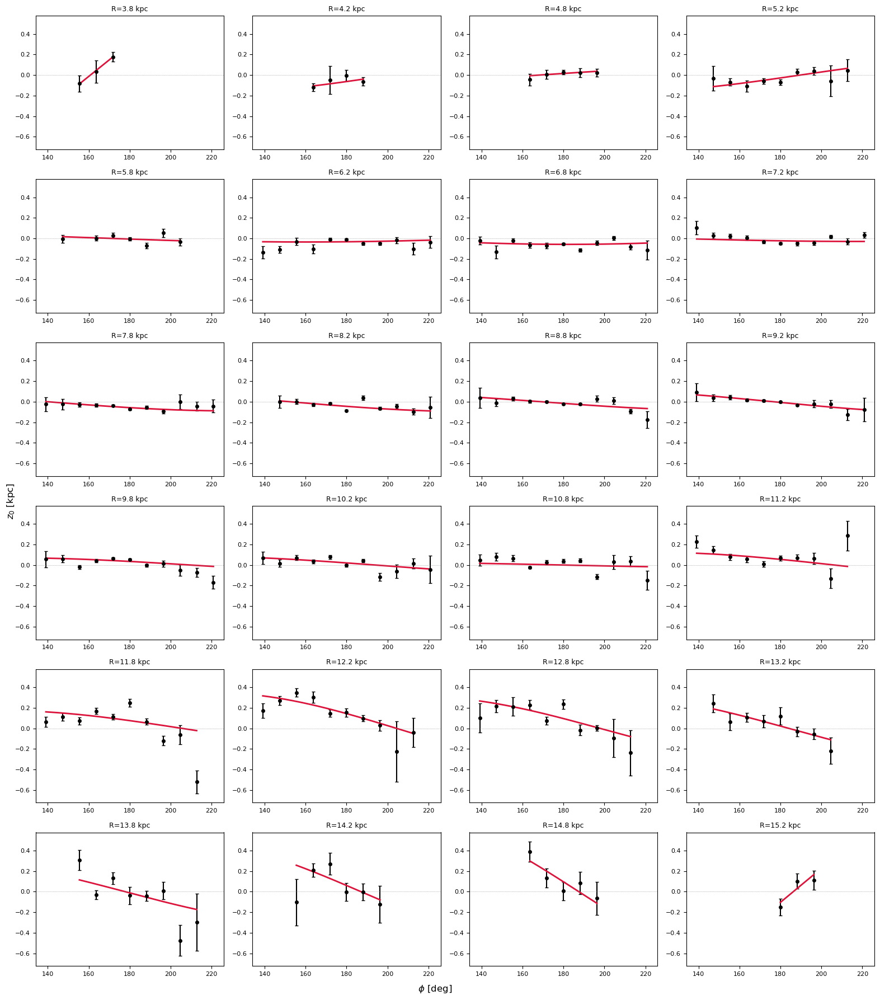

In [77]:
from scipy.optimize import curve_fit

def sinusoid(phi, A, phi_LON):
    return A * np.sin(phi - phi_LON)

# --- compute global axis limits across all rings first ---
all_phi_deg, all_z0, all_z0_err = [], [], []
for i_R in valid_rings:
    cell = ring_warp[i_R]
    all_phi_deg.append(np.degrees(cell["phi"]))
    all_z0.append(cell["z0"])
    all_z0_err.append(cell["z0_err"])

all_phi_deg = np.concatenate(all_phi_deg)
all_z0 = np.concatenate(all_z0)
all_z0_err = np.concatenate(all_z0_err)

xpad = 5
ypad = 0.1 * (all_z0.max() - all_z0.min())
xlim = (all_phi_deg.min() - xpad, all_phi_deg.max() + xpad)
ylim = ((all_z0 - all_z0_err).min() - ypad, (all_z0 + all_z0_err).max() + ypad)

# --- plot ---
fig, axes = plt.subplots(nrows, ncols, figsize=(4*ncols, 3*nrows), sharex=False, sharey=False)

for k, i_R in enumerate(valid_rings):
    ax = axes.flat[k]
    cell = ring_warp[i_R]

    phi = cell["phi"]
    phi_deg = np.degrees(phi)
    z0 = cell["z0"]
    z0_err = cell["z0_err"]

    ax.errorbar(phi_deg, z0, yerr=z0_err, fmt='o', color='black', ms=4, capsize=2)

    # direct least-squares fit to THIS ring's plotted points
    try:
        p0 = [np.ptp(z0) / 2, np.mean(phi)]
        popt, _ = curve_fit(sinusoid, phi, z0, sigma=z0_err, p0=p0,
                             absolute_sigma=True, maxfev=10000)
        A_fit, phiLON_fit = popt

        phi_fine = np.linspace(phi.min(), phi.max(), 200)
        mu_fine = sinusoid(phi_fine, A_fit, phiLON_fit)
        ax.plot(np.degrees(phi_fine), mu_fine, color='crimson', lw=2)
    except RuntimeError:
        ax.text(0.5, 0.5, "fit failed", transform=ax.transAxes,
                ha='center', va='center', fontsize=8, color='gray')

    ax.axhline(0, color='gray', lw=0.5, ls=':')
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    R_c = 0.5 * (cell["Rlo"] + cell["Rhi"])
    ax.set_title(f"R={R_c:.1f} kpc", fontsize=9)
    ax.tick_params(labelsize=8)
    ax.tick_params(labelsize=8)

for ax in axes.flat[n_rings:]:
    ax.axis('off')

fig.supxlabel(r"$\phi$ [deg]")
fig.supylabel(r"$z_0$ [kpc]")
plt.tight_layout()
plt.show()

In [78]:
i_R_test = valid_rings[5]
print("ring_warp Rlo/Rhi:", ring_warp[i_R_test]["Rlo"], ring_warp[i_R_test]["Rhi"])
# compare against your original bin-edges array, e.g.:
print("original R bin edges:", R_edges[i_R_test], R_edges[i_R_test+1])

ring_warp Rlo/Rhi: 6.0 6.5
original R bin edges: 6.0 6.5


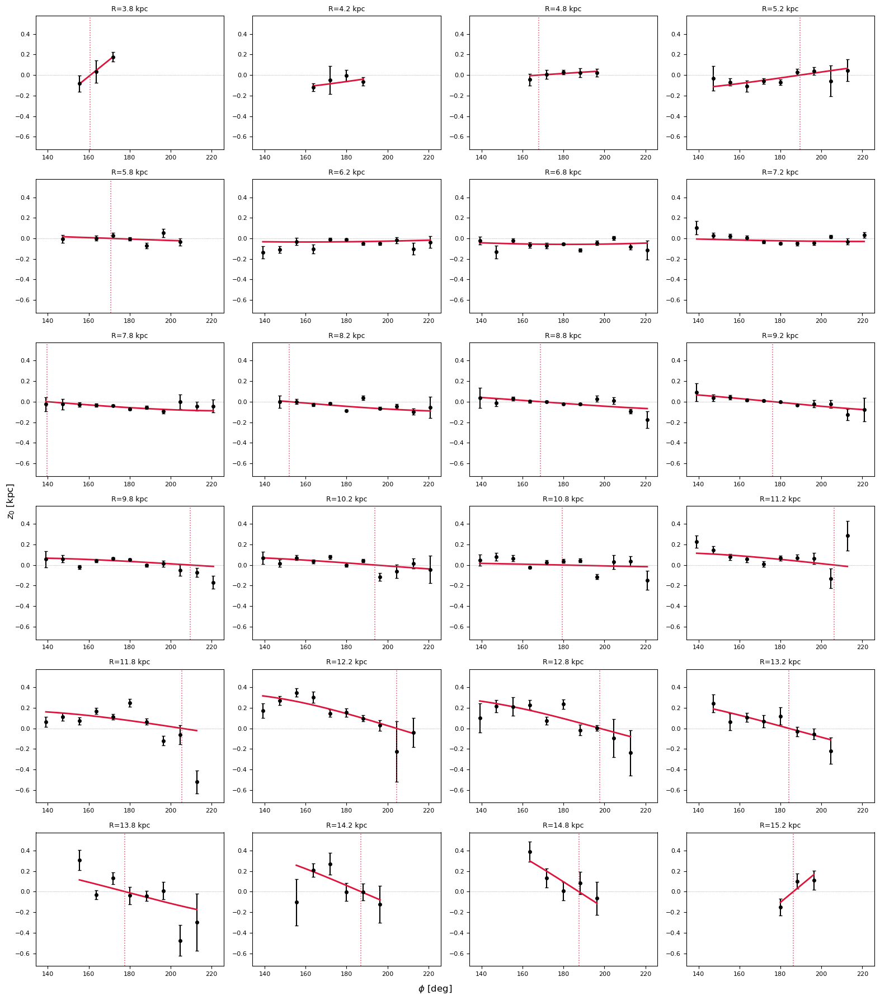

In [79]:
fig, axes = plt.subplots(nrows, ncols, figsize=(4*ncols, 3*nrows), sharex=False, sharey=False)

for k, i_R in enumerate(valid_rings):
    ax = axes.flat[k]
    cell = ring_warp[i_R]

    phi = cell["phi"]
    phi_deg = np.degrees(phi)
    z0 = cell["z0"]
    z0_err = cell["z0_err"]

    ax.errorbar(phi_deg, z0, yerr=z0_err, fmt='o', color='black', ms=4, capsize=2)

    try:
        p0 = [np.ptp(z0) / 2, np.mean(phi)]
        popt, _ = curve_fit(sinusoid, phi, z0, sigma=z0_err, p0=p0,
                             absolute_sigma=True, maxfev=10000)
        A_fit, phiLON_fit = popt

        phi_fine = np.linspace(phi.min(), phi.max(), 500)
        mu_fine = sinusoid(phi_fine, A_fit, phiLON_fit)
        ax.plot(np.degrees(phi_fine), mu_fine, color='crimson', lw=2)

        # find zero crossings of the fit line within the observed range
        sign_changes = np.where(np.diff(np.sign(mu_fine)) != 0)[0]
        for idx in sign_changes:
            # linear interpolation between the two bracketing points for a cleaner crossing estimate
            phi_a, phi_b = phi_fine[idx], phi_fine[idx + 1]
            mu_a, mu_b = mu_fine[idx], mu_fine[idx + 1]
            phi_cross = phi_a + (0 - mu_a) * (phi_b - phi_a) / (mu_b - mu_a)
            ax.axvline(np.degrees(phi_cross), color='crimson', ls=':', lw=1.2, alpha=0.7)

    except RuntimeError:
        ax.text(0.5, 0.5, "fit failed", transform=ax.transAxes,
                ha='center', va='center', fontsize=8, color='gray')

    ax.axhline(0, color='gray', lw=0.5, ls=':')
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

    R_c = 0.5 * (cell["Rlo"] + cell["Rhi"])
    ax.set_title(f"R={R_c:.1f} kpc", fontsize=9)
    ax.tick_params(labelsize=8)

for ax in axes.flat[n_rings:]:
    ax.axis('off')

fig.supxlabel(r"$\phi$ [deg]")
fig.supylabel(r"$z_0$ [kpc]")
plt.tight_layout()
plt.show()

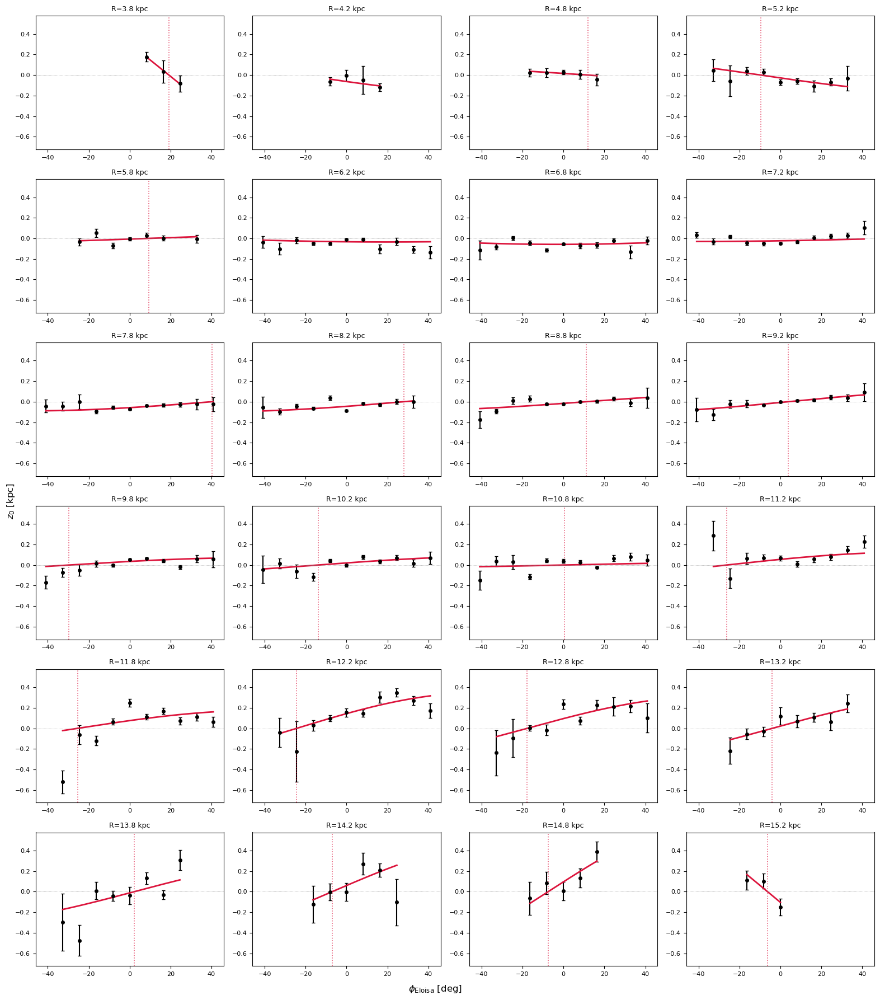

In [99]:
def to_eloisa_frame(phi_deg_emma):
    return np.mod(360.0 - phi_deg_emma, 360) - 180

# --- compute shared axis limits in Eloisa's frame first ---
all_phi_deg_eloisa, all_z0, all_z0_err = [], [], []
for i_R in valid_rings:
    cell = ring_warp[i_R]
    all_phi_deg_eloisa.append(to_eloisa_frame(np.degrees(cell["phi"])))
    all_z0.append(cell["z0"])
    all_z0_err.append(cell["z0_err"])

all_phi_deg_eloisa = np.concatenate(all_phi_deg_eloisa)
all_z0 = np.concatenate(all_z0)
all_z0_err = np.concatenate(all_z0_err)

xpad = 5
ypad = 0.1 * (all_z0.max() - all_z0.min())
xlim_eloisa = (all_phi_deg_eloisa.min() - xpad, all_phi_deg_eloisa.max() + xpad)
ylim = ((all_z0 - all_z0_err).min() - ypad, (all_z0 + all_z0_err).max() + ypad)

# --- plot ---
fig, axes = plt.subplots(nrows, ncols, figsize=(4*ncols, 3*nrows), sharex=False, sharey=False)

for k, i_R in enumerate(valid_rings):
    ax = axes.flat[k]
    cell = ring_warp[i_R]

    phi = cell["phi"]
    phi_deg_eloisa = to_eloisa_frame(np.degrees(phi))
    z0 = cell["z0"]
    z0_err = cell["z0_err"]

    ax.errorbar(phi_deg_eloisa, z0, yerr=z0_err, fmt='o', color='black', ms=4, capsize=2)

    try:
        p0 = [np.ptp(z0) / 2, np.mean(phi)]
        popt, _ = curve_fit(sinusoid, phi, z0, sigma=z0_err, p0=p0,
                             absolute_sigma=True, maxfev=10000)
        A_fit, phiLON_fit = popt

        phi_fine = np.linspace(phi.min(), phi.max(), 500)
        mu_fine = sinusoid(phi_fine, A_fit, phiLON_fit)

        phi_fine_eloisa = to_eloisa_frame(np.degrees(phi_fine))
        order = np.argsort(phi_fine_eloisa)
        ax.plot(phi_fine_eloisa[order], mu_fine[order], color='crimson', lw=2)

        sign_changes = np.where(np.diff(np.sign(mu_fine)) != 0)[0]
        for idx in sign_changes:
            phi_a, phi_b = phi_fine[idx], phi_fine[idx + 1]
            mu_a, mu_b = mu_fine[idx], mu_fine[idx + 1]
            phi_cross = phi_a + (0 - mu_a) * (phi_b - phi_a) / (mu_b - mu_a)
            phi_cross_eloisa = to_eloisa_frame(np.degrees(phi_cross))
            ax.axvline(phi_cross_eloisa, color='crimson', ls=':', lw=1.2, alpha=0.7)

    except RuntimeError:
        ax.text(0.5, 0.5, "fit failed", transform=ax.transAxes,
                ha='center', va='center', fontsize=8, color='gray')

    
    ax.axhline(0, color='gray', lw=0.5, ls=':')
    ax.set_xlim(xlim_eloisa)
    ax.set_ylim(ylim)

    R_c = 0.5 * (cell["Rlo"] + cell["Rhi"])
    ax.set_title(f"R={R_c:.1f} kpc", fontsize=9)
    ax.tick_params(labelsize=8)

for ax in axes.flat[n_rings:]:
    ax.axis('off')

fig.supxlabel(r"$\phi_{\rm Eloisa}$ [deg]")
fig.supylabel(r"$z_0$ [kpc]")
plt.tight_layout()
plt.show()

In [80]:
from scipy.stats import circmean, circstd

crossing_phis = []  # in degrees

for i_R in valid_rings:
    cell = ring_warp[i_R]
    phi = cell["phi"]
    z0 = cell["z0"]
    z0_err = cell["z0_err"]

    try:
        p0 = [np.ptp(z0) / 2, np.mean(phi)]
        popt, _ = curve_fit(sinusoid, phi, z0, sigma=z0_err, p0=p0,
                             absolute_sigma=True, maxfev=10000)
        A_fit, phiLON_fit = popt

        phi_fine = np.linspace(phi.min(), phi.max(), 500)
        mu_fine = sinusoid(phi_fine, A_fit, phiLON_fit)

        sign_changes = np.where(np.diff(np.sign(mu_fine)) != 0)[0]
        for idx in sign_changes:
            phi_a, phi_b = phi_fine[idx], phi_fine[idx + 1]
            mu_a, mu_b = mu_fine[idx], mu_fine[idx + 1]
            phi_cross = phi_a + (0 - mu_a) * (phi_b - phi_a) / (mu_b - mu_a)
            crossing_phis.append(np.degrees(phi_cross))

    except RuntimeError:
        continue

crossing_phis = np.array(crossing_phis)
print(f"Number of rings with an observed crossing: {len(crossing_phis)} / {len(valid_rings)}")
print("Individual crossing azimuths (deg):", np.round(crossing_phis, 1))

mean_crossing = circmean(crossing_phis, high=360, low=0)
std_crossing = circstd(crossing_phis, high=360, low=0)
print(f"\nAverage crossover azimuth: {mean_crossing:.1f} deg  (circular std: {std_crossing:.1f} deg)")

Number of rings with an observed crossing: 20 / 24
Individual crossing azimuths (deg): [160.8 168.  189.6 170.7 139.7 152.  168.8 176.2 209.6 193.8 179.5 206.3
 205.4 204.3 197.7 184.  177.7 187.  187.5 186.3]

Average crossover azimuth: 182.4 deg  (circular std: 18.2 deg)


In [81]:
from scipy.stats import circmean, circstd

R_MIN_CUT = 8.277  # matches nb3's joint-fit R_min

crossing_phis_all = []
crossing_phis_cut = []

for i_R in valid_rings:
    cell = ring_warp[i_R]
    phi = cell["phi"]
    z0 = cell["z0"]
    z0_err = cell["z0_err"]
    R_c = 0.5 * (cell["Rlo"] + cell["Rhi"])

    try:
        p0 = [np.ptp(z0) / 2, np.mean(phi)]
        popt, _ = curve_fit(sinusoid, phi, z0, sigma=z0_err, p0=p0,
                             absolute_sigma=True, maxfev=10000)
        A_fit, phiLON_fit = popt

        phi_fine = np.linspace(phi.min(), phi.max(), 500)
        mu_fine = sinusoid(phi_fine, A_fit, phiLON_fit)

        sign_changes = np.where(np.diff(np.sign(mu_fine)) != 0)[0]
        for idx in sign_changes:
            phi_a, phi_b = phi_fine[idx], phi_fine[idx + 1]
            mu_a, mu_b = mu_fine[idx], mu_fine[idx + 1]
            phi_cross = phi_a + (0 - mu_a) * (phi_b - phi_a) / (mu_b - mu_a)
            phi_cross_deg = np.degrees(phi_cross)

            crossing_phis_all.append(phi_cross_deg)
            if R_c >= R_MIN_CUT:
                crossing_phis_cut.append(phi_cross_deg)

    except RuntimeError:
        continue

crossing_phis_all = np.array(crossing_phis_all)
crossing_phis_cut = np.array(crossing_phis_cut)

mean_all = circmean(crossing_phis_all, high=360, low=0)
mean_cut = circmean(crossing_phis_cut, high=360, low=0)
std_cut = circstd(crossing_phis_cut, high=360, low=0)

print(f"All rings (R>=3.8 kpc): {len(crossing_phis_all)} crossings, mean = {mean_all:.1f} deg")
print(f"R >= {R_MIN_CUT} kpc only: {len(crossing_phis_cut)} crossings, mean = {mean_cut:.1f} deg (circular std: {std_cut:.1f} deg)")

All rings (R>=3.8 kpc): 20 crossings, mean = 182.4 deg
R >= 8.277 kpc only: 14 crossings, mean = 190.3 deg (circular std: 12.4 deg)


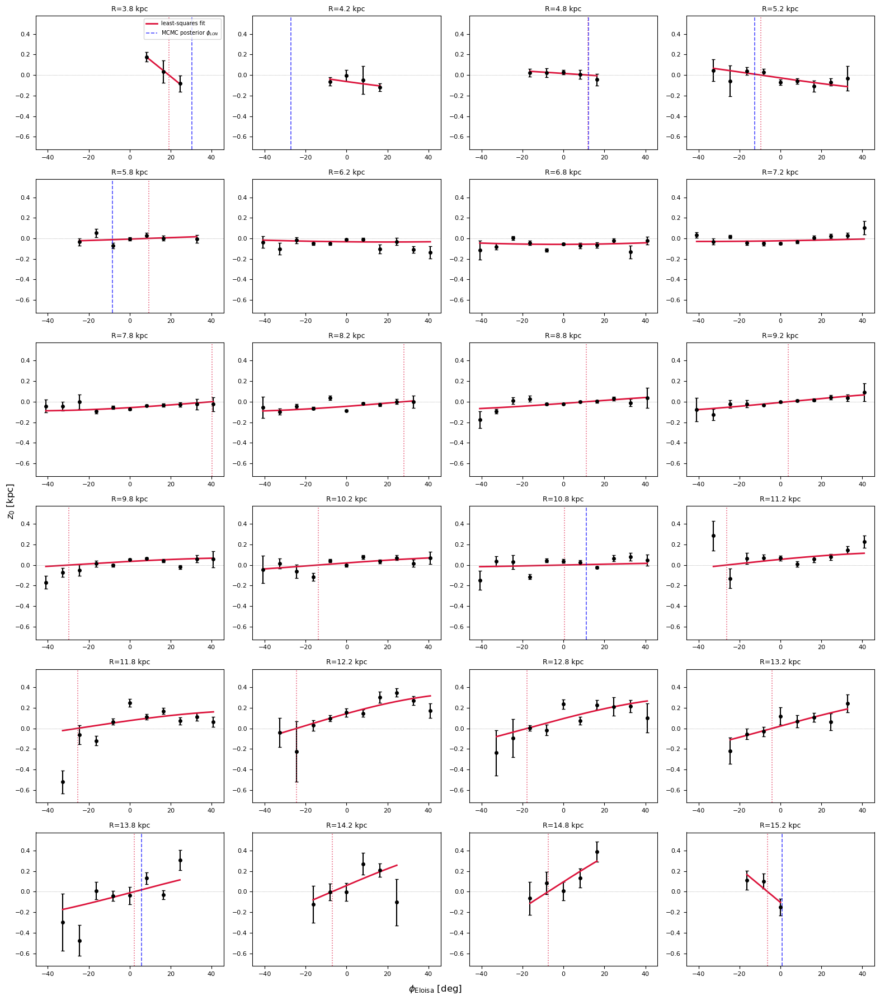

In [84]:
from scipy.stats import circmean, circstd

def to_eloisa_frame(phi_deg_emma):
    return np.mod(360.0 - phi_deg_emma, 360) - 180

# --- MCMC-based phi_LON per ring (native Emma frame, radians -> degrees) ---
valid = sorted(ring_warp.keys())
phiLON_med_mcmc = {}
for i_R in valid:
    phi_draws = ring_warp[i_R]["samples"]["phi_LON"]  # radians
    cmean = circmean(phi_draws, high=np.pi, low=-np.pi)
    phiLON_med_mcmc[i_R] = np.degrees(cmean)  # still in Emma's native frame

# --- shared axis limits in Eloisa's frame ---
all_phi_deg_eloisa, all_z0, all_z0_err = [], [], []
for i_R in valid_rings:
    cell = ring_warp[i_R]
    all_phi_deg_eloisa.append(to_eloisa_frame(np.degrees(cell["phi"])))
    all_z0.append(cell["z0"])
    all_z0_err.append(cell["z0_err"])

all_phi_deg_eloisa = np.concatenate(all_phi_deg_eloisa)
all_z0 = np.concatenate(all_z0)
all_z0_err = np.concatenate(all_z0_err)

xpad = 5
ypad = 0.1 * (all_z0.max() - all_z0.min())
xlim_eloisa = (all_phi_deg_eloisa.min() - xpad, all_phi_deg_eloisa.max() + xpad)
ylim = ((all_z0 - all_z0_err).min() - ypad, (all_z0 + all_z0_err).max() + ypad)

# --- plot ---
fig, axes = plt.subplots(nrows, ncols, figsize=(4*ncols, 3*nrows), sharex=False, sharey=False)

for k, i_R in enumerate(valid_rings):
    ax = axes.flat[k]
    cell = ring_warp[i_R]

    phi = cell["phi"]
    phi_deg_eloisa = to_eloisa_frame(np.degrees(phi))
    z0 = cell["z0"]
    z0_err = cell["z0_err"]

    ax.errorbar(phi_deg_eloisa, z0, yerr=z0_err, fmt='o', color='black', ms=4, capsize=2)

    # least-squares fit (as before)
    try:
        p0 = [np.ptp(z0) / 2, np.mean(phi)]
        popt, _ = curve_fit(sinusoid, phi, z0, sigma=z0_err, p0=p0,
                             absolute_sigma=True, maxfev=10000)
        A_fit, phiLON_fit = popt

        phi_fine = np.linspace(phi.min(), phi.max(), 500)
        mu_fine = sinusoid(phi_fine, A_fit, phiLON_fit)

        phi_fine_eloisa = to_eloisa_frame(np.degrees(phi_fine))
        order = np.argsort(phi_fine_eloisa)
        ax.plot(phi_fine_eloisa[order], mu_fine[order], color='crimson', lw=2,
                label='least-squares fit' if k == 0 else None)

        sign_changes = np.where(np.diff(np.sign(mu_fine)) != 0)[0]
        for idx in sign_changes:
            phi_a, phi_b = phi_fine[idx], phi_fine[idx + 1]
            mu_a, mu_b = mu_fine[idx], mu_fine[idx + 1]
            phi_cross = phi_a + (0 - mu_a) * (phi_b - phi_a) / (mu_b - mu_a)
            phi_cross_eloisa = to_eloisa_frame(np.degrees(phi_cross))
            ax.axvline(phi_cross_eloisa, color='crimson', ls=':', lw=1.2, alpha=0.7)

    except RuntimeError:
        ax.text(0.5, 0.5, "fit failed", transform=ax.transAxes,
                ha='center', va='center', fontsize=8, color='gray')

    # MCMC posterior phi_LON, converted to Eloisa's frame
    if i_R in phiLON_med_mcmc:
        phiLON_mcmc_eloisa = to_eloisa_frame(phiLON_med_mcmc[i_R])
        ax.axvline(phiLON_mcmc_eloisa, color='blue', ls='--', lw=1.2, alpha=0.7,
                   label='MCMC posterior $\\phi_{LON}$' if k == 0 else None)

    ax.axhline(0, color='gray', lw=0.5, ls=':')
    ax.set_xlim(xlim_eloisa)
    ax.set_ylim(ylim)

    R_c = 0.5 * (cell["Rlo"] + cell["Rhi"])
    ax.set_title(f"R={R_c:.1f} kpc", fontsize=9)
    ax.tick_params(labelsize=8)

for ax in axes.flat[n_rings:]:
    ax.axis('off')

axes.flat[0].legend(fontsize=7, loc='upper right')
fig.supxlabel(r"$\phi_{\rm Eloisa}$ [deg]")
fig.supylabel(r"$z_0$ [kpc]")
plt.tight_layout()
plt.show()

In [101]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.stats import circmean

def to_eloisa_frame(phi_deg_emma):
    return np.mod(360.0 - phi_deg_emma, 360) - 180

def sinusoid(phi, A, phi_LON):
    return A * np.sin(phi - phi_LON)

def fit_ring_normalized(phi, z0, z0_err):
    """Least-squares fit, normalized to the A>0 convention (matches the MCMC's HalfNormal prior on A)."""
    p0 = [np.ptp(z0) / 2, np.mean(phi)]
    popt, _ = curve_fit(sinusoid, phi, z0, sigma=z0_err, p0=p0,
                         absolute_sigma=True, maxfev=10000)
    A_fit, phiLON_fit = popt
    if A_fit < 0:
        A_fit = -A_fit
        phiLON_fit = phiLON_fit + np.pi
    phiLON_fit = np.mod(phiLON_fit + np.pi, 2*np.pi) - np.pi  # keep in (-pi, pi]
    return A_fit, phiLON_fit

valid_rings = sorted(ring_warp.keys())
n_rings = len(valid_rings)
ncols = 4
nrows = int(np.ceil(n_rings / ncols))
print("n_rings:", n_rings, "nrows:", nrows, "ncols:", ncols)

n_rings: 24 nrows: 6 ncols: 4


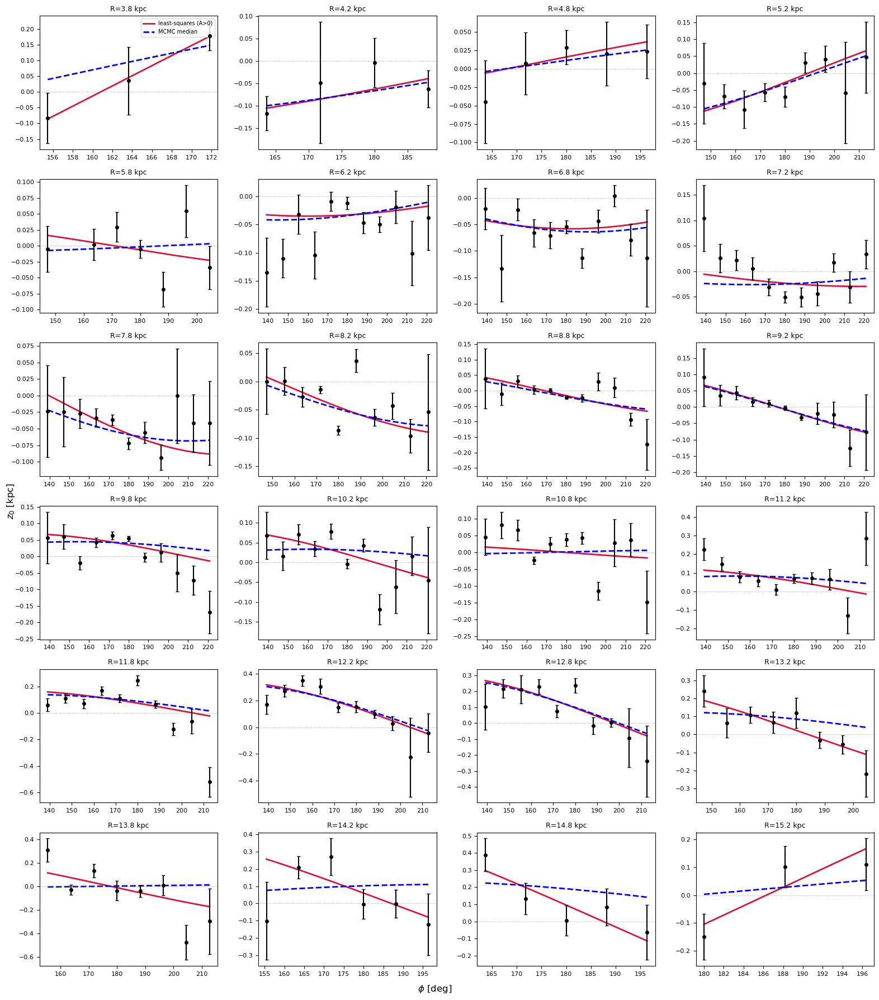

In [102]:
fig, axes = plt.subplots(nrows, ncols, figsize=(4*ncols, 3*nrows), sharex=False, sharey=False)

for k, i_R in enumerate(valid_rings):
    ax = axes.flat[k]
    cell = ring_warp[i_R]

    phi = cell["phi"]
    phi_deg = np.degrees(phi)
    z0 = cell["z0"]
    z0_err = cell["z0_err"]

    ax.errorbar(phi_deg, z0, yerr=z0_err, fmt='o', color='black', ms=4, capsize=2, zorder=5)

    phi_fine = np.linspace(phi.min(), phi.max(), 300)

    try:
        A_fit, phiLON_fit = fit_ring_normalized(phi, z0, z0_err)
        mu_ls = sinusoid(phi_fine, A_fit, phiLON_fit)
        ax.plot(np.degrees(phi_fine), mu_ls, color='crimson', lw=2,
                label='least-squares (A>0)' if k == 0 else None)
    except RuntimeError:
        pass

    A_med = np.median(cell["samples"]["A"])
    phiLON_med_ring = circmean(cell["samples"]["phi_LON"], high=np.pi, low=-np.pi)
    mu_mcmc = A_med * np.sin(phi_fine - phiLON_med_ring)
    ax.plot(np.degrees(phi_fine), mu_mcmc, color='blue', lw=2, ls='--',
            label='MCMC median' if k == 0 else None)

    ax.axhline(0, color='gray', lw=0.5, ls=':')
    R_c = 0.5 * (cell["Rlo"] + cell["Rhi"])
    ax.set_title(f"R={R_c:.1f} kpc", fontsize=9)
    ax.tick_params(labelsize=8)

for ax in axes.flat[n_rings:]:
    ax.axis('off')

axes.flat[0].legend(fontsize=7, loc='upper right')
fig.supxlabel(r"$\phi$ [deg]")
fig.supylabel(r"$z_0$ [kpc]")
plt.tight_layout()
plt.show()

n_rings: 24 nrows: 6 ncols: 4


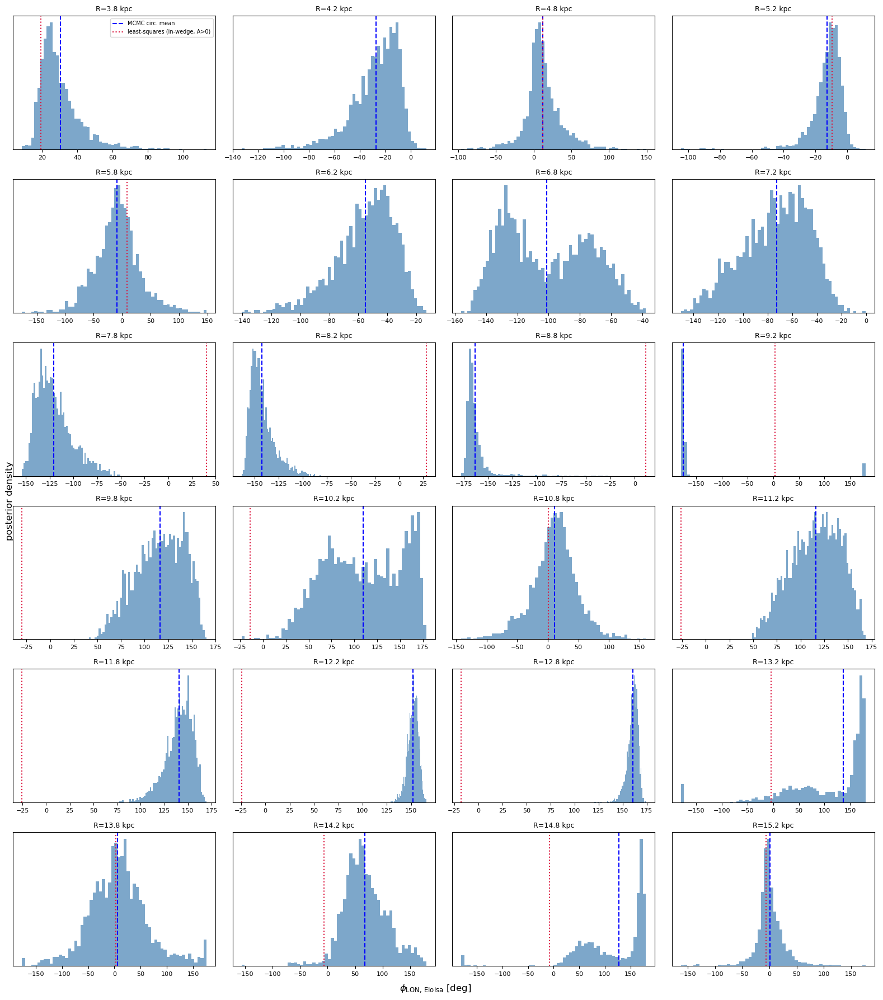

In [107]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.stats import circmean

def to_eloisa_frame(phi_deg_emma):
    return np.mod(360.0 - phi_deg_emma, 360) - 180

def sinusoid(phi, A, phi_LON):
    return A * np.sin(phi - phi_LON)

def fit_ring_normalized(phi, z0, z0_err):
    """Least-squares fit, normalized to the A>0 convention (matches the MCMC's HalfNormal prior on A)."""
    p0 = [np.ptp(z0) / 2, np.mean(phi)]
    popt, _ = curve_fit(sinusoid, phi, z0, sigma=z0_err, p0=p0,
                         absolute_sigma=True, maxfev=10000)
    A_fit, phiLON_fit = popt
    if A_fit < 0:
        A_fit = -A_fit
        phiLON_fit = phiLON_fit + np.pi
    phiLON_fit = np.mod(phiLON_fit + np.pi, 2*np.pi) - np.pi
    return A_fit, phiLON_fit

def find_inwedge_crossing_eloisa(phi, A_fit, phiLON_fit):
    phi_fine = np.linspace(phi.min(), phi.max(), 500)
    mu_fine = sinusoid(phi_fine, A_fit, phiLON_fit)
    sign_changes = np.where(np.diff(np.sign(mu_fine)) != 0)[0]
    crossings_eloisa = []
    for idx in sign_changes:
        phi_a, phi_b = phi_fine[idx], phi_fine[idx + 1]
        mu_a, mu_b = mu_fine[idx], mu_fine[idx + 1]
        phi_cross = phi_a + (0 - mu_a) * (phi_b - phi_a) / (mu_b - mu_a)
        crossings_eloisa.append(to_eloisa_frame(np.degrees(phi_cross)))
    return crossings_eloisa

valid_rings = sorted(ring_warp.keys())
n_rings = len(valid_rings)
ncols = 4
nrows = int(np.ceil(n_rings / ncols))
print("n_rings:", n_rings, "nrows:", nrows, "ncols:", ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(4*ncols, 3*nrows), sharex=False, sharey=False)

for k, i_R in enumerate(valid_rings):
    ax = axes.flat[k]
    cell = ring_warp[i_R]

    phiLON_draws_deg_emma = np.degrees(cell["samples"]["phi_LON"])
    phiLON_draws_deg_eloisa = to_eloisa_frame(phiLON_draws_deg_emma)

    ax.hist(phiLON_draws_deg_eloisa, bins=60, color='steelblue', alpha=0.7, density=True)

    cmean = np.degrees(circmean(np.radians(phiLON_draws_deg_eloisa), high=np.pi, low=-np.pi))
    ax.axvline(cmean, color='blue', ls='--', lw=1.5, label='MCMC circ. mean' if k == 0 else None)

    try:
        phi = cell["phi"]; z0 = cell["z0"]; z0_err = cell["z0_err"]
        A_fit, phiLON_fit = fit_ring_normalized(phi, z0, z0_err)
        for x_cross in find_inwedge_crossing_eloisa(phi, A_fit, phiLON_fit):
            ax.axvline(x_cross, color='crimson', ls=':', lw=1.5,
                       label='least-squares (in-wedge, A>0)' if k == 0 else None)
    except RuntimeError:
        pass

    R_c = 0.5 * (cell["Rlo"] + cell["Rhi"])
    ax.set_title(f"R={R_c:.1f} kpc", fontsize=9)
    ax.tick_params(labelsize=8)
    ax.set_yticks([])

for ax in axes.flat[n_rings:]:
    ax.axis('off')

axes.flat[0].legend(fontsize=7, loc='upper right')
fig.supxlabel(r"$\phi_{\rm LON,\,Eloisa}$ [deg]")
fig.supylabel("posterior density")
plt.tight_layout()
plt.show()

n_rings: 24 nrows: 6 ncols: 4


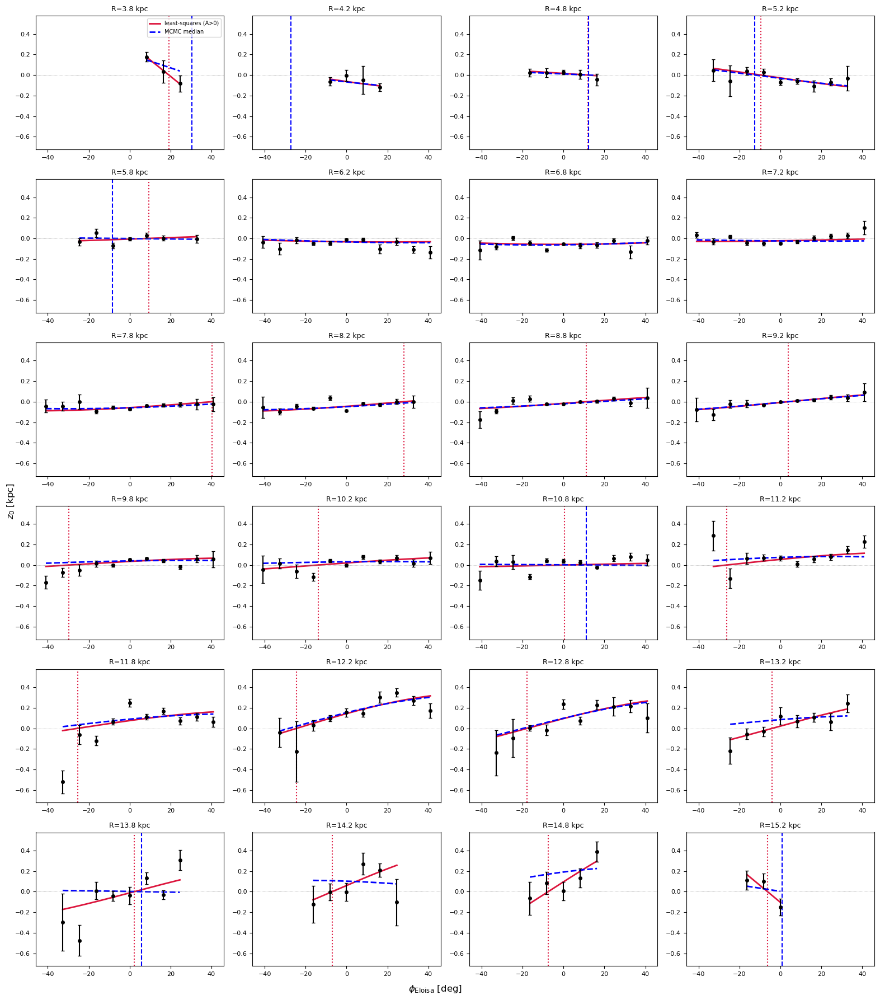

In [106]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.stats import circmean

def to_eloisa_frame(phi_deg_emma):
    return np.mod(360.0 - phi_deg_emma, 360) - 180

def sinusoid(phi, A, phi_LON):
    return A * np.sin(phi - phi_LON)

def fit_ring_normalized(phi, z0, z0_err):
    """Least-squares fit, normalized to the A>0 convention (matches the MCMC's HalfNormal prior on A)."""
    p0 = [np.ptp(z0) / 2, np.mean(phi)]
    popt, _ = curve_fit(sinusoid, phi, z0, sigma=z0_err, p0=p0,
                         absolute_sigma=True, maxfev=10000)
    A_fit, phiLON_fit = popt
    if A_fit < 0:
        A_fit = -A_fit
        phiLON_fit = phiLON_fit + np.pi
    phiLON_fit = np.mod(phiLON_fit + np.pi, 2*np.pi) - np.pi  # keep in (-pi, pi]
    return A_fit, phiLON_fit

def find_inwedge_crossing_eloisa(phi, A_fit, phiLON_fit):
    phi_fine = np.linspace(phi.min(), phi.max(), 500)
    mu_fine = sinusoid(phi_fine, A_fit, phiLON_fit)
    sign_changes = np.where(np.diff(np.sign(mu_fine)) != 0)[0]
    crossings_eloisa = []
    for idx in sign_changes:
        phi_a, phi_b = phi_fine[idx], phi_fine[idx + 1]
        mu_a, mu_b = mu_fine[idx], mu_fine[idx + 1]
        phi_cross = phi_a + (0 - mu_a) * (phi_b - phi_a) / (mu_b - mu_a)
        crossings_eloisa.append(to_eloisa_frame(np.degrees(phi_cross)))
    return crossings_eloisa

valid_rings = sorted(ring_warp.keys())
n_rings = len(valid_rings)
ncols = 4
nrows = int(np.ceil(n_rings / ncols))
print("n_rings:", n_rings, "nrows:", nrows, "ncols:", ncols)

# --- shared axis limits in Eloisa's frame ---
all_phi_deg_eloisa, all_z0, all_z0_err = [], [], []
for i_R in valid_rings:
    cell = ring_warp[i_R]
    all_phi_deg_eloisa.append(to_eloisa_frame(np.degrees(cell["phi"])))
    all_z0.append(cell["z0"])
    all_z0_err.append(cell["z0_err"])
all_phi_deg_eloisa = np.concatenate(all_phi_deg_eloisa)
all_z0 = np.concatenate(all_z0)
all_z0_err = np.concatenate(all_z0_err)

xpad = 5
ypad = 0.1 * (all_z0.max() - all_z0.min())
xlim_eloisa = (all_phi_deg_eloisa.min() - xpad, all_phi_deg_eloisa.max() + xpad)
ylim = ((all_z0 - all_z0_err).min() - ypad, (all_z0 + all_z0_err).max() + ypad)

# --- plot ---
fig, axes = plt.subplots(nrows, ncols, figsize=(4*ncols, 3*nrows), sharex=False, sharey=False)

for k, i_R in enumerate(valid_rings):
    ax = axes.flat[k]
    cell = ring_warp[i_R]

    phi = cell["phi"]
    phi_deg_eloisa = to_eloisa_frame(np.degrees(phi))
    z0 = cell["z0"]
    z0_err = cell["z0_err"]

    ax.errorbar(phi_deg_eloisa, z0, yerr=z0_err, fmt='o', color='black', ms=4, capsize=2, zorder=5)

    phi_fine = np.linspace(phi.min(), phi.max(), 300)
    phi_fine_eloisa = to_eloisa_frame(np.degrees(phi_fine))
    order = np.argsort(phi_fine_eloisa)

    try:
        A_fit, phiLON_fit = fit_ring_normalized(phi, z0, z0_err)
        mu_ls = sinusoid(phi_fine, A_fit, phiLON_fit)
        ax.plot(phi_fine_eloisa[order], mu_ls[order], color='crimson', lw=2,
                label='least-squares (A>0)' if k == 0 else None)

        for x_cross in find_inwedge_crossing_eloisa(phi, A_fit, phiLON_fit):
            ax.axvline(x_cross, color='crimson', ls=':', lw=1.5)
    except RuntimeError:
        pass

    A_med = np.median(cell["samples"]["A"])
    phiLON_med_ring = circmean(cell["samples"]["phi_LON"], high=np.pi, low=-np.pi)
    mu_mcmc = A_med * np.sin(phi_fine - phiLON_med_ring)
    ax.plot(phi_fine_eloisa[order], mu_mcmc[order], color='blue', lw=2, ls='--',
            label='MCMC median' if k == 0 else None)
    ax.axvline(to_eloisa_frame(np.degrees(phiLON_med_ring)), color='blue', ls='--', lw=1.5)

    ax.axhline(0, color='gray', lw=0.5, ls=':')
    ax.set_xlim(xlim_eloisa)
    ax.set_ylim(ylim)

    R_c = 0.5 * (cell["Rlo"] + cell["Rhi"])
    ax.set_title(f"R={R_c:.1f} kpc", fontsize=9)
    ax.tick_params(labelsize=8)

for ax in axes.flat[n_rings:]:
    ax.axis('off')

axes.flat[0].legend(fontsize=7, loc='upper right')
fig.supxlabel(r"$\phi_{\rm Eloisa}$ [deg]")
fig.supylabel(r"$z_0$ [kpc]")
plt.tight_layout()
plt.show()

In [17]:
import numpyro.distributions as dist
from numpyro import infer

phi_centers_seg = 0.5 * (theta_edges[:-1] + theta_edges[1:])  # same order as SEG_PLOT_heat
MIN_SEG_FOR_RING = 3  
def warp_ring_model_informed(phi, z0, z0_err, phi_ref=np.pi):
    A = numpyro.sample("A", dist.HalfNormal(0.3))
    delta_phi = numpyro.sample("delta_phi", dist.Normal(0.0, np.radians(45)))  # weakly informative
    phi_LON = numpyro.deterministic("phi_LON", phi_ref + delta_phi)
    mu = A * jnp.sin(phi - phi_LON)
    numpyro.sample("obs", dist.Normal(mu, z0_err), obs=z0)

def fit_warp_ring_informed(phi, z0, z0_err, key, phi_ref=np.pi,
                             num_warmup=1000, num_samples=1000, num_chains=2, progress_bar=False):
    sampler = infer.MCMC(
        infer.NUTS(warp_ring_model_informed, dense_mass=True, target_accept_prob=0.9),
        num_warmup=num_warmup, num_samples=num_samples,
        num_chains=num_chains, progress_bar=progress_bar,
    )
    sampler.run(key, phi=jnp.asarray(phi), z0=jnp.asarray(z0), z0_err=jnp.asarray(z0_err), phi_ref=phi_ref)
    return sampler

n_R = len(R_edges) - 1
ring_warp = {}
key = jr.PRNGKey(0)

for i_R in range(n_R):
    mask = ok_grid[i_R, :]
    n_valid = int(mask.sum())
    if n_valid < MIN_SEG_FOR_RING:
        continue

    phi_ring = phi_centers_seg[mask]
    z0_ring  = z0_med[i_R, mask]
    err_ring = z0_std[i_R, mask]
    err_ring = np.where(np.isfinite(err_ring) & (err_ring > 0), err_ring, np.nanmedian(err_ring))

    try:
        key, sub = jr.split(key)
        sampler = fit_warp_ring_informed(phi_ring, z0_ring, err_ring, sub, progress_bar=False)
        samples = sampler.get_samples()
        ring_warp[i_R] = {
            "Rlo": R_edges[i_R], "Rhi": R_edges[i_R+1], "n_seg": n_valid,
            "phi": phi_ring, "z0": z0_ring, "z0_err": err_ring,
            "samples": {k: np.asarray(v) for k, v in samples.items()},
        }
    except Exception as e:
        print(f"ring R=[{R_edges[i_R]:.1f},{R_edges[i_R+1]:.1f}]: fit failed -> {e}")

print(f"fit {len(ring_warp)}/{n_R} rings")

/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_64467/2643796579.py:15: UserWarning: There are not enough devices to run parallel chains: expected 2 but got 1. Chains will be drawn sequentially. If you are running MCMC in CPU, consider using `numpyro.set_host_device_count(2)` at the beginning of your program. You can double-check how many devices are available in your system using `jax.local_device_count()`.
  sampler = infer.MCMC(


fit 24/30 rings


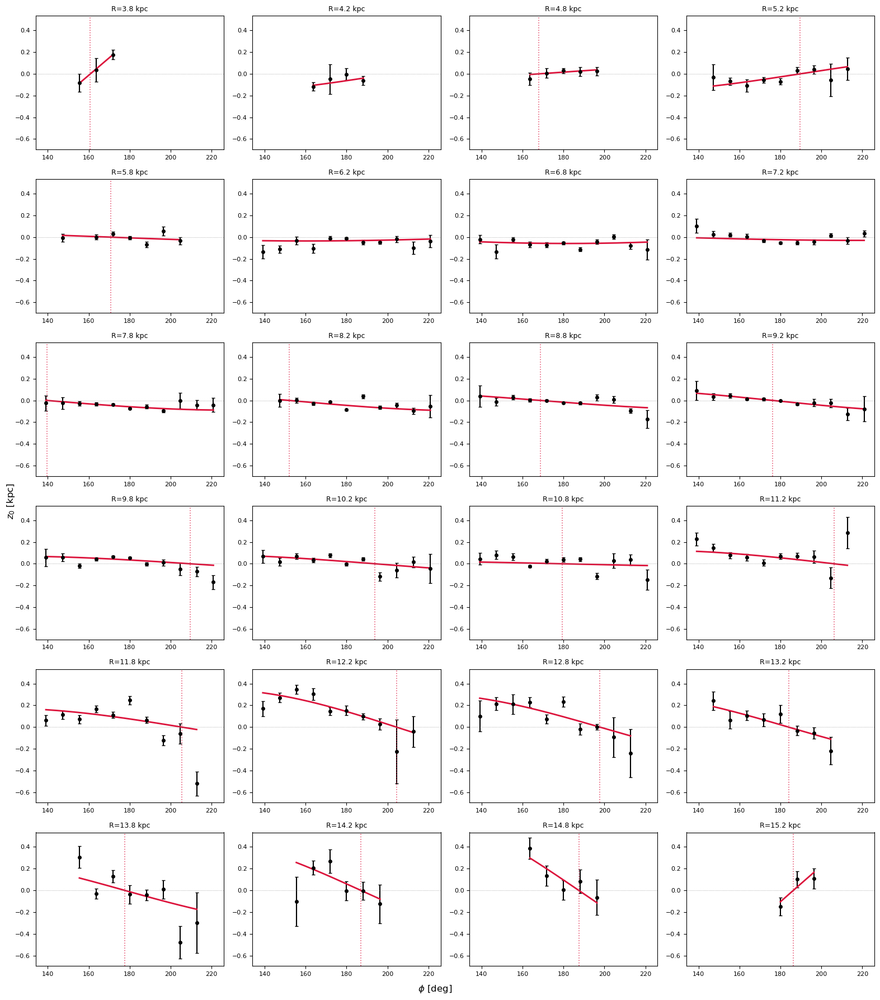

In [18]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# --- model ---
def sinusoid(phi, A, phi_LON):
    return A * np.sin(phi - phi_LON)

# --- assumes ring_warp already exists, built with 1 kpc radial bins ---

valid_rings = [i_R for i_R, cell in ring_warp.items() if len(cell["phi"]) >= 3]
n_rings = len(valid_rings)

ncols = 4
nrows = int(np.ceil(n_rings / ncols))

# shared x/y limits computed across all rings so panels are comparable
all_phi_deg = np.concatenate([np.degrees(ring_warp[i_R]["phi"]) for i_R in valid_rings])
all_z0 = np.concatenate([ring_warp[i_R]["z0"] for i_R in valid_rings])
all_z0_err = np.concatenate([ring_warp[i_R]["z0_err"] for i_R in valid_rings])

xlim = (all_phi_deg.min() - 5, all_phi_deg.max() + 5)
ylim = ((all_z0 - all_z0_err).min() * 1.1, (all_z0 + all_z0_err).max() * 1.1)

# --- plot ---
fig, axes = plt.subplots(nrows, ncols, figsize=(4*ncols, 3*nrows), sharex=False, sharey=False)

for k, i_R in enumerate(valid_rings):
    ax = axes.flat[k]
    cell = ring_warp[i_R]

    phi = cell["phi"]
    phi_deg = np.degrees(phi)
    z0 = cell["z0"]
    z0_err = cell["z0_err"]

    ax.errorbar(phi_deg, z0, yerr=z0_err, fmt='o', color='black', ms=4, capsize=2)

    try:
        p0 = [np.ptp(z0) / 2, np.mean(phi)]
        popt, _ = curve_fit(sinusoid, phi, z0, sigma=z0_err, p0=p0,
                             absolute_sigma=True, maxfev=10000)
        A_fit, phiLON_fit = popt

        phi_fine = np.linspace(phi.min(), phi.max(), 500)
        mu_fine = sinusoid(phi_fine, A_fit, phiLON_fit)
        ax.plot(np.degrees(phi_fine), mu_fine, color='crimson', lw=2)

        # find zero crossings of the fit line within the observed range
        sign_changes = np.where(np.diff(np.sign(mu_fine)) != 0)[0]
        for idx in sign_changes:
            phi_a, phi_b = phi_fine[idx], phi_fine[idx + 1]
            mu_a, mu_b = mu_fine[idx], mu_fine[idx + 1]
            phi_cross = phi_a + (0 - mu_a) * (phi_b - phi_a) / (mu_b - mu_a)
            ax.axvline(np.degrees(phi_cross), color='crimson', ls=':', lw=1.2, alpha=0.7)

    except RuntimeError:
        ax.text(0.5, 0.5, "fit failed", transform=ax.transAxes,
                ha='center', va='center', fontsize=8, color='gray')

    ax.axhline(0, color='gray', lw=0.5, ls=':')
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

    R_c = 0.5 * (cell["Rlo"] + cell["Rhi"])
    ax.set_title(f"R={R_c:.1f} kpc", fontsize=9)
    ax.tick_params(labelsize=8)

for ax in axes.flat[n_rings:]:
    ax.axis('off')

fig.supxlabel(r"$\phi$ [deg]")
fig.supylabel(r"$z_0$ [kpc]")
plt.tight_layout()
plt.show()

In [19]:
import jax
import jax.numpy as jnp
import numpyro
import numpyro.distributions as dist
from numpyro.infer import MCMC, NUTS

POGGIO_YOUNG_GIANT = {
    "R_w": 5.5, "h_w0": 0.012, "alpha_w": 1.9,
    "phi_LON0": 0.1, "R_t": 12.1, "beta_w": 9.9,
}

def warp_model(R, phi_deg, z0_obs=None, z0_err=None):
    """Full 6-parameter model."""
    R_w = numpyro.sample("R_w", dist.Uniform(2.0, 9.0))
    h_w0 = numpyro.sample("h_w0", dist.HalfNormal(0.05))
    alpha_w = numpyro.sample("alpha_w", dist.Uniform(0.5, 3.0))
    phi_LON0 = numpyro.sample("phi_LON0", dist.Normal(0.0, 10.0))
    R_t = numpyro.sample("R_t", dist.Uniform(9.0, 15.0))
    beta_w = numpyro.sample("beta_w", dist.Normal(0.0, 15.0))

    dR = jnp.clip(R - R_w, a_min=0.0)
    h_w = jnp.where(R > R_w, h_w0 * jnp.power(dR, alpha_w), 0.0)
    phi_LON = jnp.where(R <= R_t, phi_LON0, phi_LON0 + beta_w * (R - R_t))
    z_pred = h_w * jnp.sin(jnp.deg2rad(phi_deg) - jnp.deg2rad(phi_LON))

    numpyro.deterministic("z_pred", z_pred)
    numpyro.sample("obs", dist.Normal(z_pred, z0_err), obs=z0_obs)


def warp_model_straight_LON(R, phi_deg, z0_obs=None, z0_err=None):
    """No twist term -- cross-check model."""
    R_w = POGGIO_YOUNG_GIANT["R_w"]
    h_w0 = numpyro.sample("h_w0", dist.HalfNormal(0.05))
    alpha_w = numpyro.sample("alpha_w", dist.Uniform(0.5, 4.0))
    phi_LON0 = numpyro.sample("phi_LON0", dist.Normal(0.0, 10.0))

    dR = jnp.clip(R - R_w, a_min=0.0)
    h_w = jnp.where(R > R_w, h_w0 * jnp.power(dR, alpha_w), 0.0)
    z_pred = h_w * jnp.sin(jnp.deg2rad(phi_deg) - jnp.deg2rad(phi_LON0))

    numpyro.deterministic("z_pred", z_pred)
    numpyro.sample("obs", dist.Normal(z_pred, z0_err), obs=z0_obs)

In [20]:
def run_warp_fit(model_fn, R, phi_deg, z0, z0_err, seed=0,
                  num_warmup=1500, num_samples=2000, num_chains=4):
    rng_key = jax.random.PRNGKey(seed)
    kernel = NUTS(model_fn, target_accept_prob=0.95, max_tree_depth=12)
    mcmc = MCMC(kernel, num_warmup=num_warmup, num_samples=num_samples, num_chains=num_chains)
    mcmc.run(rng_key, R=jnp.asarray(R), phi_deg=jnp.asarray(phi_deg),
              z0_obs=jnp.asarray(z0), z0_err=jnp.asarray(z0_err))
    mcmc.print_summary()
    return mcmc

def divergence_report(label, mcmc_obj, n_points):
    n_div = int(mcmc_obj.get_extra_fields()["diverging"].sum())
    n_total = len(mcmc_obj.get_extra_fields()["diverging"])
    pct = 100 * n_div / n_total
    print(f"{label}: {n_points} data points, {n_div}/{n_total} divergences ({pct:.1f}%)")

In [21]:
R_centers = 0.5 * (R_edges[:-1] + R_edges[1:])

theta_edges = np.unwrap(np.array(crowd_bounds, float))
for i in range(1, len(theta_edges)):
    while theta_edges[i] <= theta_edges[i - 1]:
        theta_edges[i] += 2 * np.pi

phi_centers_deg_emma = np.degrees(0.5 * (theta_edges[:-1] + theta_edges[1:]))

# convert to Poggio's convention (phi=0 toward anti-centre, increasing with rotation)
phi_centers_deg = 180.0 - phi_centers_deg_emma
phi_centers_deg = (phi_centers_deg + 180) % 360 - 180

R_grid, Phi_grid = np.meshgrid(R_centers, phi_centers_deg, indexing="ij")

def extract_fit_arrays(z0_med_bin, z0_std_bin, ok_grid_bin=None, R_min=8.277, R_max=14.5):
    mask = (np.isfinite(z0_med_bin) & np.isfinite(z0_std_bin) & (z0_std_bin > 0)
            & (R_grid >= R_min) & (R_grid <= R_max))
    if ok_grid_bin is not None:
        mask &= ok_grid_bin
    return R_grid[mask], Phi_grid[mask], z0_med_bin[mask], z0_std_bin[mask]

# using your Step 8 z_sun=0 grid directly -- no "_u" suffix needed since there's no age split
R_u, phi_u, z0_u, z0err_u = extract_fit_arrays(z0_med, z0_std, ok_grid)
print(f"unified (z_sun=0): {len(z0_u)} cells going into the fit")

unified (z_sun=0): 117 cells going into the fit


In [22]:
mcmc_unified = run_warp_fit(warp_model, R_u, phi_u, z0_u, z0err_u)
samples_unified = mcmc_unified.get_samples()
divergence_report("unified (z_sun=0)", mcmc_unified, len(z0_u))

/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_64467/1170746708.py:5: UserWarning: There are not enough devices to run parallel chains: expected 4 but got 1. Chains will be drawn sequentially. If you are running MCMC in CPU, consider using `numpyro.set_host_device_count(4)` at the beginning of your program. You can double-check how many devices are available in your system using `jax.local_device_count()`.
  mcmc = MCMC(kernel, num_warmup=num_warmup, num_samples=num_samples, num_chains=num_chains)
sample: 100%|█| 3500/3500 [00:06<00:00, 548.56it/s, 127 steps of size 3.11e-02. 
sample: 100%|█| 3500/3500 [00:04<00:00, 757.11it/s, 127 steps of size 4.68e-02. 
sample: 100%|█| 3500/3500 [00:04<00:00, 818.68it/s, 63 steps of size 5.11e-02. a
sample: 100%|█| 3500/3500 [00:04<00:00, 711.88it/s, 63 steps of size 4.37e-02. a


                mean       std    median      5.0%     95.0%     n_eff     r_hat
       R_t     12.36      0.20     12.35     12.07     12.71   3915.86      1.00
       R_w      8.24      0.44      8.31      7.57      8.90   2818.26      1.00
   alpha_w      2.01      0.34      1.98      1.45      2.56   2796.13      1.00
    beta_w     12.80      2.51     12.76      8.80     16.96   3763.79      1.00
      h_w0      0.02      0.01      0.02      0.00      0.03   2951.62      1.00
  phi_LON0    -20.48      2.89    -20.33    -24.96    -15.62   3268.71      1.00

Number of divergences: 1
unified (z_sun=0): 117 data points, 1/8000 divergences (0.0%)


In [32]:
import numpy as np
import matplotlib.pyplot as plt
import emcee
import corner
import pickle

def to_eloisa_frame(phi_deg_emma):
    return np.mod(360.0 - phi_deg_emma, 360) - 180

# --- Eloisa's likelihood/prior, unchanged (dropped the unused R argument) ---
def lnlike(theta, z, zerr, phi):
    hw, phiw = theta
    z_model = hw * np.sin(phi - np.radians(phiw))
    sigma2 = zerr**2
    varb = (z - z_model)**2 / sigma2
    return -0.5 * np.sum(varb + np.log(sigma2))

def lnprior(theta):
    hw, phiw = theta
    if 0.0001 < hw < 0.9 and -180. < phiw < 180.:
        return 0.0
    return -np.inf

def lnprob(theta, z, zerr, phi):
    lp = lnprior(theta)
    if not np.isfinite(lp):
        return -np.inf
    return lp + lnlike(theta, z, zerr, phi)

# --- run per ring ---
ndim = 2
nwalkers = 100
nsteps = 2000     
burnin = 1000

emcee_results = {}

for i_R in valid_rings:
    cell = ring_warp[i_R]

    phi_emma_deg = np.degrees(cell["phi"])
    phi_eloisa_rad = np.radians(to_eloisa_frame(phi_emma_deg))   # her frame, radians

    z = cell["z0"]
    zerr = cell["z0_err"]
    R_c = 0.5 * (cell["Rlo"] + cell["Rhi"])

    p0_guess = np.array([max(np.ptp(z) / 2, 0.01), 0.0])
    pos = [p0_guess + 1e-4 * np.random.randn(ndim) for _ in range(nwalkers)]

    sampler = emcee.EnsembleSampler(nwalkers, ndim, lnprob, args=(z, zerr, phi_eloisa_rad))
    sampler.run_mcmc(pos, nsteps, progress=False)

    samples = sampler.chain[:, burnin:, :].reshape((-1, ndim))

    hw_mcmc, phiw_mcmc = map(
        lambda v: (v[1], v[2] - v[1], v[1] - v[0]),
        zip(*np.percentile(samples, [16, 50, 84], axis=0))
    )

    emcee_results[i_R] = dict(
        R_c=R_c, samples=samples,
        hw_med=hw_mcmc[0], hw_hi=hw_mcmc[1], hw_lo=hw_mcmc[2],
        phiw_med=phiw_mcmc[0], phiw_hi=phiw_mcmc[1], phiw_lo=phiw_mcmc[2],
    )


    print(f"R={R_c:.1f} kpc: hw = {hw_mcmc[0]:.3f} (+{hw_mcmc[1]:.3f}/-{hw_mcmc[2]:.3f}) kpc, "
          f"phiw = {phiw_mcmc[0]:+.1f} (+{phiw_mcmc[1]:.1f}/-{phiw_mcmc[2]:.1f}) deg [Sun at 0]")

with open("emcee_results_05kpc.pkl", "wb") as f:
        pickle.dump(emcee_results, f)

R=3.8 kpc: hw = 0.607 (+0.201/-0.303) kpc, phiw = -156.9 (+11.0/-4.3) deg [Sun at 0]
R=4.2 kpc: hw = 0.125 (+0.108/-0.054) kpc, phiw = +146.5 (+20.9/-53.0) deg [Sun at 0]
R=4.8 kpc: hw = 0.038 (+0.058/-0.026) kpc, phiw = -108.1 (+117.3/-60.8) deg [Sun at 0]
R=5.2 kpc: hw = 0.143 (+0.059/-0.060) kpc, phiw = +168.4 (+6.0/-12.3) deg [Sun at 0]
R=5.8 kpc: hw = 0.017 (+0.030/-0.012) kpc, phiw = +13.3 (+95.2/-54.8) deg [Sun at 0]
R=6.2 kpc: hw = 0.037 (+0.011/-0.009) kpc, phiw = +103.2 (+30.5/-37.9) deg [Sun at 0]
R=6.8 kpc: hw = 0.061 (+0.009/-0.008) kpc, phiw = +87.3 (+20.6/-19.9) deg [Sun at 0]
R=7.2 kpc: hw = 0.029 (+0.011/-0.008) kpc, phiw = +57.8 (+37.7/-23.9) deg [Sun at 0]
R=7.8 kpc: hw = 0.085 (+0.021/-0.018) kpc, phiw = +42.6 (+13.3/-8.8) deg [Sun at 0]
R=8.2 kpc: hw = 0.092 (+0.020/-0.018) kpc, phiw = +29.2 (+7.8/-5.4) deg [Sun at 0]
R=8.8 kpc: hw = 0.081 (+0.020/-0.020) kpc, phiw = +11.5 (+4.0/-2.9) deg [Sun at 0]
R=9.2 kpc: hw = 0.104 (+0.024/-0.023) kpc, phiw = +3.9 (+2.6/-2.4)

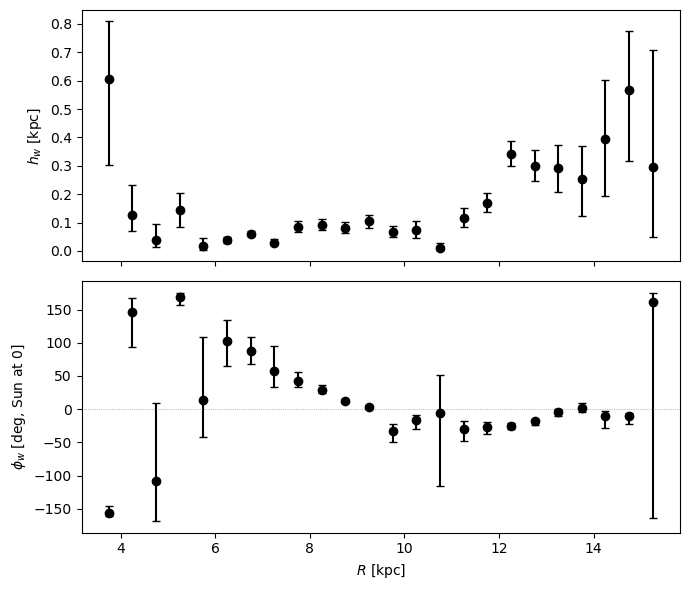

In [33]:
R_list = [emcee_results[i]["R_c"] for i in valid_rings]
hw_list = [emcee_results[i]["hw_med"] for i in valid_rings]
hw_err = [[emcee_results[i]["hw_lo"] for i in valid_rings],
          [emcee_results[i]["hw_hi"] for i in valid_rings]]
phiw_list = [emcee_results[i]["phiw_med"] for i in valid_rings]
phiw_err = [[emcee_results[i]["phiw_lo"] for i in valid_rings],
            [emcee_results[i]["phiw_hi"] for i in valid_rings]]

fig, axes = plt.subplots(2, 1, figsize=(7, 6), sharex=True)
axes[0].errorbar(R_list, hw_list, yerr=hw_err, fmt='o', color='black', capsize=3)
axes[0].set_ylabel(r"$h_w$ [kpc]")

axes[1].errorbar(R_list, phiw_list, yerr=phiw_err, fmt='o', color='black', capsize=3)
axes[1].axhline(0, color='gray', lw=0.5, ls=':')
axes[1].set_ylabel(r"$\phi_w$ [deg, Sun at 0]")
axes[1].set_xlabel(r"$R$ [kpc]")

plt.tight_layout()
plt.show()

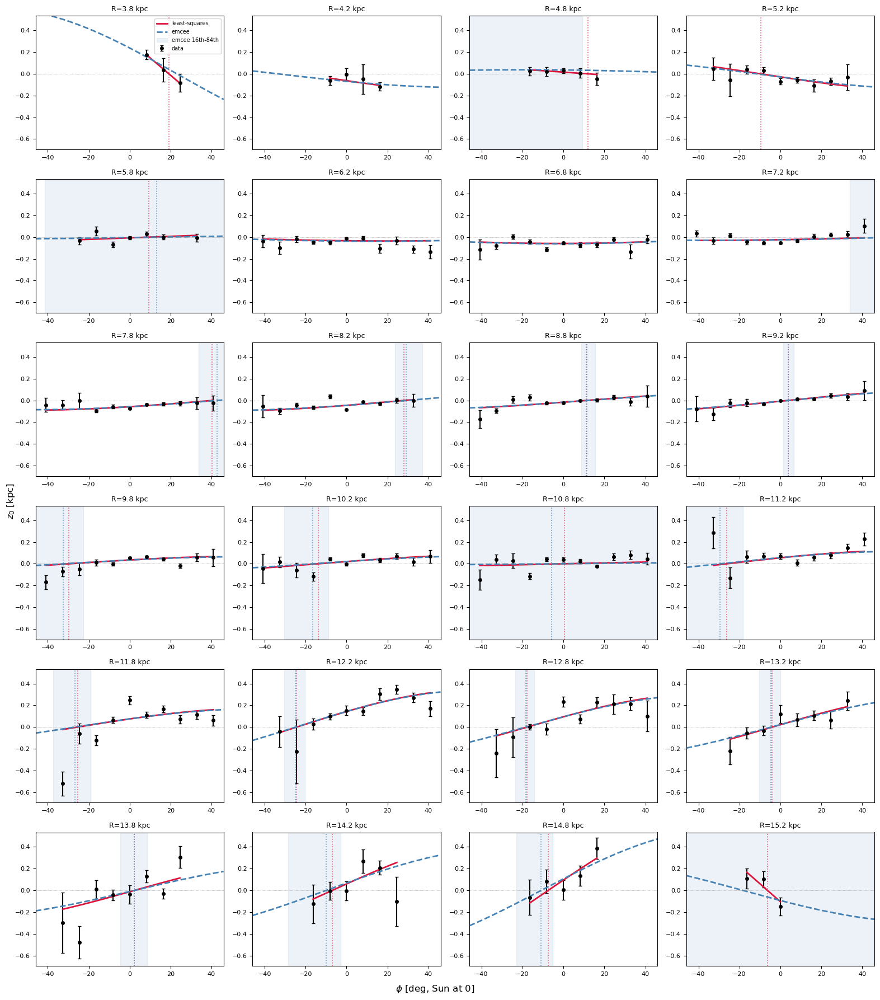

In [44]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# --- model ---
def sinusoid(phi, A, phi_LON):
    return A * np.sin(phi - phi_LON)

def to_eloisa_frame(phi_deg_emma):
    return np.mod(360.0 - phi_deg_emma, 360) - 180

# --- assumes ring_warp already exists, built with 1 kpc radial bins,
#     and emcee_results already exists from the emcee per-ring fit ---

valid_rings = [i_R for i_R, cell in ring_warp.items() if len(cell["phi"]) >= 3]
n_rings = len(valid_rings)

ncols = 4
nrows = int(np.ceil(n_rings / ncols))

# shared x/y limits computed across all rings, in Eloisa's frame
all_phi_deg_eloisa = np.concatenate(
    [to_eloisa_frame(np.degrees(ring_warp[i_R]["phi"])) for i_R in valid_rings]
)
all_z0 = np.concatenate([ring_warp[i_R]["z0"] for i_R in valid_rings])
all_z0_err = np.concatenate([ring_warp[i_R]["z0_err"] for i_R in valid_rings])

xlim = (all_phi_deg_eloisa.min() - 5, all_phi_deg_eloisa.max() + 5)
ylim = ((all_z0 - all_z0_err).min() * 1.1, (all_z0 + all_z0_err).max() * 1.1)

# --- plot ---
fig, axes = plt.subplots(nrows, ncols, figsize=(4*ncols, 3*nrows), sharex=False, sharey=False)

for k, i_R in enumerate(valid_rings):
    ax = axes.flat[k]
    cell = ring_warp[i_R]

    phi = cell["phi"]                                   
    phi_deg_eloisa = to_eloisa_frame(np.degrees(phi))    
    z0 = cell["z0"]
    z0_err = cell["z0_err"]

    ax.errorbar(phi_deg_eloisa, z0, yerr=z0_err, fmt='o', color='black', ms=4, capsize=2,
                label='data' if k == 0 else None)

    try:
        p0 = [np.ptp(z0) / 2, np.mean(phi)]
        popt, _ = curve_fit(sinusoid, phi, z0, sigma=z0_err, p0=p0,
                             absolute_sigma=True, maxfev=10000)
        A_fit, phiLON_fit = popt

        phi_fine = np.linspace(phi.min(), phi.max(), 500)
        mu_fine = sinusoid(phi_fine, A_fit, phiLON_fit)
        phi_fine_deg_eloisa = to_eloisa_frame(np.degrees(phi_fine))

        ax.plot(phi_fine_deg_eloisa, mu_fine, color='crimson', lw=2,
                label='least-squares' if k == 0 else None)

        # zero crossings of the least-squares fit, in the observed window
        sign_changes = np.where(np.diff(np.sign(mu_fine)) != 0)[0]
        for idx in sign_changes:
            phi_a, phi_b = phi_fine[idx], phi_fine[idx + 1]
            mu_a, mu_b = mu_fine[idx], mu_fine[idx + 1]
            phi_cross = phi_a + (0 - mu_a) * (phi_b - phi_a) / (mu_b - mu_a)
            ax.axvline(to_eloisa_frame(np.degrees(phi_cross)),
                       color='crimson', ls=':', lw=1.2, alpha=0.7)

    except RuntimeError:
        ax.text(0.5, 0.5, "fit failed", transform=ax.transAxes,
                ha='center', va='center', fontsize=8, color='gray')

    # --- overlay the emcee fit for this ring, already in Eloisa's frame ---
    if i_R in emcee_results:
        res = emcee_results[i_R]
        hw_med = res["hw_med"]
        phiw_med = res["phiw_med"]

        phi_fine_eloisa_deg = np.linspace(xlim[0], xlim[1], 500)
        mu_emcee_fine = hw_med * np.sin(np.radians(phi_fine_eloisa_deg) - np.radians(phiw_med))
        ax.plot(phi_fine_eloisa_deg, mu_emcee_fine, color='steelblue', lw=2, ls='--',
                label='emcee' if k == 0 else None)

        ax.axvline(phiw_med, color='steelblue', ls=':', lw=1.2, alpha=0.8)
        ax.axvspan(phiw_med - res["phiw_lo"], phiw_med + res["phiw_hi"],
                   color='steelblue', alpha=0.1,
                   label='emcee 16th-84th' if k == 0 else None)

    ax.axhline(0, color='gray', lw=0.5, ls=':')
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

    R_c = 0.5 * (cell["Rlo"] + cell["Rhi"])
    ax.set_title(f"R={R_c:.1f} kpc", fontsize=9)
    ax.tick_params(labelsize=8)

for ax in axes.flat[n_rings:]:
    ax.axis('off')

axes.flat[0].legend(fontsize=7, loc='upper right')
fig.supxlabel(r"$\phi$ [deg, Sun at 0]")
fig.supylabel(r"$z_0$ [kpc]")
plt.tight_layout()
plt.show()

In [45]:
import pickle

with open("emcee_results_1kpc.pkl", "rb") as f:
    emcee_results_1kpc = pickle.load(f)

with open("emcee_results_05kpc.pkl", "rb") as f:
    emcee_results_05kpc = pickle.load(f)

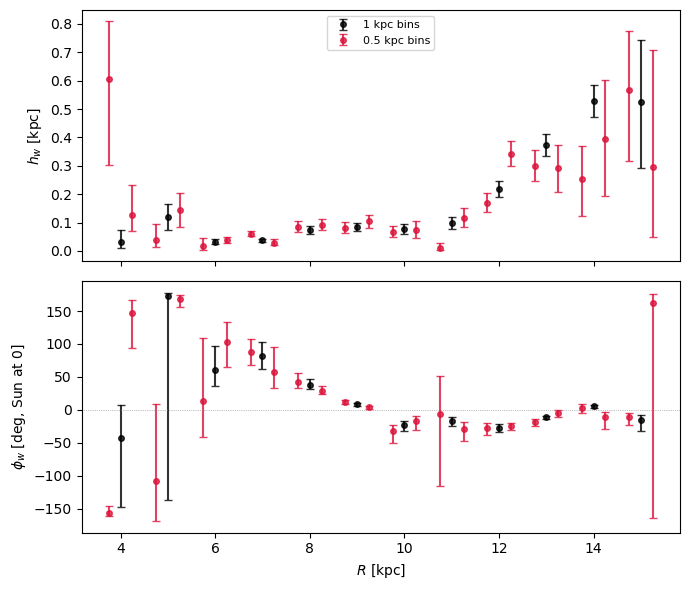

In [36]:
import numpy as np
import matplotlib.pyplot as plt

def plot_set(ax_hw, ax_phiw, results, color, label):
    valid = sorted(results.keys())
    R_list = [results[i]["R_c"] for i in valid]
    hw_list = [results[i]["hw_med"] for i in valid]
    hw_err = [[results[i]["hw_lo"] for i in valid],
              [results[i]["hw_hi"] for i in valid]]
    phiw_list = [results[i]["phiw_med"] for i in valid]
    phiw_err = [[results[i]["phiw_lo"] for i in valid],
                [results[i]["phiw_hi"] for i in valid]]

    ax_hw.errorbar(R_list, hw_list, yerr=hw_err, fmt='o', color=color,
                    capsize=3, ms=4, alpha=0.8, label=label)
    ax_phiw.errorbar(R_list, phiw_list, yerr=phiw_err, fmt='o', color=color,
                      capsize=3, ms=4, alpha=0.8, label=label)

fig, axes = plt.subplots(2, 1, figsize=(7, 6), sharex=True)

plot_set(axes[0], axes[1], emcee_results_1kpc, 'black', '1 kpc bins')
plot_set(axes[0], axes[1], emcee_results_05kpc, 'crimson', '0.5 kpc bins')

axes[0].set_ylabel(r"$h_w$ [kpc]")
axes[0].legend(fontsize=8)

axes[1].axhline(0, color='gray', lw=0.5, ls=':')
axes[1].set_ylabel(r"$\phi_w$ [deg, Sun at 0]")
axes[1].set_xlabel(r"$R$ [kpc]")

plt.tight_layout()
plt.show()

In [37]:
import numpy as np
import matplotlib.pyplot as plt

def plot_phiw_histograms(results, title_suffix=""):
    valid = sorted(results.keys())
    n_rings = len(valid)
    ncols = 4
    nrows = int(np.ceil(n_rings / ncols))

    fig, axes = plt.subplots(nrows, ncols, figsize=(4*ncols, 3*nrows), sharex=True)

    for k, i_R in enumerate(valid):
        ax = axes.flat[k]
        res = results[i_R]
        phiw_draws = res["samples"][:, 1]   # column 1 = phiw, already Eloisa frame, degrees

        ax.hist(phiw_draws, bins=60, color='steelblue', alpha=0.7, density=True)
        ax.axvline(res["phiw_med"], color='crimson', ls='--', lw=1.5)
        ax.set_title(f"R={res['R_c']:.1f} kpc", fontsize=9)
        ax.tick_params(labelsize=8)
        ax.set_yticks([])

    for ax in axes.flat[n_rings:]:
        ax.axis('off')

    fig.supxlabel(r"$\phi_w$ [deg, Sun at 0]")
    fig.suptitle(f"emcee $\\phi_w$ posteriors {title_suffix}", y=1.02)
    plt.tight_layout()
    plt.show()

def plot_hw_histograms(results, title_suffix=""):
    valid = sorted(results.keys())
    n_rings = len(valid)
    ncols = 4
    nrows = int(np.ceil(n_rings / ncols))

    fig, axes = plt.subplots(nrows, ncols, figsize=(4*ncols, 3*nrows), sharex=True)

    for k, i_R in enumerate(valid):
        ax = axes.flat[k]
        res = results[i_R]
        hw_draws = res["samples"][:, 0]   # column 0 = hw

        ax.hist(hw_draws, bins=60, color='seagreen', alpha=0.7, density=True)
        ax.axvline(res["hw_med"], color='crimson', ls='--', lw=1.5)
        ax.set_title(f"R={res['R_c']:.1f} kpc", fontsize=9)
        ax.tick_params(labelsize=8)
        ax.set_yticks([])

    for ax in axes.flat[n_rings:]:
        ax.axis('off')

    fig.supxlabel(r"$h_w$ [kpc]")
    fig.suptitle(f"emcee $h_w$ posteriors {title_suffix}", y=1.02)
    plt.tight_layout()
    plt.show()

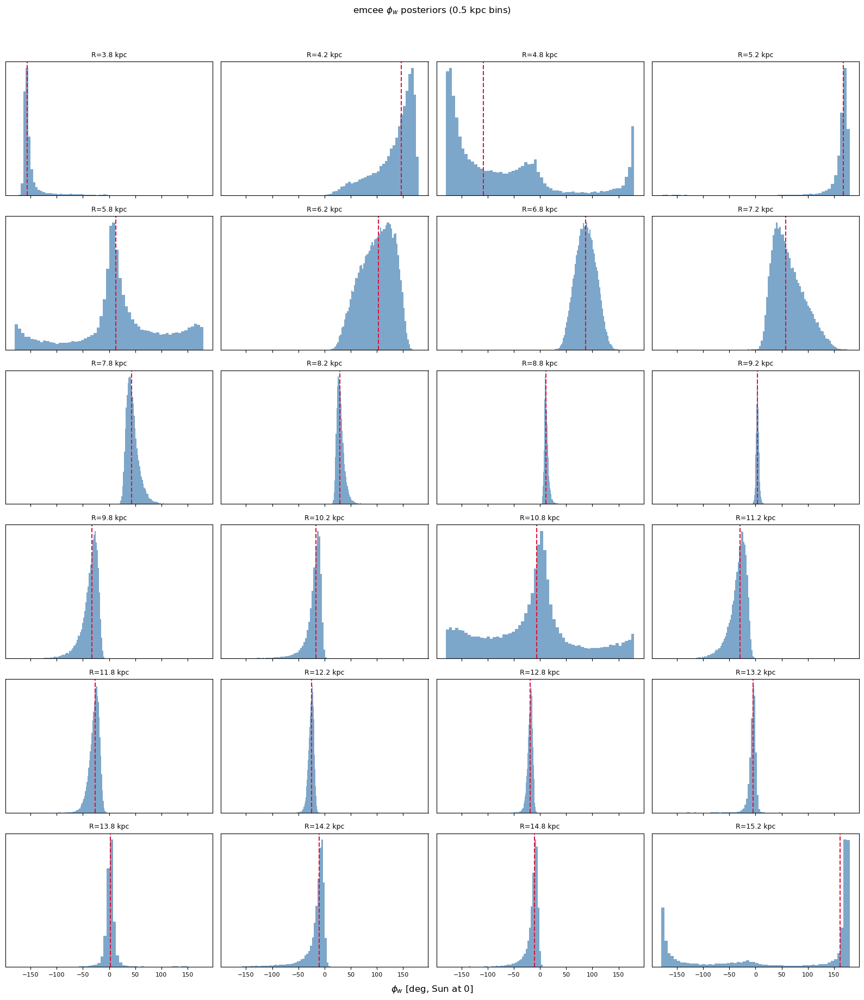

In [40]:
plot_phiw_histograms(emcee_results_05kpc, title_suffix="(0.5 kpc bins)")

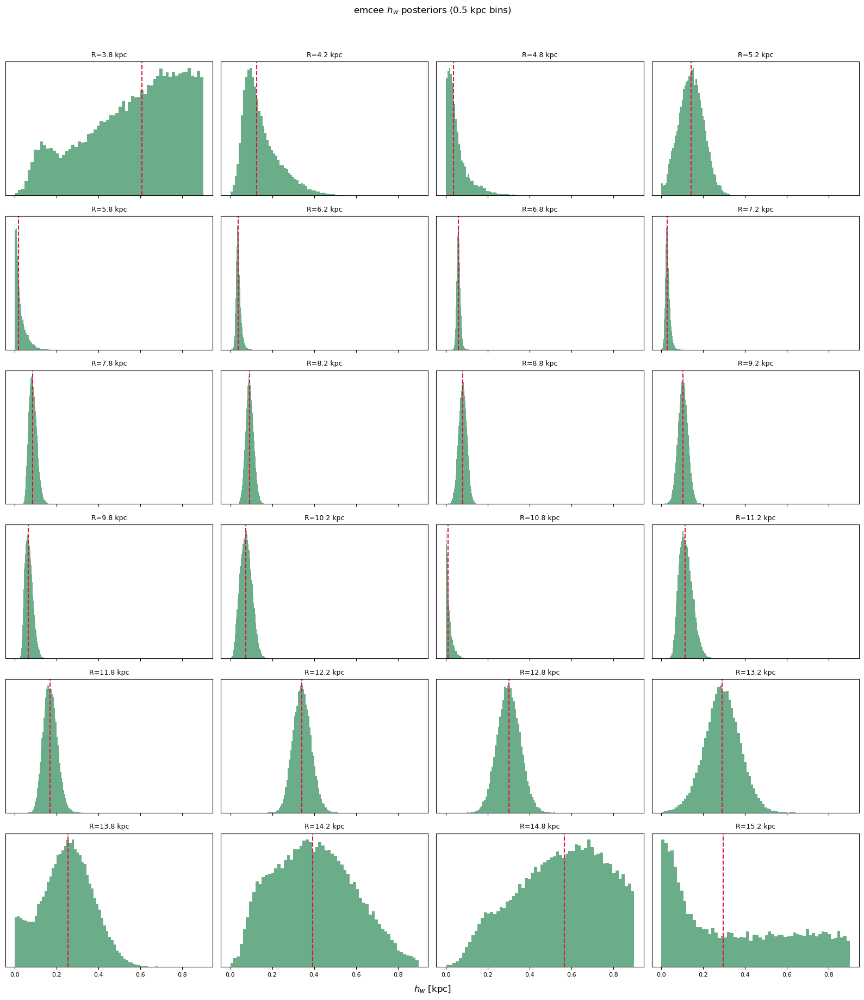

In [41]:
plot_hw_histograms(emcee_results_05kpc, title_suffix="(0.5 kpc bins)")

In [46]:
import numpy as np

R_sun = 8.275   # kpc, matches src/coords.py's galcen_distance_kpc

def to_eloisa_frame(phi_deg_emma):
    return np.mod(360.0 - phi_deg_emma, 360) - 180

R_all, phi_eloisa_rad_all, z0_all, z0_err_all = [], [], [], []

for i_R in valid_rings:
    cell = ring_warp[i_R]
    R_c = 0.5 * (cell["Rlo"] + cell["Rhi"])

    n = len(cell["phi"])
    R_all.append(np.full(n, R_c))
    phi_eloisa_rad_all.append(np.radians(to_eloisa_frame(np.degrees(cell["phi"]))))
    z0_all.append(cell["z0"])
    z0_err_all.append(cell["z0_err"])

R_all = np.concatenate(R_all)
phi_eloisa_rad_all = np.concatenate(phi_eloisa_rad_all)
z0_all = np.concatenate(z0_all)
z0_err_all = np.concatenate(z0_err_all)

print(f"Total points across {len(valid_rings)} rings: {len(R_all)}")

Total points across 24 rings: 207


In [47]:
def A_of_R(R, h_w0, R_w, alpha_w):
    ratio = np.clip((R - R_w) / (R_sun - R_w), 0.0, None)
    return h_w0 * ratio**alpha_w

100%|██████████████████████████████████████| 6000/6000 [00:12<00:00, 480.29it/s]


$h_{w0}$: 0.003
$R_w$: 8.004
$\alpha_w$: 1.600
$\phi_{LON,0}$: -12.722


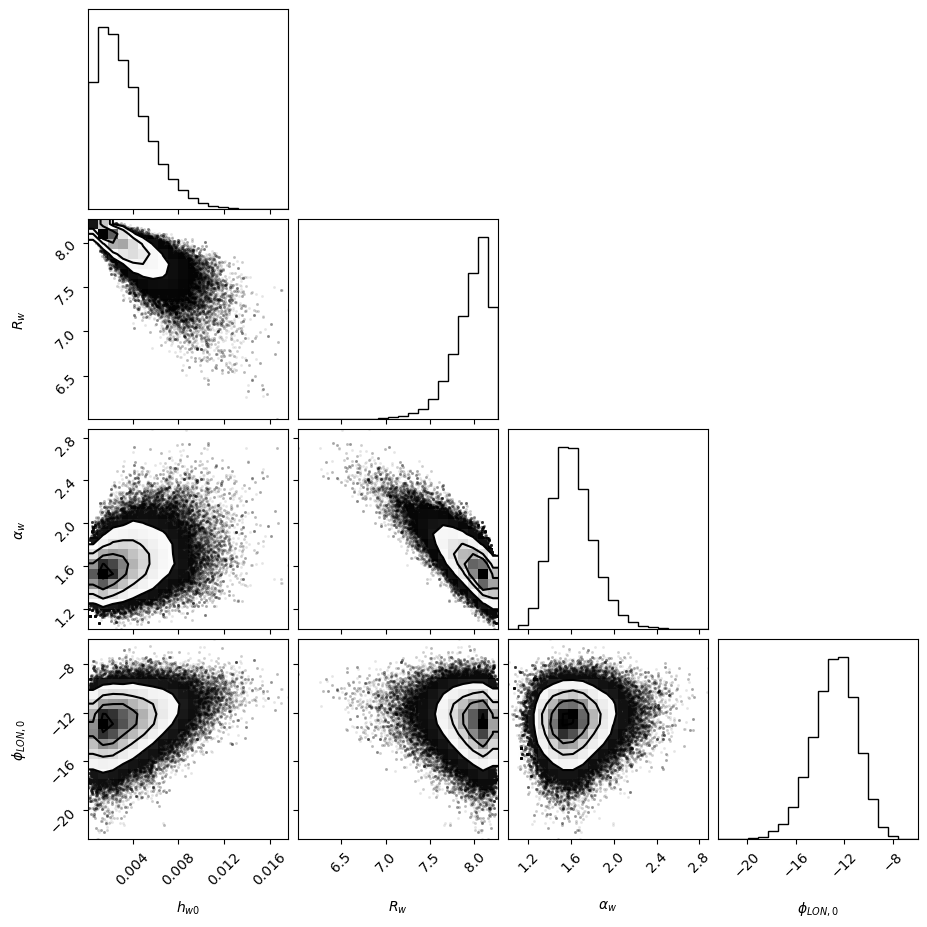

In [48]:
import emcee
import corner

def model_straight(theta, R, phi):
    h_w0, R_w, alpha_w, phiLON0 = theta
    A = A_of_R(R, h_w0, R_w, alpha_w)
    return A * np.sin(phi - np.radians(phiLON0))

def lnlike_straight(theta, R, phi, z, zerr):
    z_model = model_straight(theta, R, phi)
    sigma2 = zerr**2
    return -0.5 * np.sum((z - z_model)**2 / sigma2 + np.log(sigma2))

def lnprior_straight(theta):
    h_w0, R_w, alpha_w, phiLON0 = theta
    if (0.0001 < h_w0 < 2.0 and 3.0 < R_w < R_sun and
        0.1 < alpha_w < 5.0 and -180.0 < phiLON0 < 180.0):
        return 0.0
    return -np.inf

def lnprob_straight(theta, R, phi, z, zerr):
    lp = lnprior_straight(theta)
    if not np.isfinite(lp):
        return -np.inf
    return lp + lnlike_straight(theta, R, phi, z, zerr)

ndim_s = 4
nwalkers = 100
nsteps = 6000     # global fit needs more steps than a single ring; check convergence
burnin = 3000

p0_straight = np.array([0.3, 5.5, 1.5, -20.0])
pos_s = [p0_straight + p0_straight * 0.05 * np.random.randn(ndim_s) for _ in range(nwalkers)]

sampler_straight = emcee.EnsembleSampler(
    nwalkers, ndim_s, lnprob_straight,
    args=(R_all, phi_eloisa_rad_all, z0_all, z0_err_all)
)
sampler_straight.run_mcmc(pos_s, nsteps, progress=True)

samples_straight = sampler_straight.chain[:, burnin:, :].reshape((-1, ndim_s))

labels_s = [r"$h_{w0}$", r"$R_w$", r"$\alpha_w$", r"$\phi_{LON,0}$"]
med_s = np.median(samples_straight, axis=0)
for lbl, v in zip(labels_s, med_s):
    print(f"{lbl}: {v:.3f}")

fig = corner.corner(samples_straight, labels=labels_s)
plt.show()

100%|████████████████████████████████████| 12000/12000 [00:48<00:00, 249.50it/s]


$h_{w0}$: 0.004
$R_w$: 7.581
$\alpha_w$: 1.564
$\phi_{LON,0}$: -13.594
$R_t$: 11.806
$\beta_w$: 2.414


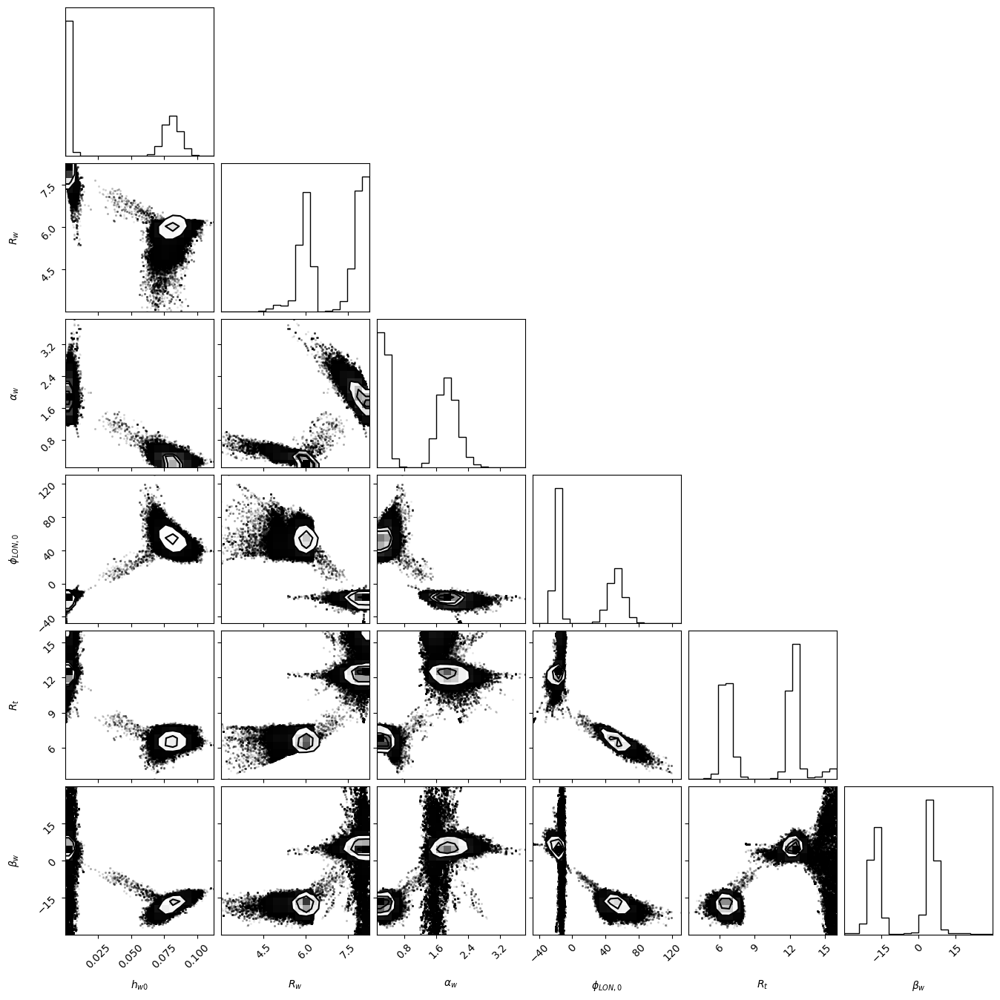

In [172]:
def phiLON_twisted(R, phiLON0, R_t, beta_w):
    return np.where(R < R_t, phiLON0, phiLON0 + beta_w * (R - R_t))

def model_twisted(theta, R, phi):
    h_w0, R_w, alpha_w, phiLON0, R_t, beta_w = theta
    A = A_of_R(R, h_w0, R_w, alpha_w)
    phiLON = phiLON_twisted(R, phiLON0, R_t, beta_w)
    return A * np.sin(phi - np.radians(phiLON))

def lnlike_twisted(theta, R, phi, z, zerr):
    z_model = model_twisted(theta, R, phi)
    sigma2 = zerr**2
    return -0.5 * np.sum((z - z_model)**2 / sigma2 + np.log(sigma2))

def lnprior_twisted(theta):
    h_w0, R_w, alpha_w, phiLON0, R_t, beta_w = theta
    if (0.0001 < h_w0 < 2.0 and 3.0 < R_w < R_sun and
        0.1 < alpha_w < 5.0 and -180.0 < phiLON0 < 180.0 and
        R_w < R_t < 16.0 and -30.0 < beta_w < 30.0):
        return 0.0
    return -np.inf

def lnprob_twisted(theta, R, phi, z, zerr):
    lp = lnprior_twisted(theta)
    if not np.isfinite(lp):
        return -np.inf
    return lp + lnlike_twisted(theta, R, phi, z, zerr)

ndim_t = 6
p0_twisted = np.array([0.3, 5.5, 1.5, -20.0, 9.0, 0.0])
pos_t = [p0_twisted + np.abs(p0_twisted) * 0.05 * np.random.randn(ndim_t) + 1e-4*np.random.randn(ndim_t)
         for _ in range(nwalkers)]

sampler_twisted = emcee.EnsembleSampler(
    nwalkers, ndim_t, lnprob_twisted,
    args=(R_all, phi_eloisa_rad_all, z0_all, z0_err_all)
)
sampler_twisted.run_mcmc(pos_t, nsteps, progress=True)

samples_twisted = sampler_twisted.chain[:, burnin:, :].reshape((-1, ndim_t))

labels_t = [r"$h_{w0}$", r"$R_w$", r"$\alpha_w$", r"$\phi_{LON,0}$", r"$R_t$", r"$\beta_w$"]
med_t = np.median(samples_twisted, axis=0)
for lbl, v in zip(labels_t, med_t):
    print(f"{lbl}: {v:.3f}")

fig = corner.corner(samples_twisted, labels=labels_t)
plt.show()

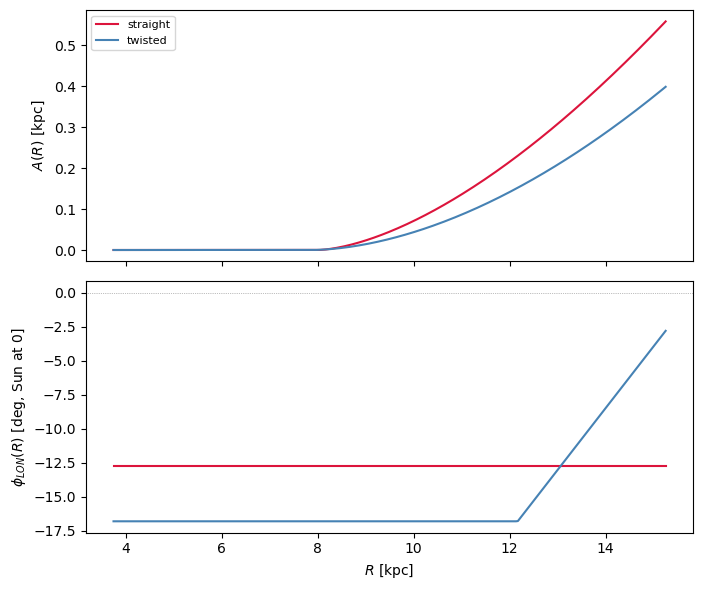

In [50]:
R_grid = np.linspace(R_all.min(), R_all.max(), 300)

h_w0_s, R_w_s, alpha_w_s, phiLON0_s = med_s
h_w0_t, R_w_t, alpha_w_t, phiLON0_t, R_t_t, beta_w_t = med_t

A_straight = A_of_R(R_grid, h_w0_s, R_w_s, alpha_w_s)
phiLON_straight_curve = np.full_like(R_grid, phiLON0_s)

A_twisted = A_of_R(R_grid, h_w0_t, R_w_t, alpha_w_t)
phiLON_twisted_curve = phiLON_twisted(R_grid, phiLON0_t, R_t_t, beta_w_t)

fig, axes = plt.subplots(2, 1, figsize=(7, 6), sharex=True)

axes[0].plot(R_grid, A_straight, color='crimson', label='straight')
axes[0].plot(R_grid, A_twisted, color='steelblue', label='twisted')
axes[0].set_ylabel(r"$A(R)$ [kpc]")
axes[0].legend(fontsize=8)

axes[1].plot(R_grid, phiLON_straight_curve, color='crimson', label='straight')
axes[1].plot(R_grid, phiLON_twisted_curve, color='steelblue', label='twisted')
axes[1].axhline(0, color='gray', lw=0.5, ls=':')
axes[1].set_ylabel(r"$\phi_{LON}(R)$ [deg, Sun at 0]")
axes[1].set_xlabel(r"$R$ [kpc]")

plt.tight_layout()
plt.show()

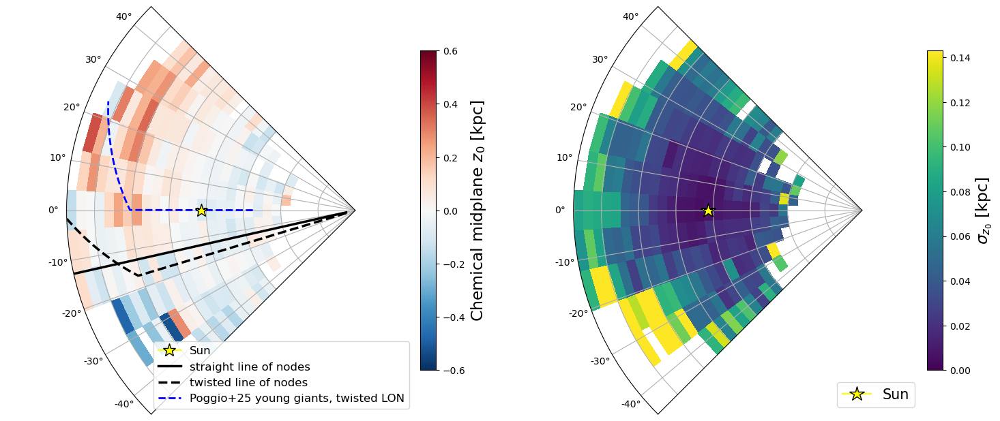

In [105]:
def to_eloisa_frame(phi_deg_emma):
    return np.mod(360.0 - phi_deg_emma, 360) - 180

# --- remap the theta mesh into Eloisa's frame ---
theta_edges_eloisa_deg = to_eloisa_frame(np.degrees(theta_edges))   # mirror + shift, per edge
theta_edges_eloisa = np.radians(theta_edges_eloisa_deg)

T_mesh_eloisa, R_mesh = np.meshgrid(theta_edges_eloisa, R_edges)

theta_sun_eloisa = 0.0   # Sun is at 0 deg by definition in Eloisa's frame
theta_min_eloisa, theta_max_eloisa = theta_edges_eloisa_deg.min(), theta_edges_eloisa_deg.max()

# --- line-of-nodes curves, already in Eloisa's frame, no conversion needed ---
R_grid = np.linspace(R_edges[0], R_edges[-1], 300)

theta_straight = np.radians(np.full_like(R_grid, phiLON0_s))
theta_twisted = np.radians(phiLON_twisted(R_grid, phiLON0_t, R_t_t, beta_w_t))

fig = plt.figure(figsize=(15, 7))

ax1 = plt.subplot(1, 2, 1, projection="polar")
pcm1 = ax1.pcolormesh(T_mesh_eloisa, R_mesh, Zmap_med, cmap="RdBu_r", vmin=-zlim, vmax=zlim, shading="flat")
fig.colorbar(pcm1, ax=ax1, pad=0.01, shrink=0.7).set_label(r"Chemical midplane $z_0$ [kpc]", fontsize=17)
ax1.set_theta_zero_location("W"); ax1.set_theta_direction(-1); ax1.set_rmax(R_edges[-1])
ax1.set_thetamin(theta_min_eloisa); ax1.set_thetamax(theta_max_eloisa)
ax1.set_yticklabels([])
ax1.plot(np.radians(theta_sun_eloisa), R_sun, marker="*", color="yellow", markersize=14,
          markeredgecolor="k", zorder=5, label="Sun")
ax1.plot(theta_straight, R_grid, color='black', lw=2.5, label='straight line of nodes')
ax1.plot(theta_twisted, R_grid, color='black', lw=2.5, ls='--', label='twisted line of nodes')
ax1.legend(loc="lower right", fontsize=12)

ax2 = plt.subplot(1, 2, 2, projection="polar")
pcm2 = ax2.pcolormesh(T_mesh_eloisa, R_mesh, Zmap_std, cmap="viridis", vmin=0.0, vmax=std_max, shading="flat")
fig.colorbar(pcm2, ax=ax2, pad=0.01, shrink=0.7).set_label(r"$\sigma_{z_0}$ [kpc]", fontsize=17)
ax2.set_theta_zero_location("W"); ax2.set_theta_direction(-1); ax2.set_rmax(R_edges[-1])
ax2.set_thetamin(theta_min_eloisa); ax2.set_thetamax(theta_max_eloisa)
ax2.set_yticklabels([])
ax2.plot(np.radians(theta_sun_eloisa), R_sun, marker="*", color="yellow", markersize=16,
          markeredgecolor="k", zorder=5, label="Sun")
ax2.legend(loc="lower right", fontsize=15)

# --- Eloisa's young giants twisted LON (Poggio+25, Table 1) ---
R_grid_yg_polar = np.linspace(yg["R_w"], 14.5, 300)
phi_yg_twisted_polar = phiLON_paper(R_grid_yg_polar, yg["phiLON0"], yg["R_t"], yg["beta_w"])
phi_yg_twisted_rad = np.radians(phi_yg_twisted_polar)

ax1.plot(phi_yg_twisted_rad, R_grid_yg_polar,
         color="blue", lw=2, ls="--", zorder=4,
         label="Poggio+25 young giants, twisted LON")

ax1.legend(loc="lower right", fontsize=12)
ax2.legend(loc="lower right", fontsize=15)

plt.tight_layout()
plt.show()

In [56]:
# --- Young giants (Table 1) ---
yg = dict(R_w=5.5, h_w0=0.012, alpha_w=1.9, phiLON0=0.1, R_t=12.1, beta_w=9.9)
yg_straight_phiLON = 9.9   # deg, paper frame, +/- 0.6

# --- Cepheids (Table 2) ---
ceph = dict(R_w=7.7, h_w0=0.057, alpha_w=1.3, phiLON0=0.9, R_t=12.6, beta_w=8.0)
ceph_straight_phiLON = 14.0   # deg, paper frame, +/- 0.6

def h_w_paper(R, R_w, h_w0, alpha_w):
    return np.where(R > R_w, h_w0 * np.clip(R - R_w, 0, None)**alpha_w, 0.0)

def phiLON_paper(R, phiLON0, R_t, beta_w):
    return np.where(R <= R_t, phiLON0, phiLON0 + beta_w * (R - R_t))


In [58]:
R_grid_yg = np.linspace(9, 14.5, 300)     # young giants: paper's own R limit
R_grid_ceph = np.linspace(9, 16.5, 300)   # Cepheids: paper's own R limit


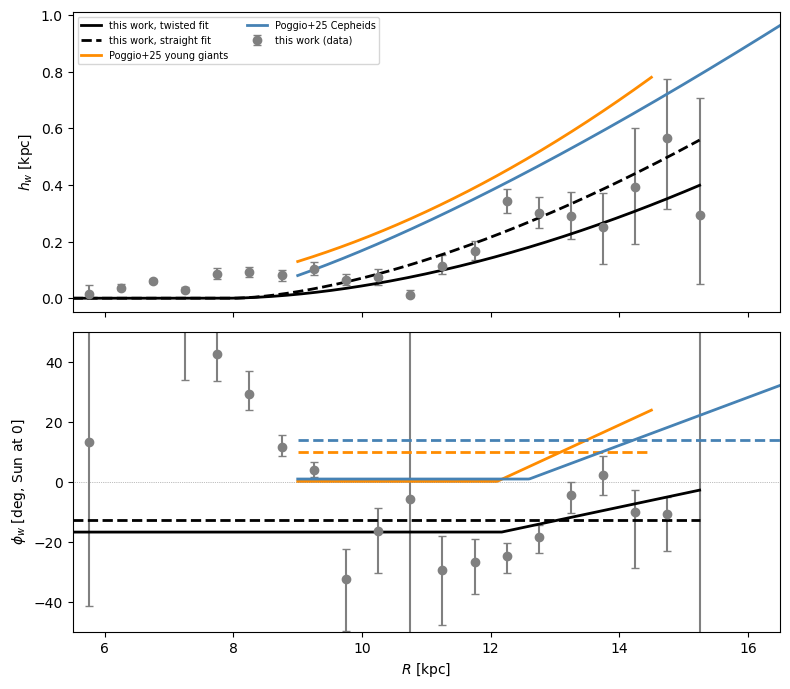

In [62]:
R_grid_yg = np.linspace(9, 14.5, 300)
R_grid_ceph = np.linspace(9, 16.5, 300)
R_grid_mine = np.linspace(R_all.min(), R_all.max(), 300)   # from your own global-fit data range

# --- Poggio+25 amplitude curves (twisted-form A(R), same regardless of straight/twisted LON) ---
hw_yg = h_w_paper(R_grid_yg, yg["R_w"], yg["h_w0"], yg["alpha_w"])
hw_ceph = h_w_paper(R_grid_ceph, ceph["R_w"], ceph["h_w0"], ceph["alpha_w"])

# --- Poggio+25 phase curves ---
phi_yg_twisted = phiLON_paper(R_grid_yg, yg["phiLON0"], yg["R_t"], yg["beta_w"])
phi_yg_straight = np.full_like(R_grid_yg, yg_straight_phiLON)

phi_ceph_twisted = phiLON_paper(R_grid_ceph, ceph["phiLON0"], ceph["R_t"], ceph["beta_w"])
phi_ceph_straight = np.full_like(R_grid_ceph, ceph_straight_phiLON)

# --- your own global fit curves (straight: med_s, twisted: med_t, from earlier emcee global fit) ---
h_w0_s, R_w_s, alpha_w_s, phiLON0_s = med_s
h_w0_t, R_w_t, alpha_w_t, phiLON0_t, R_t_t, beta_w_t = med_t

hw_mine_straight = A_of_R(R_grid_mine, h_w0_s, R_w_s, alpha_w_s)
hw_mine_twisted = A_of_R(R_grid_mine, h_w0_t, R_w_t, alpha_w_t)

phi_mine_straight = np.full_like(R_grid_mine, phiLON0_s)
phi_mine_twisted = phiLON_twisted(R_grid_mine, phiLON0_t, R_t_t, beta_w_t)

# --- your ring-by-ring emcee data ---
R_list = [emcee_results[i]["R_c"] for i in valid_rings]
hw_list = [emcee_results[i]["hw_med"] for i in valid_rings]
hw_err = [[emcee_results[i]["hw_lo"] for i in valid_rings],
          [emcee_results[i]["hw_hi"] for i in valid_rings]]
phiw_list = [emcee_results[i]["phiw_med"] for i in valid_rings]
phiw_err = [[emcee_results[i]["phiw_lo"] for i in valid_rings],
            [emcee_results[i]["phiw_hi"] for i in valid_rings]]

fig, axes = plt.subplots(2, 1, figsize=(8, 7), sharex=True)

# --- amplitude panel ---
axes[0].errorbar(R_list, hw_list, yerr=hw_err, fmt='o', color='grey', capsize=3, label='this work (data)')
axes[0].plot(R_grid_mine, hw_mine_twisted, color='black', lw=2, ls='-', label='this work, twisted fit')
axes[0].plot(R_grid_mine, hw_mine_straight, color='black', lw=2, ls='--', label='this work, straight fit')
axes[0].plot(R_grid_yg, hw_yg, color='darkorange', lw=2, label='Poggio+25 young giants')
axes[0].plot(R_grid_ceph, hw_ceph, color='steelblue', lw=2, label='Poggio+25 Cepheids')
axes[0].set_ylabel(r"$h_w$ [kpc]")
axes[0].legend(fontsize=7, ncol=2)

# --- phase panel ---
axes[1].errorbar(R_list, phiw_list, yerr=phiw_err, fmt='o', color='grey', capsize=3)
axes[1].plot(R_grid_mine, phi_mine_twisted, color='black', lw=2, ls='-')
axes[1].plot(R_grid_mine, phi_mine_straight, color='black', lw=2, ls='--')
axes[1].plot(R_grid_yg, phi_yg_twisted, color='darkorange', lw=2, ls='-')
axes[1].plot(R_grid_yg, phi_yg_straight, color='darkorange', lw=2, ls='--')
axes[1].plot(R_grid_ceph, phi_ceph_twisted, color='steelblue', lw=2, ls='-')
axes[1].plot(R_grid_ceph, phi_ceph_straight, color='steelblue', lw=2, ls='--')
axes[1].axhline(0, color='gray', lw=0.5, ls=':')
axes[1].set_ylabel(r"$\phi_w$ [deg, Sun at 0]")
axes[1].set_xlabel(r"$R$ [kpc]")
axes[1].set_xlim(5.5, 16.5)
axes[1].set_ylim(-50, 50)

plt.tight_layout()
plt.show()

In [77]:
label_w = 42  # >= length of your longest label

print(f"{'Model':{label_w}s} {'phi_LON [deg]':>10s}")
print("-" * (label_w + 11))

print(f"{'this work, straight':{label_w}s} {phiLON0_s:10.2f}")
print(f"{'this work, twisted (R<R_t)':{label_w}s} {phiLON0_t:10.2f}")

print(f"{'Poggio+25 young giants, straight':{label_w}s} {yg_straight_phiLON:10.2f}")
print(f"{'Poggio+25 young giants, twisted (R<R_t)':{label_w}s} {yg['phiLON0']:10.2f}")

print(f"{'Poggio+25 Cepheids, straight':{label_w}s} {ceph_straight_phiLON:10.2f}")
print(f"{'Poggio+25 Cepheids, twisted (R<R_t)':{label_w}s} {ceph['phiLON0']:10.2f}")

print("    ")
print("-" * (label_w + 11))
print(f"{'this work, twisted R_t':{label_w}s} {R_t_t:10.2f}")
print(f"{'this work, twisted beta_w':{label_w}s} {beta_w_t:10.2f}")


Model                                      phi_LON [deg]
-----------------------------------------------------
this work, straight                            -12.72
this work, twisted (R<R_t)                     -16.79
Poggio+25 young giants, straight                 9.90
Poggio+25 young giants, twisted (R<R_t)          0.10
Poggio+25 Cepheids, straight                    14.00
Poggio+25 Cepheids, twisted (R<R_t)              0.90
    
-----------------------------------------------------
this work, twisted R_t                          12.17
this work, twisted beta_w                        4.54


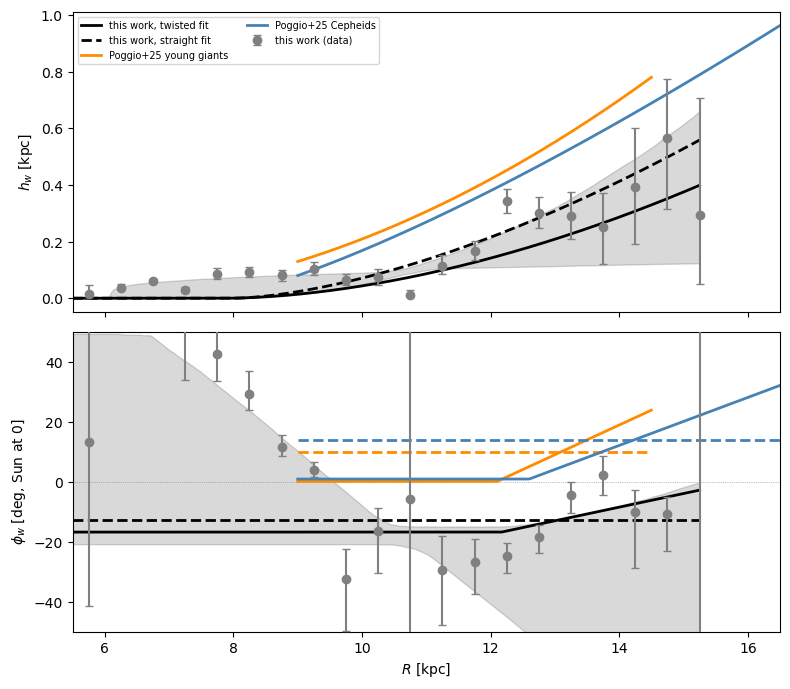

In [102]:
R_grid_yg = np.linspace(9, 14.5, 300)
R_grid_ceph = np.linspace(9, 16.5, 300)
R_grid_mine = np.linspace(R_all.min(), R_all.max(), 300)

# --- Poggio+25 amplitude curves ---
hw_yg = h_w_paper(R_grid_yg, yg["R_w"], yg["h_w0"], yg["alpha_w"])
hw_ceph = h_w_paper(R_grid_ceph, ceph["R_w"], ceph["h_w0"], ceph["alpha_w"])

# --- Poggio+25 phase curves ---
phi_yg_twisted = phiLON_paper(R_grid_yg, yg["phiLON0"], yg["R_t"], yg["beta_w"])
phi_yg_straight = np.full_like(R_grid_yg, yg_straight_phiLON)

phi_ceph_twisted = phiLON_paper(R_grid_ceph, ceph["phiLON0"], ceph["R_t"], ceph["beta_w"])
phi_ceph_straight = np.full_like(R_grid_ceph, ceph_straight_phiLON)

# --- your own global fit medians ---
h_w0_s, R_w_s, alpha_w_s, phiLON0_s = med_s
h_w0_t, R_w_t, alpha_w_t, phiLON0_t, R_t_t, beta_w_t = med_t

hw_mine_straight = A_of_R(R_grid_mine, h_w0_s, R_w_s, alpha_w_s)
hw_mine_twisted = A_of_R(R_grid_mine, h_w0_t, R_w_t, alpha_w_t)

phi_mine_straight = np.full_like(R_grid_mine, phiLON0_s)
phi_mine_twisted = phiLON_twisted(R_grid_mine, phiLON0_t, R_t_t, beta_w_t)

# --- your ring-by-ring emcee data ---
R_list = [emcee_results[i]["R_c"] for i in valid_rings]
hw_list = [emcee_results[i]["hw_med"] for i in valid_rings]
hw_err = [[emcee_results[i]["hw_lo"] for i in valid_rings],
          [emcee_results[i]["hw_hi"] for i in valid_rings]]
phiw_list = [emcee_results[i]["phiw_med"] for i in valid_rings]
phiw_err = [[emcee_results[i]["phiw_lo"] for i in valid_rings],
            [emcee_results[i]["phiw_hi"] for i in valid_rings]]

# --- pointwise 16-84 percentile uncertainty band for "this work" twisted curve ---
# draw only from the second half of samples_twisted, to avoid any skew from earlier draws
n_sub = 200
np.random.seed(0)
half = samples_twisted.shape[0] // 2
idx_sub = np.random.choice(np.arange(half, samples_twisted.shape[0]), n_sub, replace=False)

hw_sub = np.zeros((n_sub, R_grid_mine.size))
phi_sub = np.zeros((n_sub, R_grid_mine.size))

for j, i in enumerate(idx_sub):
    h_w0_d, R_w_d, alpha_w_d, phiLON0_d, R_t_d, beta_w_d = samples_twisted[i]
    hw_sub[j] = A_of_R(R_grid_mine, h_w0_d, R_w_d, alpha_w_d)
    phi_sub[j] = phiLON_twisted(R_grid_mine, phiLON0_d, R_t_d, beta_w_d)

hw_lo, hw_hi = np.percentile(hw_sub, [16, 84], axis=0)
phi_lo, phi_hi = np.percentile(phi_sub, [16, 84], axis=0)

fig, axes = plt.subplots(2, 1, figsize=(8, 7), sharex=True)

# --- amplitude panel ---
axes[0].fill_between(R_grid_mine, hw_lo, hw_hi, color='black', alpha=0.15, zorder=1)
axes[0].plot(R_grid_mine, hw_mine_twisted, color='black', lw=2, ls='-', zorder=3, label='this work, twisted fit')
axes[0].plot(R_grid_mine, hw_mine_straight, color='black', lw=2, ls='--', zorder=3, label='this work, straight fit')
axes[0].plot(R_grid_yg, hw_yg, color='darkorange', lw=2, zorder=3, label='Poggio+25 young giants')
axes[0].plot(R_grid_ceph, hw_ceph, color='steelblue', lw=2, zorder=3, label='Poggio+25 Cepheids')
axes[0].errorbar(R_list, hw_list, yerr=hw_err, fmt='o', color='grey', capsize=3, zorder=4, label='this work (data)')
axes[0].set_ylabel(r"$h_w$ [kpc]")
axes[0].legend(fontsize=7, ncol=2)

# --- phase panel ---
axes[1].fill_between(R_grid_mine, phi_lo, phi_hi, color='black', alpha=0.15, zorder=1)
axes[1].plot(R_grid_mine, phi_mine_twisted, color='black', lw=2, ls='-', zorder=3)
axes[1].plot(R_grid_mine, phi_mine_straight, color='black', lw=2, ls='--', zorder=3)
axes[1].plot(R_grid_yg, phi_yg_twisted, color='darkorange', lw=2, ls='-', zorder=3)
axes[1].plot(R_grid_yg, phi_yg_straight, color='darkorange', lw=2, ls='--', zorder=3)
axes[1].plot(R_grid_ceph, phi_ceph_twisted, color='steelblue', lw=2, ls='-', zorder=3)
axes[1].plot(R_grid_ceph, phi_ceph_straight, color='steelblue', lw=2, ls='--', zorder=3)
axes[1].errorbar(R_list, phiw_list, yerr=phiw_err, fmt='o', color='grey', capsize=3, zorder=4)
axes[1].axhline(0, color='gray', lw=0.5, ls=':')
axes[1].set_ylabel(r"$\phi_w$ [deg, Sun at 0]")
axes[1].set_xlabel(r"$R$ [kpc]")
axes[1].set_xlim(5.5, 16.5)
axes[1].set_ylim(-50, 50)

plt.tight_layout()
plt.show()

In [173]:
# --- dominant mode (already have this) ---
med_t_dominant = np.median(samples_twisted_dominant, axis=0)
h_w0_t, R_w_t, alpha_w_t, phiLON0_t, R_t_t, beta_w_t = med_t_dominant

# --- minority mode ---
samples_twisted_minority = samples_twisted[~dominant_mask]
med_t_minority = np.median(samples_twisted_minority, axis=0)
h_w0_m, R_w_m, alpha_w_m, phiLON0_m, R_t_m, beta_w_m = med_t_minority

print(f"dominant mode  ({samples_twisted_dominant.shape[0]} samples): "
      f"h_w0={h_w0_t:.4f}, R_w={R_w_t:.2f}, alpha_w={alpha_w_t:.2f}, "
      f"phiLON0={phiLON0_t:.2f}, R_t={R_t_t:.2f}, beta_w={beta_w_t:.2f}")
print(f"minority mode  ({samples_twisted_minority.shape[0]} samples): "
      f"h_w0={h_w0_m:.4f}, R_w={R_w_m:.2f}, alpha_w={alpha_w_m:.2f}, "
      f"phiLON0={phiLON0_m:.2f}, R_t={R_t_m:.2f}, beta_w={beta_w_m:.2f}")

R_grid_yg = np.linspace(9, 14.5, 300)
R_grid_ceph = np.linspace(9, 16.5, 300)
R_grid_mine = np.linspace(R_all.min(), R_all.max(), 300)

# --- Poggio+25 amplitude curves ---
hw_yg = h_w_paper(R_grid_yg, yg["R_w"], yg["h_w0"], yg["alpha_w"])
hw_ceph = h_w_paper(R_grid_ceph, ceph["R_w"], ceph["h_w0"], ceph["alpha_w"])

# --- Poggio+25 phase curves ---
phi_yg_twisted = phiLON_paper(R_grid_yg, yg["phiLON0"], yg["R_t"], yg["beta_w"])
phi_yg_straight = np.full_like(R_grid_yg, yg_straight_phiLON)

phi_ceph_twisted = phiLON_paper(R_grid_ceph, ceph["phiLON0"], ceph["R_t"], ceph["beta_w"])
phi_ceph_straight = np.full_like(R_grid_ceph, ceph_straight_phiLON)

# --- your own global fit: straight model (unaffected by this) ---
h_w0_s, R_w_s, alpha_w_s, phiLON0_s = med_s
hw_mine_straight = A_of_R(R_grid_mine, h_w0_s, R_w_s, alpha_w_s)
phi_mine_straight = np.full_like(R_grid_mine, phiLON0_s)

# --- your ring-by-ring emcee data ---
R_list = [emcee_results[i]["R_c"] for i in valid_rings]
hw_list = [emcee_results[i]["hw_med"] for i in valid_rings]
hw_err = [[emcee_results[i]["hw_lo"] for i in valid_rings],
          [emcee_results[i]["hw_hi"] for i in valid_rings]]
phiw_list = [emcee_results[i]["phiw_med"] for i in valid_rings]
phiw_err = [[emcee_results[i]["phiw_lo"] for i in valid_rings],
            [emcee_results[i]["phiw_hi"] for i in valid_rings]]

# --- posterior draws, DOMINANT mode ---
n_sub = 200
n_median = 2000
np.random.seed(0)

idx_sub_dom = np.random.choice(samples_twisted_dominant.shape[0], n_sub, replace=False)
idx_median_dom = np.random.choice(samples_twisted_dominant.shape[0], n_median, replace=False)

hw_sub_dom = np.zeros((n_sub, R_grid_mine.size))
phi_sub_dom = np.zeros((n_sub, R_grid_mine.size))
for j, i in enumerate(idx_sub_dom):
    h_w0_d, R_w_d, alpha_w_d, phiLON0_d, R_t_d, beta_w_d = samples_twisted_dominant[i]
    hw_sub_dom[j] = A_of_R(R_grid_mine, h_w0_d, R_w_d, alpha_w_d)
    phi_sub_dom[j] = phiLON_twisted(R_grid_mine, phiLON0_d, R_t_d, beta_w_d)

hw_median_draws_dom = np.zeros((n_median, R_grid_mine.size))
phi_median_draws_dom = np.zeros((n_median, R_grid_mine.size))
for j, i in enumerate(idx_median_dom):
    h_w0_d, R_w_d, alpha_w_d, phiLON0_d, R_t_d, beta_w_d = samples_twisted_dominant[i]
    hw_median_draws_dom[j] = A_of_R(R_grid_mine, h_w0_d, R_w_d, alpha_w_d)
    phi_median_draws_dom[j] = phiLON_twisted(R_grid_mine, phiLON0_d, R_t_d, beta_w_d)

hw_mine_twisted_dom = np.median(hw_median_draws_dom, axis=0)
phi_mine_twisted_dom = np.median(phi_median_draws_dom, axis=0)

# --- posterior draws, MINORITY mode ---
n_sub_min = min(n_sub, samples_twisted_minority.shape[0])
n_median_min = min(n_median, samples_twisted_minority.shape[0])

idx_sub_min = np.random.choice(samples_twisted_minority.shape[0], n_sub_min, replace=False)
idx_median_min = np.random.choice(samples_twisted_minority.shape[0], n_median_min, replace=False)

hw_sub_min = np.zeros((n_sub_min, R_grid_mine.size))
phi_sub_min = np.zeros((n_sub_min, R_grid_mine.size))
for j, i in enumerate(idx_sub_min):
    h_w0_d, R_w_d, alpha_w_d, phiLON0_d, R_t_d, beta_w_d = samples_twisted_minority[i]
    hw_sub_min[j] = A_of_R(R_grid_mine, h_w0_d, R_w_d, alpha_w_d)
    phi_sub_min[j] = phiLON_twisted(R_grid_mine, phiLON0_d, R_t_d, beta_w_d)

hw_median_draws_min = np.zeros((n_median_min, R_grid_mine.size))
phi_median_draws_min = np.zeros((n_median_min, R_grid_mine.size))
for j, i in enumerate(idx_median_min):
    h_w0_d, R_w_d, alpha_w_d, phiLON0_d, R_t_d, beta_w_d = samples_twisted_minority[i]
    hw_median_draws_min[j] = A_of_R(R_grid_mine, h_w0_d, R_w_d, alpha_w_d)
    phi_median_draws_min[j] = phiLON_twisted(R_grid_mine, phiLON0_d, R_t_d, beta_w_d)

hw_mine_twisted_min = np.median(hw_median_draws_min, axis=0)
phi_mine_twisted_min = np.median(phi_median_draws_min, axis=0)

fig, axes = plt.subplots(2, 1, figsize=(8, 7), sharex=True)

# --- amplitude panel ---
for j in range(n_sub):
    axes[0].plot(R_grid_mine, hw_sub_dom[j], color='black', lw=0.5, alpha=0.05, zorder=1)
for j in range(n_sub_min):
    axes[0].plot(R_grid_mine, hw_sub_min[j], color='crimson', lw=0.5, alpha=0.05, zorder=1)

axes[0].plot(R_grid_mine, hw_mine_twisted_dom, color='black', lw=2, ls='-', zorder=3,
             label='this work, twisted (dominant mode)')
axes[0].plot(R_grid_mine, hw_mine_twisted_min, color='crimson', lw=2, ls='-', zorder=3,
             label='this work, twisted (minority mode)')
axes[0].plot(R_grid_mine, hw_mine_straight, color='green', lw=2, ls='--', zorder=3, label='this work, straight fit')
axes[0].plot(R_grid_yg, hw_yg, color='darkorange', lw=2, zorder=3, label='Poggio+25 young giants')
axes[0].plot(R_grid_ceph, hw_ceph, color='steelblue', lw=2, zorder=3, label='Poggio+25 Cepheids')
axes[0].errorbar(R_list, hw_list, yerr=hw_err, fmt='o', color='grey', capsize=3, zorder=4, label='this work (data)')
axes[0].set_ylabel(r"$h_w$ [kpc]")
axes[0].legend(fontsize=6, ncol=2)

# --- phase panel ---
for j in range(n_sub):
    axes[1].plot(R_grid_mine, phi_sub_dom[j], color='black', lw=0.5, alpha=0.05, zorder=1)
for j in range(n_sub_min):
    axes[1].plot(R_grid_mine, phi_sub_min[j], color='crimson', lw=0.5, alpha=0.05, zorder=1)

axes[1].plot(R_grid_mine, phi_mine_twisted_dom, color='black', lw=2, ls='-', zorder=3)
axes[1].plot(R_grid_mine, phi_mine_twisted_min, color='crimson', lw=2, ls='-', zorder=3)
axes[1].plot(R_grid_mine, phi_mine_straight, color='green', lw=2, ls='--', zorder=3)
axes[1].plot(R_grid_yg, phi_yg_twisted, color='darkorange', lw=2, ls='-', zorder=3)
axes[1].plot(R_grid_yg, phi_yg_straight, color='darkorange', lw=2, ls='--', zorder=3)
axes[1].plot(R_grid_ceph, phi_ceph_twisted, color='steelblue', lw=2, ls='-', zorder=3)
axes[1].plot(R_grid_ceph, phi_ceph_straight, color='steelblue', lw=2, ls='--', zorder=3)
axes[1].errorbar(R_list, phiw_list, yerr=phiw_err, fmt='o', color='grey', capsize=3, zorder=4)
axes[1].axhline(0, color='gray', lw=0.5, ls=':')
axes[1].set_ylabel(r"$\phi_w$ [deg, Sun at 0]")
axes[1].set_xlabel(r"$R$ [kpc]")
#axes[1].set_xlim(5.5, 16.5)
#axes[1].set_ylim(-50, 50)

plt.tight_layout()
plt.show()

IndexError: boolean index did not match indexed array along axis 0; size of axis is 1600000 but size of corresponding boolean axis is 300000

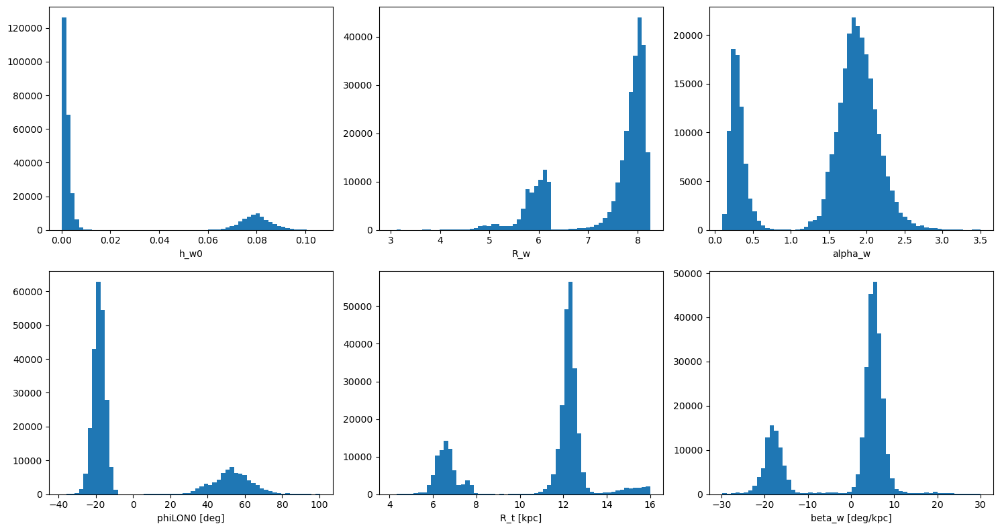

In [111]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
param_names = ["h_w0", "R_w", "alpha_w", "phiLON0 [deg]", "R_t [kpc]", "beta_w [deg/kpc]"]

for k in range(6):
    ax = axes.flat[k]
    ax.hist(samples_twisted[:, k], bins=60)
    ax.set_xlabel(param_names[k])

plt.tight_layout()
plt.show()

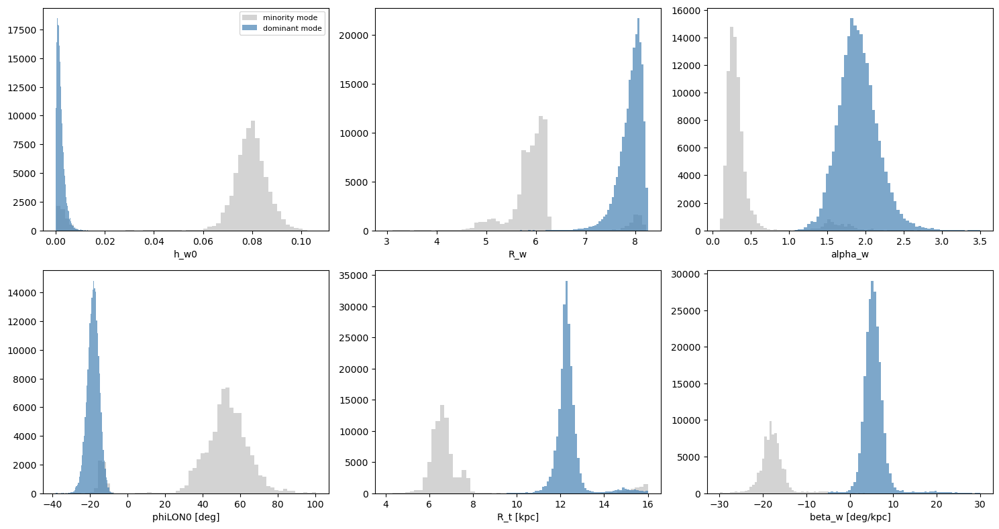

In [112]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
param_names = ["h_w0", "R_w", "alpha_w", "phiLON0 [deg]", "R_t [kpc]", "beta_w [deg/kpc]"]

for k in range(6):
    ax = axes.flat[k]
    ax.hist(samples_twisted[~dominant_mask, k], bins=60, color='lightgray', label='minority mode')
    ax.hist(samples_twisted[dominant_mask, k], bins=60, color='steelblue', alpha=0.7, label='dominant mode')
    ax.set_xlabel(param_names[k])

axes.flat[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

In [109]:
# valley between the two modes sits around R_t ~ 9-10 kpc and beta_w ~ -8 to -5 deg/kpc
dominant_mask = (samples_twisted[:, 4] > 9.5) & (samples_twisted[:, 5] > -5)
samples_twisted_dominant = samples_twisted[dominant_mask]

print(f"dominant mode: {samples_twisted_dominant.shape[0]} / {samples_twisted.shape[0]} samples "
      f"({100*samples_twisted_dominant.shape[0]/samples_twisted.shape[0]:.1f}%)")

dominant mode: 219397 / 300000 samples (73.1%)


dominant-mode twisted medians: h_w0=0.0016, R_w=7.96, alpha_w=1.89, phiLON0=-18.21, R_t=12.28, beta_w=5.36


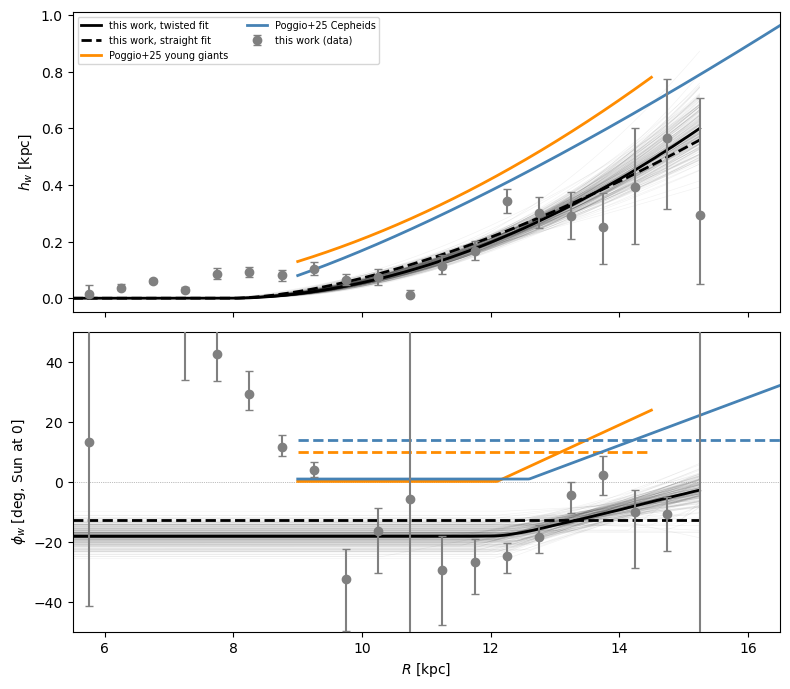

In [115]:
# recompute median parameters from the dominant mode only
med_t_dominant = np.median(samples_twisted_dominant, axis=0)
h_w0_t, R_w_t, alpha_w_t, phiLON0_t, R_t_t, beta_w_t = med_t_dominant

print(f"dominant-mode twisted medians: h_w0={h_w0_t:.4f}, R_w={R_w_t:.2f}, alpha_w={alpha_w_t:.2f}, "
      f"phiLON0={phiLON0_t:.2f}, R_t={R_t_t:.2f}, beta_w={beta_w_t:.2f}")

R_grid_yg = np.linspace(9, 14.5, 300)
R_grid_ceph = np.linspace(9, 16.5, 300)
R_grid_mine = np.linspace(R_all.min(), R_all.max(), 300)

# --- Poggio+25 amplitude curves ---
hw_yg = h_w_paper(R_grid_yg, yg["R_w"], yg["h_w0"], yg["alpha_w"])
hw_ceph = h_w_paper(R_grid_ceph, ceph["R_w"], ceph["h_w0"], ceph["alpha_w"])

# --- Poggio+25 phase curves ---
phi_yg_twisted = phiLON_paper(R_grid_yg, yg["phiLON0"], yg["R_t"], yg["beta_w"])
phi_yg_straight = np.full_like(R_grid_yg, yg_straight_phiLON)

phi_ceph_twisted = phiLON_paper(R_grid_ceph, ceph["phiLON0"], ceph["R_t"], ceph["beta_w"])
phi_ceph_straight = np.full_like(R_grid_ceph, ceph_straight_phiLON)

# --- your own global fit: straight model (unaffected by this) ---
h_w0_s, R_w_s, alpha_w_s, phiLON0_s = med_s
hw_mine_straight = A_of_R(R_grid_mine, h_w0_s, R_w_s, alpha_w_s)
phi_mine_straight = np.full_like(R_grid_mine, phiLON0_s)

# --- your ring-by-ring emcee data ---
R_list = [emcee_results[i]["R_c"] for i in valid_rings]
hw_list = [emcee_results[i]["hw_med"] for i in valid_rings]
hw_err = [[emcee_results[i]["hw_lo"] for i in valid_rings],
          [emcee_results[i]["hw_hi"] for i in valid_rings]]
phiw_list = [emcee_results[i]["phiw_med"] for i in valid_rings]
phiw_err = [[emcee_results[i]["phiw_lo"] for i in valid_rings],
            [emcee_results[i]["phiw_hi"] for i in valid_rings]]

# --- posterior draws, from the DOMINANT MODE only ---
n_sub = 200
n_median = 2000
np.random.seed(0)

idx_sub = np.random.choice(samples_twisted_dominant.shape[0], n_sub, replace=False)
idx_median = np.random.choice(samples_twisted_dominant.shape[0], n_median, replace=False)

hw_sub = np.zeros((n_sub, R_grid_mine.size))
phi_sub = np.zeros((n_sub, R_grid_mine.size))
for j, i in enumerate(idx_sub):
    h_w0_d, R_w_d, alpha_w_d, phiLON0_d, R_t_d, beta_w_d = samples_twisted_dominant[i]
    hw_sub[j] = A_of_R(R_grid_mine, h_w0_d, R_w_d, alpha_w_d)
    phi_sub[j] = phiLON_twisted(R_grid_mine, phiLON0_d, R_t_d, beta_w_d)

hw_median_draws = np.zeros((n_median, R_grid_mine.size))
phi_median_draws = np.zeros((n_median, R_grid_mine.size))
for j, i in enumerate(idx_median):
    h_w0_d, R_w_d, alpha_w_d, phiLON0_d, R_t_d, beta_w_d = samples_twisted_dominant[i]
    hw_median_draws[j] = A_of_R(R_grid_mine, h_w0_d, R_w_d, alpha_w_d)
    phi_median_draws[j] = phiLON_twisted(R_grid_mine, phiLON0_d, R_t_d, beta_w_d)

hw_mine_twisted = np.median(hw_median_draws, axis=0)
phi_mine_twisted = np.median(phi_median_draws, axis=0)

fig, axes = plt.subplots(2, 1, figsize=(8, 7), sharex=True)

# --- amplitude panel ---
for j in range(n_sub):
    axes[0].plot(R_grid_mine, hw_sub[j], color='black', lw=0.5, alpha=0.05, zorder=1)

axes[0].plot(R_grid_mine, hw_mine_twisted, color='black', lw=2, ls='-', zorder=3, label='this work, twisted fit')
axes[0].plot(R_grid_mine, hw_mine_straight, color='black', lw=2, ls='--', zorder=3, label='this work, straight fit')
axes[0].plot(R_grid_yg, hw_yg, color='darkorange', lw=2, zorder=3, label='Poggio+25 young giants')
axes[0].plot(R_grid_ceph, hw_ceph, color='steelblue', lw=2, zorder=3, label='Poggio+25 Cepheids')
axes[0].errorbar(R_list, hw_list, yerr=hw_err, fmt='o', color='grey', capsize=3, zorder=4, label='this work (data)')
axes[0].set_ylabel(r"$h_w$ [kpc]")
axes[0].legend(fontsize=7, ncol=2)

# --- phase panel ---
for j in range(n_sub):
    axes[1].plot(R_grid_mine, phi_sub[j], color='black', lw=0.5, alpha=0.05, zorder=1)

axes[1].plot(R_grid_mine, phi_mine_twisted, color='black', lw=2, ls='-', zorder=3)
axes[1].plot(R_grid_mine, phi_mine_straight, color='black', lw=2, ls='--', zorder=3)
axes[1].plot(R_grid_yg, phi_yg_twisted, color='darkorange', lw=2, ls='-', zorder=3)
axes[1].plot(R_grid_yg, phi_yg_straight, color='darkorange', lw=2, ls='--', zorder=3)
axes[1].plot(R_grid_ceph, phi_ceph_twisted, color='steelblue', lw=2, ls='-', zorder=3)
axes[1].plot(R_grid_ceph, phi_ceph_straight, color='steelblue', lw=2, ls='--', zorder=3)
axes[1].errorbar(R_list, phiw_list, yerr=phiw_err, fmt='o', color='grey', capsize=3, zorder=4)
axes[1].axhline(0, color='gray', lw=0.5, ls=':')
axes[1].set_ylabel(r"$\phi_w$ [deg, Sun at 0]")
axes[1].set_xlabel(r"$R$ [kpc]")
axes[1].set_xlim(5.5, 16.5)
axes[1].set_ylim(-50, 50)

plt.tight_layout()
plt.show()

In [177]:
def make_twisted_plot(samples, title_suffix, n_sub=200, n_median=2000, seed=0):
    med = np.median(samples, axis=0)
    h_w0_t, R_w_t, alpha_w_t, phiLON0_t, R_t_t, beta_w_t = med

    np.random.seed(seed)
    idx_sub = np.random.choice(samples.shape[0], n_sub, replace=False)
    idx_median = np.random.choice(samples.shape[0], n_median, replace=False)

    hw_sub = np.zeros((n_sub, R_grid_mine.size))
    phi_sub = np.zeros((n_sub, R_grid_mine.size))
    for j, i in enumerate(idx_sub):
        h_w0_d, R_w_d, alpha_w_d, phiLON0_d, R_t_d, beta_w_d = samples[i]
        hw_sub[j] = A_of_R(R_grid_mine, h_w0_d, R_w_d, alpha_w_d)
        phi_sub[j] = phiLON_twisted(R_grid_mine, phiLON0_d, R_t_d, beta_w_d)

    hw_median_draws = np.zeros((n_median, R_grid_mine.size))
    phi_median_draws = np.zeros((n_median, R_grid_mine.size))
    for j, i in enumerate(idx_median):
        h_w0_d, R_w_d, alpha_w_d, phiLON0_d, R_t_d, beta_w_d = samples[i]
        hw_median_draws[j] = A_of_R(R_grid_mine, h_w0_d, R_w_d, alpha_w_d)
        phi_median_draws[j] = phiLON_twisted(R_grid_mine, phiLON0_d, R_t_d, beta_w_d)

    hw_mine_twisted = np.median(hw_median_draws, axis=0)
    phi_mine_twisted = np.median(phi_median_draws, axis=0)

    fig, axes = plt.subplots(2, 1, figsize=(8, 7), sharex=True)

    for j in range(n_sub):
        axes[0].plot(R_grid_mine, hw_sub[j], color='black', lw=0.5, alpha=0.05, zorder=1)
    axes[0].plot(R_grid_mine, hw_mine_twisted, color='black', lw=2, ls='-', zorder=3, label='this work, twisted fit')
    axes[0].plot(R_grid_mine, hw_mine_straight, color='black', lw=2, ls='--', zorder=3, label='this work, straight fit')
    axes[0].plot(R_grid_yg, hw_yg, color='darkorange', lw=2, zorder=3, label='Poggio+25 young giants')
    axes[0].plot(R_grid_ceph, hw_ceph, color='steelblue', lw=2, zorder=3, label='Poggio+25 Cepheids')
    axes[0].errorbar(R_list, hw_list, yerr=hw_err, fmt='o', color='grey', capsize=3, zorder=4, label='this work (data)')
    axes[0].set_ylabel(r"$h_w$ [kpc]")
    axes[0].set_title(title_suffix)
    axes[0].legend(fontsize=7, ncol=2)

    for j in range(n_sub):
        axes[1].plot(R_grid_mine, phi_sub[j], color='black', lw=0.5, alpha=0.05, zorder=1)
    axes[1].plot(R_grid_mine, phi_mine_twisted, color='black', lw=2, ls='-', zorder=3)
    axes[1].plot(R_grid_mine, phi_mine_straight, color='black', lw=2, ls='--', zorder=3)
    axes[1].plot(R_grid_yg, phi_yg_twisted, color='darkorange', lw=2, ls='-', zorder=3)
    axes[1].plot(R_grid_yg, phi_yg_straight, color='darkorange', lw=2, ls='--', zorder=3)
    axes[1].plot(R_grid_ceph, phi_ceph_twisted, color='steelblue', lw=2, ls='-', zorder=3)
    axes[1].plot(R_grid_ceph, phi_ceph_straight, color='steelblue', lw=2, ls='--', zorder=3)
    axes[1].errorbar(R_list, phiw_list, yerr=phiw_err, fmt='o', color='grey', capsize=3, zorder=4)
    axes[1].axhline(0, color='gray', lw=0.5, ls=':')
    axes[1].set_ylabel(r"$\phi_w$ [deg, Sun at 0]")
    axes[1].set_xlabel(r"$R$ [kpc]")
    axes[1].set_xlim(5.5, 16.5)
    axes[1].set_ylim(-50, 50)

    plt.tight_layout()
    plt.show()

    return med

## Radial cut at 8 kpc

In [181]:
def make_twisted_plot(samples, title_suffix, n_sub=200, seed=0, R_cut_line=None):
    med = np.median(samples, axis=0)
    h_w0_t, R_w_t, alpha_w_t, phiLON0_t, R_t_t, beta_w_t = med

    hw_mine_twisted = A_of_R(R_grid_mine, h_w0_t, R_w_t, alpha_w_t)
    phi_mine_twisted = phiLON_twisted(R_grid_mine, phiLON0_t, R_t_t, beta_w_t)

    np.random.seed(seed)
    idx_sub = np.random.choice(samples.shape[0], n_sub, replace=False)

    hw_sub = np.zeros((n_sub, R_grid_mine.size))
    phi_sub = np.zeros((n_sub, R_grid_mine.size))
    for j, i in enumerate(idx_sub):
        h_w0_d, R_w_d, alpha_w_d, phiLON0_d, R_t_d, beta_w_d = samples[i]
        hw_sub[j] = A_of_R(R_grid_mine, h_w0_d, R_w_d, alpha_w_d)
        phi_sub[j] = phiLON_twisted(R_grid_mine, phiLON0_d, R_t_d, beta_w_d)

    fig, axes = plt.subplots(2, 1, figsize=(8, 7), sharex=True)

    for j in range(n_sub):
        axes[0].plot(R_grid_mine, hw_sub[j], color='black', lw=0.5, alpha=0.05, zorder=1)
    axes[0].plot(R_grid_mine, hw_mine_twisted, color='black', lw=2, ls='-', zorder=3, label='this work, twisted fit')
    axes[0].plot(R_grid_mine, hw_mine_straight, color='black', lw=2, ls='--', zorder=3, label='this work, straight fit')
    axes[0].plot(R_grid_yg, hw_yg, color='darkorange', lw=2, zorder=3, label='Poggio+25 young giants')
    axes[0].plot(R_grid_ceph, hw_ceph, color='steelblue', lw=2, zorder=3, label='Poggio+25 Cepheids')
    axes[0].errorbar(R_list, hw_list, yerr=hw_err, fmt='o', color='grey', capsize=3, zorder=4, label='this work (data)')
    if R_cut_line is not None:
        axes[0].axvline(R_cut_line, color='red', lw=1, ls=':', zorder=2)
    axes[0].set_ylabel(r"$h_w$ [kpc]")
    axes[0].set_title(title_suffix)
    axes[0].legend(fontsize=7, ncol=2)

    for j in range(n_sub):
        axes[1].plot(R_grid_mine, phi_sub[j], color='black', lw=0.5, alpha=0.05, zorder=1)
    axes[1].plot(R_grid_mine, phi_mine_twisted, color='black', lw=2, ls='-', zorder=3)
    axes[1].plot(R_grid_mine, phi_mine_straight, color='black', lw=2, ls='--', zorder=3)
    axes[1].plot(R_grid_yg, phi_yg_twisted, color='darkorange', lw=2, ls='-', zorder=3)
    axes[1].plot(R_grid_yg, phi_yg_straight, color='darkorange', lw=2, ls='--', zorder=3)
    axes[1].plot(R_grid_ceph, phi_ceph_twisted, color='steelblue', lw=2, ls='-', zorder=3)
    axes[1].plot(R_grid_ceph, phi_ceph_straight, color='steelblue', lw=2, ls='--', zorder=3)
    axes[1].errorbar(R_list, phiw_list, yerr=phiw_err, fmt='o', color='grey', capsize=3, zorder=4)
    if R_cut_line is not None:
        axes[1].axvline(R_cut_line, color='red', lw=1, ls=':', zorder=2)
    axes[1].axhline(0, color='gray', lw=0.5, ls=':')
    axes[1].set_ylabel(r"$\phi_w$ [deg, Sun at 0]")
    axes[1].set_xlabel(r"$R$ [kpc]")
#    axes[1].set_xlim(5.5, 16.5)
#    axes[1].set_ylim(-50, 50)

    plt.tight_layout()
    plt.show()

    return med

In [160]:
R_cut = 9.0
mask_Rcut = R_all >= R_cut

R_all_cut = R_all[mask_Rcut]
phi_eloisa_rad_all_cut = phi_eloisa_rad_all[mask_Rcut]
z0_all_cut = z0_all[mask_Rcut]
z0_err_all_cut = z0_err_all[mask_Rcut]

print(f"kept {mask_Rcut.sum()} / {mask_Rcut.size} data points after R >= {R_cut} cut")

p0_twisted_broad = np.array([0.3, 5.5, 1.5, -20.0, 9.0, 0.0])
nwalkers = 100
nsteps = 6000
burnin = 2000

pos_twisted_cut_broad = [p0_twisted_broad + np.abs(p0_twisted_broad) * 0.05 * np.random.randn(6) + 1e-4*np.random.randn(6)
                          for _ in range(nwalkers)]

sampler_twisted_Rcut_broad = emcee.EnsembleSampler(nwalkers, 6, lnprob_twisted,
                                                     args=(R_all_cut, phi_eloisa_rad_all_cut, z0_all_cut, z0_err_all_cut))
sampler_twisted_Rcut_broad.run_mcmc(pos_twisted_cut_broad, nsteps, progress=True)

samples_twisted_Rcut_broad = sampler_twisted_Rcut_broad.chain[:, burnin:, :].reshape((-1, 6))
med_Rcut_broad = np.median(samples_twisted_Rcut_broad, axis=0)

print(sampler_twisted_Rcut_broad.acceptance_fraction.mean())
print(f"R>=8 (broad init) twisted medians: h_w0={med_Rcut_broad[0]:.4f}, R_w={med_Rcut_broad[1]:.2f}, "
      f"alpha_w={med_Rcut_broad[2]:.2f}, phiLON0={med_Rcut_broad[3]:.2f}, "
      f"R_t={med_Rcut_broad[4]:.2f}, beta_w={med_Rcut_broad[5]:.2f}")

kept 114 / 207 data points after R >= 9.0 cut


100%|██████████████████████████████████████| 6000/6000 [00:12<00:00, 467.13it/s]

0.3736966666666666
R>=8 (broad init) twisted medians: h_w0=0.0131, R_w=6.00, alpha_w=2.73, phiLON0=-18.22, R_t=12.28, beta_w=5.12


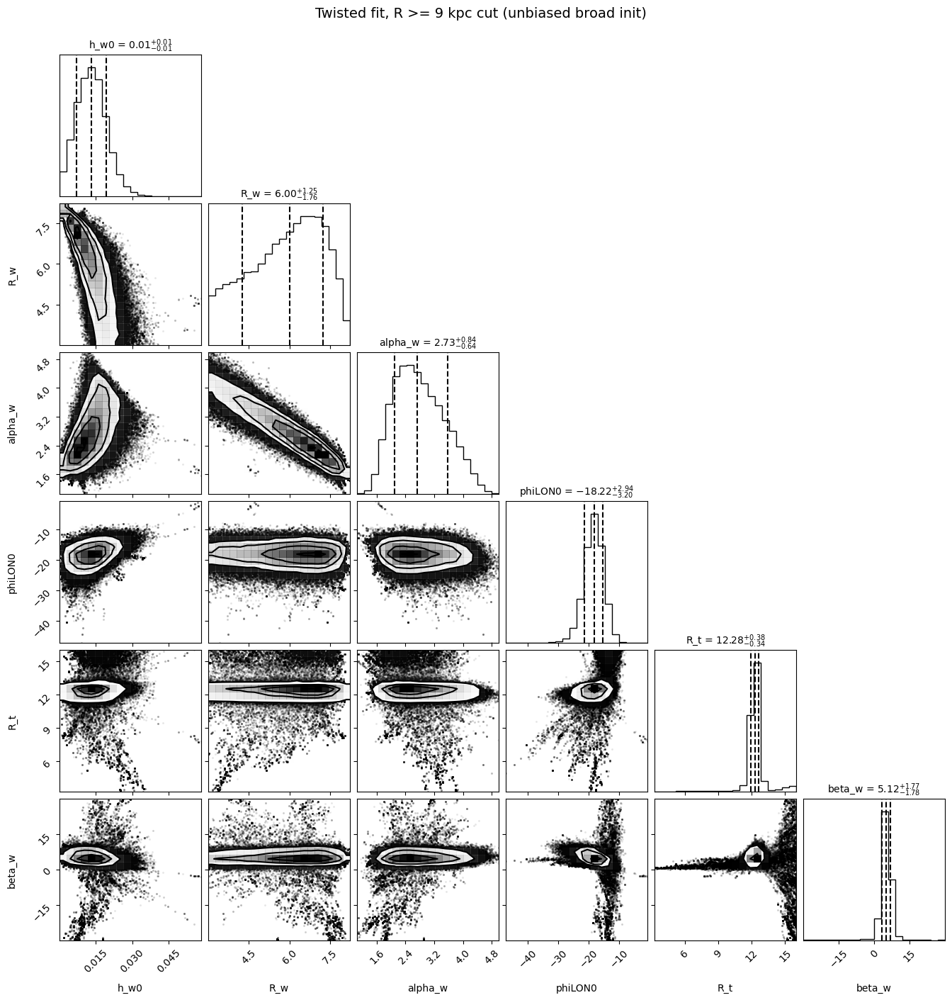

In [161]:
param_names = ["h_w0", "R_w", "alpha_w", "phiLON0", "R_t", "beta_w"]

fig = corner.corner(
    samples_twisted_Rcut_broad,
    labels=param_names,
    show_titles=True,
    title_kwargs={"fontsize": 10},
    quantiles=[0.16, 0.5, 0.84],
)
fig.suptitle("Twisted fit, R >= 9 kpc cut (unbiased broad init)", fontsize=14, y=1.02)
plt.show()

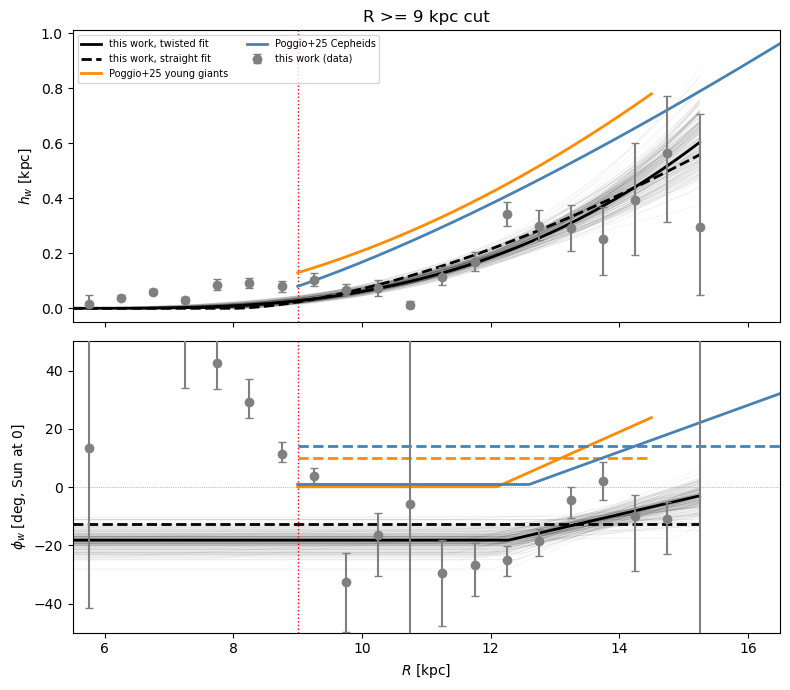

In [163]:
med_Rcut_broad_plot = make_twisted_plot(samples_twisted_Rcut_broad, "R >= 9 kpc cut", R_cut_line=9.0)

## more samples/longer chains

In [182]:
p0_twisted_broad = np.array([0.3, 5.5, 1.5, -20.0, 9.0, 0.0])
nwalkers = 100
nsteps = 6000
burnin = 2000

pos_twisted_broad = [p0_twisted_broad + np.abs(p0_twisted_broad) * 0.05 * np.random.randn(6) + 1e-4*np.random.randn(6)
                      for _ in range(nwalkers)]

sampler_twisted_broad = emcee.EnsembleSampler(nwalkers, 6, lnprob_twisted,
                                                args=(R_all, phi_eloisa_rad_all, z0_all, z0_err_all))
sampler_twisted_broad.run_mcmc(pos_twisted_broad, nsteps, progress=True)

samples_twisted_broad = sampler_twisted_broad.chain[:, burnin:, :].reshape((-1, 6))
med_broad = np.median(samples_twisted_broad, axis=0)

print(sampler_twisted_broad.acceptance_fraction.mean())
print(f"more samples (broad init) twisted medians: h_w0={med_broad[0]:.4f}, R_w={med_broad[1]:.2f}, "
      f"alpha_w={med_broad[2]:.2f}, phiLON0={med_broad[3]:.2f}, "
      f"R_t={med_broad[4]:.2f}, beta_w={med_broad[5]:.2f}")

100%|██████████████████████████████████████| 6000/6000 [00:12<00:00, 465.28it/s]

0.2363016666666667
more samples (broad init) twisted medians: h_w0=0.0028, R_w=7.79, alpha_w=1.76, phiLON0=-16.21, R_t=12.09, beta_w=4.21


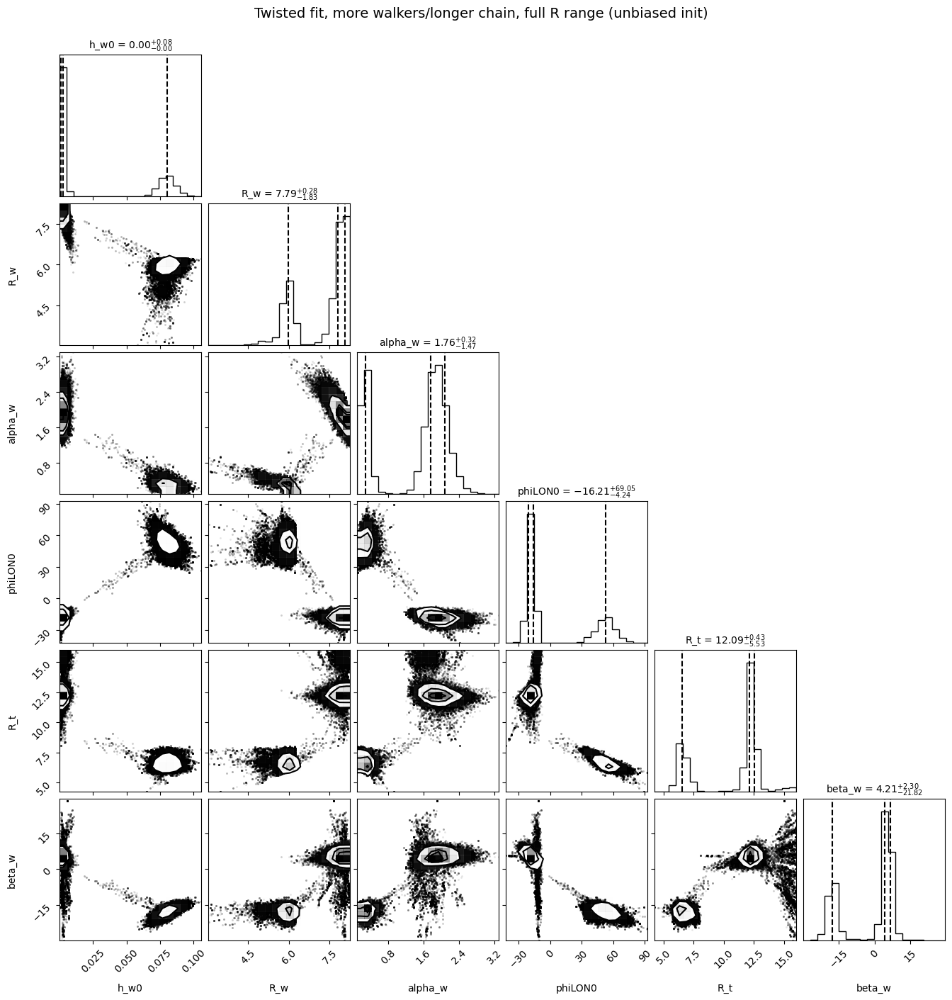

In [183]:
fig = corner.corner(
    samples_twisted_broad,
    labels=param_names,
    show_titles=True,
    title_kwargs={"fontsize": 10},
    quantiles=[0.16, 0.5, 0.84],
)
fig.suptitle("Twisted fit, more walkers/longer chain, full R range (unbiased init)", fontsize=14, y=1.02)
plt.show()

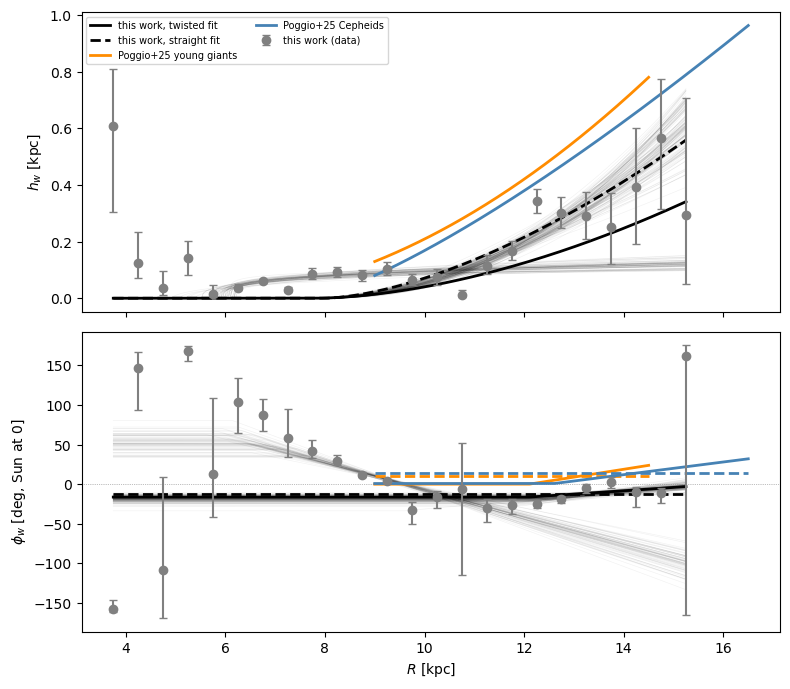

In [235]:
med_broad_plot = make_twisted_plot(samples_twisted_broad, "")

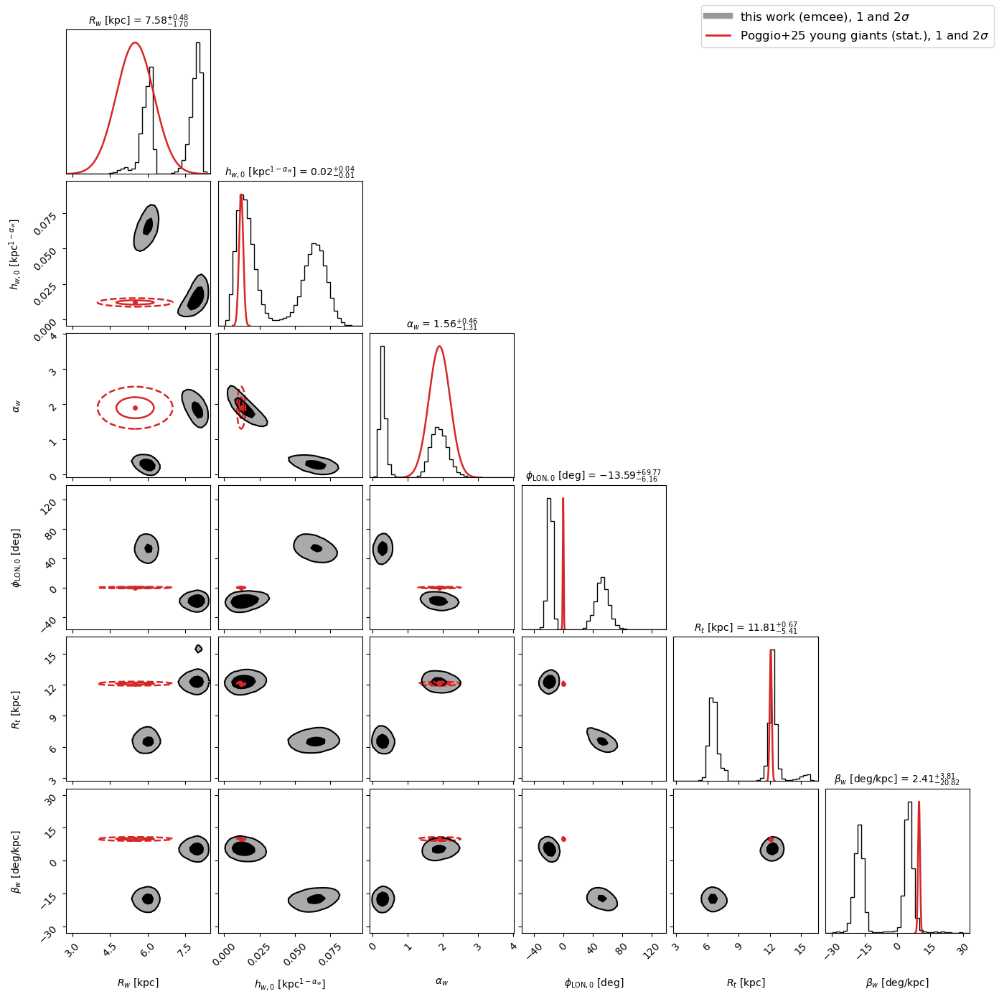

In [247]:
import numpy as np
import corner
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
from matplotlib.lines import Line2D

# ------------------------------------------------------------------
# Settings
# ------------------------------------------------------------------
UNCERTAINTY = "stat"            # "stat" = Poggio statistical only, "total" = stat and sys in quadrature
R_SUN = 8.275                   # matches the emcee model's normalization
EMCEE_SAMPLES = samples_twisted # (n, 6) flattened chain; or samples_twisted_broad

params = ["R_w", "h_w0", "alpha_w", "phi_LON0", "R_t", "beta_w"]
labels = {
    "R_w":      r"$R_w$ [kpc]",
    "h_w0":     r"$h_{w,0}$ [kpc$^{1-\alpha_w}$]",
    "alpha_w":  r"$\alpha_w$",
    "phi_LON0": r"$\phi_{\rm LON,0}$ [deg]",
    "R_t":      r"$R_t$ [kpc]",
    "beta_w":   r"$\beta_w$ [deg/kpc]",
}

# ------------------------------------------------------------------
# Your emcee chain -> dict, converting h_w0 to Poggio's amplitude convention
# emcee column order: h_w0, R_w, alpha_w, phiLON0, R_t, beta_w
# ------------------------------------------------------------------
h_e, R_w_e, alpha_e, phi0_e, R_t_e, beta_e = EMCEE_SAMPLES.T
emcee_dict = {
    "R_w":      R_w_e,
    "h_w0":     h_e / (R_SUN - R_w_e) ** alpha_e,   # converted to h_w0 (R - R_w)^alpha form
    "alpha_w":  alpha_e,
    "phi_LON0": phi0_e,
    "R_t":      R_t_e,
    "beta_w":   beta_e,
}
chain = np.column_stack([emcee_dict[p] for p in params])

# ------------------------------------------------------------------
# Poggio+25 Table 1 (young giants): best, stat(+, -), sys(+, -)
# ------------------------------------------------------------------
POGGIO_TABLE = {
    "R_w":      (5.5,   (0.8, 0.7),     (1.3, 0.8)),
    "h_w0":     (0.012, (0.002, 0.001), (0.006, 0.001)),
    "alpha_w":  (1.9,   (0.3, 0.3),     (0.5, 0.6)),
    "phi_LON0": (0.1,   (0.6, 0.6),     (1.1, 1.2)),
    "R_t":      (12.1,  (0.1, 0.1),     (0.1, 0.1)),
    "beta_w":   (9.9,   (0.5, 0.4),     (0.4, 0.2)),
}

def poggio_sigma(name):
    _, stat, sys_ = POGGIO_TABLE[name]
    s_stat = 0.5 * (stat[0] + stat[1])
    s_sys  = 0.5 * (sys_[0] + sys_[1])
    return s_stat if UNCERTAINTY == "stat" else np.hypot(s_stat, s_sys)

mu  = np.array([POGGIO_TABLE[p][0] for p in params])
sig = np.array([poggio_sigma(p) for p in params])

# ------------------------------------------------------------------
# Contour plot
# ------------------------------------------------------------------
rng = []
for k in range(len(params)):
    lo = min(chain[:, k].min(), mu[k] - 3 * sig[k])
    hi = max(chain[:, k].max(), mu[k] + 3 * sig[k])
    pad = 0.05 * (hi - lo)
    rng.append((lo - pad, hi + pad))

levels = (1 - np.exp(-0.5), 1 - np.exp(-2.0))   # 1 and 2 sigma for a 2D Gaussian

fig = corner.corner(
    chain, labels=[labels[p] for p in params], range=rng, levels=levels,
    color="k", fill_contours=True, plot_datapoints=False,
    smooth=1.0, bins=40, hist_kwargs={"density": True},
    show_titles=True, title_kwargs={"fontsize": 10},
)
fig.set_size_inches(14, 14)

n = len(params)
axes = np.array(fig.axes).reshape(n, n)

for i in range(n):
    for j in range(i):
        ax = axes[i, j]
        for k, ls in [(1, "-"), (2, "--")]:
            ax.add_patch(Ellipse((mu[j], mu[i]), 2 * k * sig[j], 2 * k * sig[i],
                                 fill=False, ec="C3", lw=1.8, ls=ls))
        ax.plot(mu[j], mu[i], "o", color="C3", ms=4)

    ax = axes[i, i]
    peak = np.histogram(chain[:, i], bins=40, range=rng[i], density=True)[0].max()
    x = np.linspace(mu[i] - 4 * sig[i], mu[i] + 4 * sig[i], 300)
    ax.plot(x, peak * np.exp(-0.5 * ((x - mu[i]) / sig[i]) ** 2), color="C3", lw=1.8)

unc_label = "stat." if UNCERTAINTY == "stat" else "stat. + sys."
fig.legend(
    handles=[
        Line2D([], [], color="k", lw=6, alpha=0.4, label=r"this work (emcee), 1 and 2$\sigma$"),
        Line2D([], [], color="C3", lw=2, label=f"Poggio+25 young giants ({unc_label}), 1 and 2$\\sigma$"),
    ],
    loc="upper right", fontsize=12,
)

fig.savefig("warp_param_contours_emcee.pdf", bbox_inches="tight")
plt.show()

In [236]:
import numpy as np

np.savez(
    "warp_ring_data_for_adrian.npz",
    R=R_all,
    phi_eloisa_rad=phi_eloisa_rad_all,
    z0=z0_all,
    z0_err=z0_err_all,
)
print("saved", len(R_all), "points to warp_ring_data_for_adrian.npz")

saved 207 points to warp_ring_data_for_adrian.npz


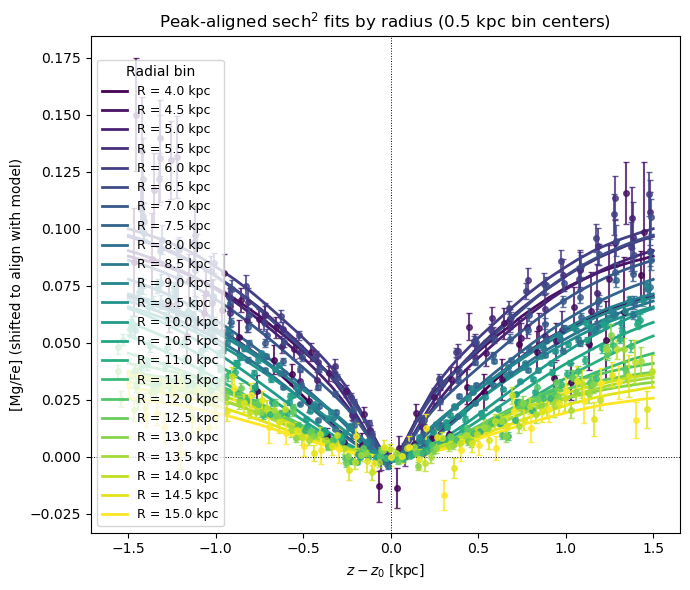

In [197]:
import matplotlib.cm as cm

R_to_show = [4,4.5,5,5.5,6,6.5,7,7.5,8,8.5,9,9.5,10,10.5, 11,11.5, 12,12.5, 13,13.5, 14,14.5, 15]
n_draws = 200

idx_to_show = [i_R for i_R in per_R_flare
               if round(R_centers_flare[i_R]*2)/2 in R_to_show]
idx_to_show = sorted(idx_to_show, key=lambda i_R: R_centers_flare[i_R])

cmap = plt.get_cmap('viridis', len(idx_to_show))
colors = {i_R: cmap(k) for k, i_R in enumerate(idx_to_show)}

fig, ax = plt.subplots(figsize=(7, 6))
z_grid = np.linspace(-1.5, 1.5, 400)
rng = np.random.default_rng(0)

for i_R in idx_to_show:
    cell = per_R_flare[i_R]
    s = cell["samples"]
    n_avail = len(s["z0"])
    draw_idx = rng.choice(n_avail, size=min(n_draws, n_avail), replace=False)

    curves = []
    for i in draw_idx:
        A1 = s["A1"][i]; A2 = s["A2"][i]
        h1 = s["h1"][i]; h2 = h1 + s["d_h2"][i]
        z0 = s["z0"][i]
        peak = A1 + A2
        curves.append(mixture_of_sech2(z_grid + z0, A1, A2, h1, h2, z0) - peak)
    model_dz = np.median(curves, axis=0)

    z0_med = np.median(s["z0"])
    dz_data = cell["z_binc"] - z0_med
    model_at_data = np.interp(dz_data, z_grid, model_dz)
    offset_shift = np.median(cell["mean"] - model_at_data)
    dy_data = cell["mean"] - offset_shift

    c = colors[i_R]
    Rc = R_centers_flare[i_R]
    ax.plot(z_grid, model_dz, '-', color=c, lw=2, label=f'R = {Rc:.1f} kpc')
    ax.errorbar(dz_data, dy_data, yerr=cell["err"],
                fmt='o', color=c, ms=4, capsize=2, alpha=0.8)

ax.axhline(0, color='k', lw=0.7, ls=':')
ax.axvline(0, color='k', lw=0.7, ls=':')
ax.set_xlabel(r'$z - z_0$ [kpc]')
ax.set_ylabel(r'[Mg/Fe] (shifted to align with model)')
ax.set_title('Peak-aligned sech$^2$ fits by radius (0.5 kpc bin centers)')
ax.legend(title='Radial bin', fontsize=9)
plt.tight_layout()
plt.show()

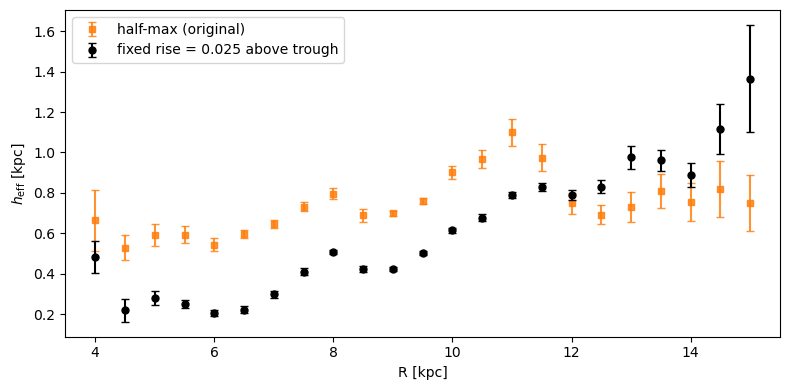

In [200]:
from scipy.optimize import brentq

DROP = 0.025

def root_func_shifted(z, pars, drop=DROP):
    peak = pars["A1"] + pars["A2"]
    Ystar = mixture_of_sech2(z, pars["A1"], pars["A2"], pars["h1"], pars["h2"], pars["z0"])
    return (Ystar - peak) - drop

h_eff_med_fixed = np.full(n_R_flare, np.nan)
h_eff_std_fixed = np.full(n_R_flare, np.nan)

for i_R, cell in per_R_flare.items():
    s = cell["samples"]
    n_draws = min(256, len(s["z0"]))
    h_effs = []
    for i in range(n_draws):
        cs = {k: v[i] for k, v in s.items()}
        cs["h2"] = cs["h1"] + cs["d_h2"]
        hi = 8 * max(cs["h1"], cs["h2"])
        try:
            zstar = brentq(root_func_shifted, cs["z0"] + 1e-9, hi, args=(cs,))
            h_effs.append(zstar - cs["z0"])
        except ValueError:
            continue
    if h_effs:
        h_effs = np.array(h_effs)
        h_eff_med_fixed[i_R] = np.median(h_effs)
        pcl = np.percentile(h_effs, [16, 84])
        h_eff_std_fixed[i_R] = 0.5 * (pcl[1] - pcl[0])

fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(R_centers_flare, h_eff_med_flare, yerr=h_eff_std_flare,
            fmt="s", color="tab:orange", ms=5, capsize=3, alpha=0.85,
            label="half-max (original)", zorder=2)
ax.errorbar(R_centers_flare, h_eff_med_fixed, yerr=h_eff_std_fixed,
            fmt="o", color="k", ms=5, capsize=3,
            label=f"fixed rise = {DROP} above trough", zorder=3)
ax.legend(loc="upper left")
ax.set_xlabel("R [kpc]")
ax.set_ylabel(r"$h_\mathrm{eff}$ [kpc]")
ax.set_xlim(R_centers_flare[0] - R_width/2, R_centers_flare[-1] + R_width/2)
plt.tight_layout()
plt.show()

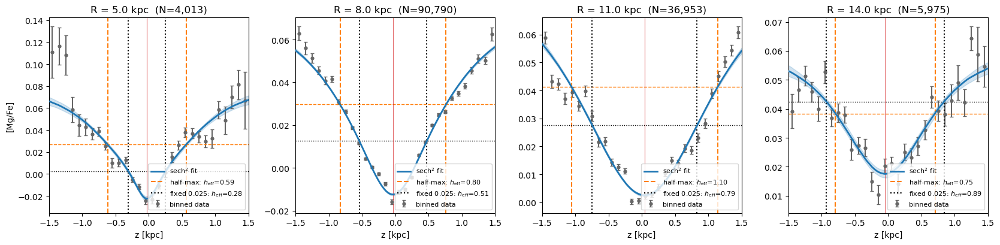

In [268]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq

R_to_plot = [5, 8, 11, 14]      # radial bin centers to show (must exist in per_R_flare)
DROP = 0.025                     # same fixed rise as the comparison plot
n_draws = 256
z_grid = np.linspace(-1.5, 1.5, 600)

def draw_params(s, i):
    cs = {k: v[i] for k, v in s.items()}
    cs["h2"] = cs["h1"] + cs["d_h2"]
    return cs

def crossings(cs):
    """Return (heff_half, level_half, heff_fixed, level_fixed), levels in the
    same units as model_y (offset included). NaN if no crossing."""
    peak = cs["A1"] + cs["A2"]                      # trough depth relative to baseline
    hi = 8 * max(cs["h1"], cs["h2"])
    def f_half(z):
        return mixture_of_sech2(z, cs["A1"], cs["A2"], cs["h1"], cs["h2"], cs["z0"]) - 0.5 * peak
    def f_fix(z):
        return mixture_of_sech2(z, cs["A1"], cs["A2"], cs["h1"], cs["h2"], cs["z0"]) - peak - DROP
    out = []
    for f, lvl in [(f_half, 0.5 * peak + cs["offset"]), (f_fix, peak + DROP + cs["offset"])]:
        try:
            out += [brentq(f, cs["z0"] + 1e-9, hi) - cs["z0"], lvl]
        except ValueError:
            out += [np.nan, np.nan]
    return out

fig, axes = plt.subplots(1, len(R_to_plot), figsize=(4.2 * len(R_to_plot), 4.2), sharex=True)
axes = np.atleast_1d(axes)

for ax, Rt in zip(axes, R_to_plot):
    i_R = int(np.argmin(np.abs(R_centers_flare - Rt)))
    if i_R not in per_R_flare:
        ax.set_title(f"R = {Rt} kpc: no fit"); continue
    cell = per_R_flare[i_R]; s = cell["samples"]
    n = min(n_draws, len(s["z0"]))

    curves, res = [], []
    for i in range(n):
        cs = draw_params(s, i)
        curves.append(mixture_of_sech2(z_grid, cs["A1"], cs["A2"], cs["h1"], cs["h2"], cs["z0"]) + cs["offset"])
        res.append(crossings(cs) + [cs["z0"]])
    curves = np.array(curves); res = np.array(res)
    heff_half, lvl_half, heff_fix, lvl_fix, z0s = np.nanmedian(res, axis=0)

    ax.errorbar(cell["z_binc"], cell["mean"], yerr=cell["err"], fmt="o", color="0.4",
                ms=3.5, capsize=2, label="binned data", zorder=2)
    lo, med, hi_ = np.percentile(curves, [16, 50, 84], axis=0)
    ax.fill_between(z_grid, lo, hi_, color="C0", alpha=0.2, zorder=1)
    ax.plot(z_grid, med, color="C0", lw=2, label="sech$^2$ fit", zorder=3)

    # half-max method
    ax.axhline(lvl_half, color="tab:orange", ls="--", lw=1)
    for sgn in (+1, -1):
        ax.axvline(z0s + sgn * heff_half, color="tab:orange", ls="--", lw=1.5,
                   label=f"half-max: $h_\\mathrm{{eff}}$={heff_half:.2f}" if sgn == 1 else None)
    # fixed-drop method
    ax.axhline(lvl_fix, color="k", ls=":", lw=1)
    for sgn in (+1, -1):
        ax.axvline(z0s + sgn * heff_fix, color="k", ls=":", lw=1.5,
                   label=f"fixed {DROP}: $h_\\mathrm{{eff}}$={heff_fix:.2f}" if sgn == 1 else None)

    ax.axvline(z0s, color="C3", lw=0.8, alpha=0.7)
    ax.set_title(f"R = {R_centers_flare[i_R]:.1f} kpc  (N={cell['n_stars']:,})")
    ax.set_xlabel("z [kpc]")
    ax.legend(fontsize=8, loc="lower right")

axes[0].set_ylabel("[Mg/Fe]")
axes[0].set_xlim(-1.5, 1.5)
plt.tight_layout()
plt.show()

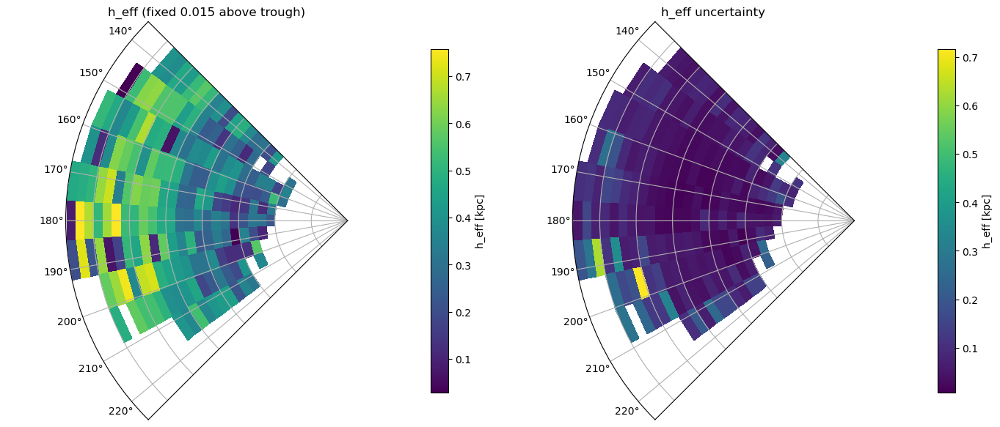

In [233]:
from scipy.optimize import brentq
import numpy as np

DROP = 0.015

def root_func_shifted(z, pars, drop=DROP):
    peak = pars["A1"] + pars["A2"]
    Ystar = mixture_of_sech2(z, pars["A1"], pars["A2"], pars["h1"], pars["h2"], pars["z0"])
    return (Ystar - peak) - drop

# ------------------------------------------------------------------
# Loop over every (R, segment) cell from your existing z0 grid fit
# (same per_cell MCMC results used to build the z0 heatmap)
# ------------------------------------------------------------------
n_R = len(R_edges) - 1
n_seg = len(SEG_PLOT_heat)

h_eff_med_grid = np.full((n_R, n_seg), np.nan)
h_eff_std_grid = np.full((n_R, n_seg), np.nan)

for (i_R, i_seg), cell in per_cell.items():
    if i_seg not in SEG_PLOT_heat:
        continue
    s = cell["samples"]
    n_draws = min(256, len(s["z0"]))
    h_effs = []
    for i in range(n_draws):
        cs = {k: v[i] for k, v in s.items()}
        cs["h2"] = cs["h1"] + cs["d_h2"]
        hi = 8 * max(cs["h1"], cs["h2"])
        try:
            zstar = brentq(root_func_shifted, cs["z0"] + 1e-9, hi, args=(cs,))
            h_effs.append(zstar - cs["z0"])
        except ValueError:
            continue
    if h_effs:
        h_effs = np.array(h_effs)
        j_seg = SEG_PLOT_heat.index(i_seg)
        h_eff_med_grid[i_R, j_seg] = np.median(h_effs)
        pcl = np.percentile(h_effs, [16, 84])
        h_eff_std_grid[i_R, j_seg] = 0.5 * (pcl[1] - pcl[0])

# ------------------------------------------------------------------
# Heatmap (same wedge/polar style as the z0 heatmap)
# ------------------------------------------------------------------
theta_edges = crowd_bounds  # boundary angles, len = n_seg+1

fig, (ax1, ax2) = plt.subplots(1, 2, subplot_kw={"projection": "polar"}, figsize=(14, 7))

for ax, grid, cmap, title, vmin, vmax in [
    (ax1, h_eff_med_grid, "viridis", f"h_eff (fixed {DROP} above trough)", None, None),
    (ax2, h_eff_std_grid, "viridis", "h_eff uncertainty", None, None),
]:
    pcm = ax.pcolormesh(theta_edges, R_edges, grid, cmap=cmap, vmin=vmin, vmax=vmax, shading="flat")
    ax.set_theta_zero_location("E")
    ax.set_theta_direction(1)
    ax.set_thetamin(np.rad2deg(theta_edges.min()))
    ax.set_thetamax(np.rad2deg(theta_edges.max()))
    ax.set_yticklabels([])
    ax.set_title(title)
    fig.colorbar(pcm, ax=ax, shrink=0.7, label="h_eff [kpc]")

plt.tight_layout()
plt.show()

In [234]:
# recenter angles on the Sun's azimuth (phi0), wrapped to stay monotonic
theta_edges = ((crowd_bounds - phi0 + np.pi) % (2*np.pi)) - np.pi  # now spans [-45°, +45°] around 0

fig, (ax1, ax2) = plt.subplots(1, 2, subplot_kw={"projection": "polar"}, figsize=(14, 7))

for ax, grid, cmap, title, vmin, vmax in [
    (ax1, h_eff_med_grid, "viridis", f"h_eff (fixed {DROP} above trough)", None, None),
    (ax2, h_eff_std_grid, "viridis", "h_eff uncertainty", None, None),
]:
    pcm = ax.pcolormesh(theta_edges, R_edges, grid, cmap=cmap, vmin=vmin, vmax=vmax, shading="flat")
    ax.set_theta_zero_location("E")
    ax.set_theta_direction(1)
    ax.set_thetamin(np.rad2deg(theta_edges.min()))
    ax.set_thetamax(np.rad2deg(theta_edges.max()))

    # force gridlines to sit exactly on the real segment boundaries
    ax.set_xticks(theta_edges)
    ax.set_xticklabels([f"{d:.0f}°" for d in np.rad2deg(theta_edges)])

    ax.set_yticklabels([])
    ax.set_title(title)
    fig.colorbar(pcm, ax=ax, shrink=0.7, label="h_eff [kpc]")

plt.tight_layout()
plt.show()

NameError: name 'phi0' is not defined

In [237]:
import numpy as np
plx, eplx = np.asarray(t_final["zgr_plx"], float), np.asarray(t_final["zgr_e_plx"], float)
print("min plx/e_plx in t_final:", np.nanmin(plx / eplx))
print("max e_plx/plx in t_final:", np.nanmax(eplx / plx))

min plx/e_plx in t_final: 1.229778408399078
max e_plx/plx in t_final: 0.8131546245813481


In [238]:
frac = eplx / plx
for cut in [0.1, 0.2, 0.3, 0.5]:
    print(f"frac err < {cut}: {np.sum(frac < cut)} / {np.sum(np.isfinite(frac))} "
          f"({100*np.mean(frac[np.isfinite(frac)] < cut):.1f}%)")

frac err < 0.1: 374017 / 391384 (95.6%)
frac err < 0.2: 388805 / 391384 (99.3%)
frac err < 0.3: 390867 / 391384 (99.9%)
frac err < 0.5: 391364 / 391384 (100.0%)
